In [1]:
# ============================================================
# SECTION 0 — INDEPENDENT REPRODUCTION WORKSPACE
# ============================================================
# This is a NEW run. It reads only the original master dataset.
# No model, prediction, calibration, or result is copied.
# The original study remains unchanged.

from google.colab import drive
from pathlib import Path
import os, shutil, hashlib

drive.mount('/content/drive')
ORIGINAL_INPUT_DIR = Path('/content/drive/MyDrive/GitReq_Research')
PROJECT_DIR = Path('/content/drive/MyDrive/GitReq_Reproduction_Run01')
SOURCE_MASTER = ORIGINAL_INPUT_DIR / 'data' / 'GitReq_Research_Master.csv'
DATA_DIR = PROJECT_DIR / 'data'
RESULTS_DIR = PROJECT_DIR / 'results'
MODELS_DIR = PROJECT_DIR / 'models'
DEST_MASTER = DATA_DIR / 'GitReq_Research_Master.csv'
EXPECTED_MASTER_SHA256 = 'ca8355197ed3b322561a17608af10bda9f732f09f1cb5e5c6427f5590fab75f1'

def master_hash(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(2**20),b''):
            h.update(block)
    return h.hexdigest()

if not SOURCE_MASTER.is_file():
    raise FileNotFoundError(f'Original master dataset missing: {SOURCE_MASTER}')
assert master_hash(SOURCE_MASTER) == EXPECTED_MASTER_SHA256, 'Source master fingerprint mismatch'
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
if DEST_MASTER.exists():
    assert master_hash(DEST_MASTER) == EXPECTED_MASTER_SHA256, 'Run master fingerprint mismatch'
else:
    shutil.copy2(SOURCE_MASTER, DEST_MASTER)
assert master_hash(DEST_MASTER) == EXPECTED_MASTER_SHA256
os.environ['GITREQ_PROJECT_DIR'] = str(PROJECT_DIR)
print('Independent reproduction:', PROJECT_DIR)
print('Input master SHA-256 verified')
print('Models and results will be produced inside this NEW folder.')
print('Do not copy original trained models or experimental outputs.')


Mounted at /content/drive
Independent reproduction: /content/drive/MyDrive/GitReq_Reproduction_Run01
Input master SHA-256 verified
Models and results will be produced inside this NEW folder.
Do not copy original trained models or experimental outputs.


In [2]:

# ============================================================
# GITREQ RESEARCH
# SECTION 1 — ENVIRONMENT SETUP
# ============================================================

from google.colab import drive
import os
from pathlib import Path
import pandas as pd
import numpy as np
import sklearn
import hashlib
import json
import platform

# 1. Connect Google Drive
drive.mount("/content/drive")

# 2. Define project folders
PROJECT_DIR = Path(os.environ.get("GITREQ_PROJECT_DIR", "/content/drive/MyDrive/GitReq_Reproduction_Run01"))

DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
MODELS_DIR = PROJECT_DIR / "models"

for folder in [DATA_DIR, RESULTS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# 3. Dataset path
DATASET_PATH = DATA_DIR / "GitReq_Research_Master.csv"

# 4. Reproducibility settings
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# 5. Record environment information
environment = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "random_state": RANDOM_STATE
}

with open(RESULTS_DIR / "environment.json", "w") as f:
    json.dump(environment, f, indent=4)

# 6. Check dataset availability and integrity
print("Environment:", environment)
print("Dataset found:", DATASET_PATH.exists())

if DATASET_PATH.exists():
    dataset_hash = hashlib.sha256(
        DATASET_PATH.read_bytes()
    ).hexdigest()

    print("Dataset SHA-256:", dataset_hash)

    expected_hash = (
        "ca8355197ed3b322561a17608af10bda"
        "9f732f09f1cb5e5c6427f5590fab75f1"
    )

    assert dataset_hash == expected_hash, "Original master SHA-256 mismatch"
    print("Original dataset verified: True")
else:
    raise FileNotFoundError(f"Missing original master: {DATASET_PATH}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Environment: {'python': '3.13.16', 'pandas': '2.2.3', 'numpy': '2.1.3', 'scikit_learn': '1.6.1', 'random_state': 42}
Dataset found: True
Dataset SHA-256: ca8355197ed3b322561a17608af10bda9f732f09f1cb5e5c6427f5590fab75f1
Original dataset verified: True


In [3]:

# ============================================================
# GITREQ RESEARCH
# SECTION 2 — DATASET LOADING AND VERIFICATION
# ============================================================

import pandas as pd
import json
import re
from IPython.display import display

# ------------------------------------------------------------
# 1. Load dataset
# ------------------------------------------------------------

df = pd.read_csv(DATASET_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# ------------------------------------------------------------
# 2. Verify expected columns
# ------------------------------------------------------------

expected_columns = [
    "requirement_id",
    "RequirementText",
    "class_label",
    "url",
    "repository_id",
    "issue_number",
    "source_dataset",
    "source_row_id"
]

assert list(df.columns) == expected_columns, \
    "Unexpected dataset columns!"

print("\nColumns verified:")
for column in df.columns:
    print("-", column)

# ------------------------------------------------------------
# 3. Verify record counts and labels
# ------------------------------------------------------------

expected_counts = {
    "Security": 1646,
    "Performance": 1509,
    "Portability": 1284,
    "Availability": 738,
    "Functional": 531,
    "Fault-tolerance": 293,
    "Scalability": 157,
    "Maintainability": 144
}

class_counts = df["class_label"].value_counts()

assert len(df) == 6302, "Unexpected record count!"
assert class_counts.to_dict() == expected_counts, \
    "Class distribution differs from the published dataset!"

print("\nClass distribution:")
display(
    class_counts.rename_axis("Category")
    .reset_index(name="Count")
)

# ------------------------------------------------------------
# 4. Verify missing and empty values
# ------------------------------------------------------------

missing_values = df.isna().sum()
empty_text_count = (
    df["RequirementText"].fillna("")
    .astype(str).str.strip().eq("").sum()
)

print("\nMissing values:")
print(missing_values)

print("\nEmpty requirements:", empty_text_count)

assert missing_values.sum() == 0, \
    "Missing values detected!"

assert empty_text_count == 0, \
    "Empty requirement text detected!"

# ------------------------------------------------------------
# 5. Verify requirement identifiers
# ------------------------------------------------------------

duplicate_ids = df["requirement_id"].duplicated().sum()

assert duplicate_ids == 0, \
    "Duplicate requirement IDs detected!"

print("\nUnique requirement IDs:",
      df["requirement_id"].nunique())

# ------------------------------------------------------------
# 6. Verify GitHub source information
# ------------------------------------------------------------

github_pattern = re.compile(
    r"https://github\.com/([^/]+)/([^/]+)/issues/([0-9]+)",
    re.IGNORECASE
)

invalid_source_rows = []

for row in df.itertuples(index=False):

    match = github_pattern.fullmatch(row.url)

    if match is None:
        invalid_source_rows.append(row.requirement_id)
        continue

    extracted_repo = (
        match.group(1) + "/" + match.group(2)
    ).lower()

    extracted_issue = int(match.group(3))

    if (
        extracted_repo != row.repository_id
        or extracted_issue != row.issue_number
    ):
        invalid_source_rows.append(row.requirement_id)

assert len(invalid_source_rows) == 0, \
    "Invalid or inconsistent GitHub source metadata!"

unique_repositories = df["repository_id"].nunique()
unique_issues = df["url"].nunique()

print("\nUnique repositories:", unique_repositories)
print("Unique GitHub issues:", unique_issues)
print("Invalid source rows:", len(invalid_source_rows))

# ------------------------------------------------------------
# 7. Verify FR/NFR source mapping
# ------------------------------------------------------------

source_distribution = pd.crosstab(
    df["source_dataset"],
    df["class_label"]
)

print("\nFR/NFR source distribution:")
display(source_distribution)

assert set(df["source_dataset"]) == {"FR", "NFR"}

assert (
    df.loc[df["source_dataset"] == "FR", "class_label"]
    == "Functional"
).all()

assert (
    df.loc[df["source_dataset"] == "NFR", "class_label"]
    != "Functional"
).all()

# ------------------------------------------------------------
# 8. Repository statistics
# ------------------------------------------------------------

repository_counts = (
    df["repository_id"]
    .value_counts()
    .rename_axis("repository_id")
    .reset_index(name="requirement_count")
)

single_requirement_repos = (
    repository_counts["requirement_count"] == 1
).sum()

print("\nRepositories with one requirement:",
      single_requirement_repos)

print("\nTop 10 repositories by requirement count:")
display(repository_counts.head(10))

# ------------------------------------------------------------
# 9. Save verification results
# ------------------------------------------------------------

audit_summary = {
    "total_requirements": int(len(df)),
    "total_categories": int(df["class_label"].nunique()),
    "unique_repositories": int(unique_repositories),
    "unique_issues": int(unique_issues),
    "duplicate_requirement_ids": int(duplicate_ids),
    "empty_requirements": int(empty_text_count),
    "invalid_source_rows": int(len(invalid_source_rows)),
    "class_distribution": {
        key: int(value)
        for key, value in class_counts.items()
    }
}

with open(
    RESULTS_DIR / "dataset_structure_audit.json", "w"
) as f:
    json.dump(audit_summary, f, indent=4)

repository_counts.to_csv(
    RESULTS_DIR / "repository_distribution.csv",
    index=False
)

class_counts.rename_axis("class_label").to_csv(
    RESULTS_DIR / "class_distribution.csv"
)

print("\n========================================")
print("SECTION 2 VERIFICATION COMPLETED")
print("========================================")
print("Total requirements:", len(df))
print("Total classes:", df["class_label"].nunique())
print("Total repositories:", unique_repositories)
print("Total GitHub issues:", unique_issues)
print("Audit results saved to Google Drive.")


Dataset loaded successfully!
Dataset shape: (6302, 8)

Columns verified:
- requirement_id
- RequirementText
- class_label
- url
- repository_id
- issue_number
- source_dataset
- source_row_id

Class distribution:


,Category,Count
0,Security,1646
1,Performance,1509
2,Portability,1284
3,Availability,738
4,Functional,531
5,Fault-tolerance,293
6,Scalability,157
7,Maintainability,144



Missing values:
requirement_id     0
RequirementText    0
class_label        0
url                0
repository_id      0
issue_number       0
source_dataset     0
source_row_id      0
dtype: int64

Empty requirements: 0

Unique requirement IDs: 6302

Unique repositories: 4080
Unique GitHub issues: 6140
Invalid source rows: 0

FR/NFR source distribution:


class_label,Availability,Fault-tolerance,Functional,Maintainability,Performance,Portability,Scalability,Security
source_dataset,,,,,,,,
FR,0,0,531,0,0,0,0,0
NFR,738,293,0,144,1509,1284,157,1646



Repositories with one requirement: 3241

Top 10 repositories by requirement count:


,repository_id,requirement_count
0,dmwm/wmcore,46
1,mcguiretechnology/truledgr,40
2,networkupstools/nut,40
3,yeraze/meshmonitor,31
4,nickna/conduit,28
5,ivorysql/ivorysql,25
6,rapidsai/cudf,22
7,zowe/zowe-install-packaging,21
8,arii/hrm,21
9,argoproj/argo-cd,18



SECTION 2 VERIFICATION COMPLETED
Total requirements: 6302
Total classes: 8
Total repositories: 4080
Total GitHub issues: 6140
Audit results saved to Google Drive.


In [4]:

# ============================================================
# GITREQ RESEARCH
# SECTION 3 — DATASET QUALITY AUDIT
# ============================================================

import pandas as pd
import numpy as np
import re
import json

from sklearn.feature_extraction.text import TfidfVectorizer
from IPython.display import display

print("=" * 55)
print("SECTION 3 — DATASET QUALITY AUDIT")
print("=" * 55)

# ------------------------------------------------------------
# 1. Preserve the original dataset
# ------------------------------------------------------------

audit_df = df.copy()

original_count = len(audit_df)

# Normalize only for comparison, not for model training.
normalized_text = (
    audit_df["RequirementText"]
    .astype(str)
    .str.casefold()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("\nOriginal requirements:", original_count)

# ------------------------------------------------------------
# 2. Exact and normalized duplicates
# ------------------------------------------------------------

exact_duplicate_mask = (
    audit_df["RequirementText"].duplicated(keep=False)
)

normalized_duplicate_mask = (
    normalized_text.duplicated(keep=False)
)

print("\n--- DUPLICATE ANALYSIS ---")

print(
    "Rows with exact duplicate text:",
    int(exact_duplicate_mask.sum())
)

print(
    "Rows with normalized duplicate text:",
    int(normalized_duplicate_mask.sum())
)

normalized_duplicates = audit_df.loc[
    normalized_duplicate_mask,
    [
        "requirement_id",
        "RequirementText",
        "class_label",
        "repository_id"
    ]
]

display(normalized_duplicates)

# ------------------------------------------------------------
# 3. Suspicious placeholder text
# ------------------------------------------------------------

placeholder_pattern = (
    r"(?i)^#(?:NAME\?|REF!|DIV/0!|VALUE!|"
    r"N/A|NUM!|NULL!)$"
)

placeholder_mask = normalized_text.str.match(
    placeholder_pattern
)

print("\n--- SUSPICIOUS PLACEHOLDERS ---")

print(
    "Suspicious placeholder records:",
    int(placeholder_mask.sum())
)

display(
    audit_df.loc[
        placeholder_mask,
        [
            "requirement_id",
            "RequirementText",
            "class_label",
            "url"
        ]
    ]
)

# ------------------------------------------------------------
# 4. Requirement length analysis
# ------------------------------------------------------------

word_counts = (
    audit_df["RequirementText"]
    .astype(str)
    .str.split()
    .str.len()
)

short_text_mask = word_counts <= 2

print("\n--- REQUIREMENT LENGTH ---")

print("Minimum words:", int(word_counts.min()))
print("Median words:", float(word_counts.median()))
print("Mean words:", round(float(word_counts.mean()), 2))
print("Maximum words:", int(word_counts.max()))

print(
    "Requirements with 2 or fewer words:",
    int(short_text_mask.sum())
)

display(
    audit_df.loc[
        short_text_mask,
        ["requirement_id", "RequirementText", "class_label"]
    ].head(15)
)

# ------------------------------------------------------------
# 5. Multiple categories from the same GitHub issue
# ------------------------------------------------------------

issue_summary = (
    audit_df.groupby("url")
    .agg(
        requirement_count=("requirement_id", "size"),
        category_count=("class_label", "nunique")
    )
    .reset_index()
)

mixed_category_issues = issue_summary.loc[
    issue_summary["category_count"] > 1
].copy()

print("\n--- MIXED-CATEGORY GITHUB ISSUES ---")

print(
    "Issues associated with multiple categories:",
    len(mixed_category_issues)
)

display(mixed_category_issues.head(15))

# ------------------------------------------------------------
# 6. Explicit category markers inside requirements
# ------------------------------------------------------------

category_names = sorted(
    audit_df["class_label"].unique(),
    key=len,
    reverse=True
)

category_regex = "|".join(
    re.escape(name) for name in category_names
)

marker_pattern = (
    rf"(?i)\b(?:type|label|category)\s*:\s*"
    rf"(?:{category_regex})\b"
)

marker_mask = (
    audit_df["RequirementText"]
    .astype(str)
    .str.contains(marker_pattern, regex=True)
)

print("\n--- EXPLICIT CATEGORY MARKERS ---")

print(
    "Requirements containing category-like metadata:",
    int(marker_mask.sum())
)

marker_examples = audit_df.loc[
    marker_mask,
    ["requirement_id", "RequirementText", "class_label"]
].head(10).copy()

marker_examples["RequirementText"] = (
    marker_examples["RequirementText"].str.slice(0, 160)
)

display(marker_examples)

# ------------------------------------------------------------
# 7. Near-duplicate detection
# ------------------------------------------------------------

print("\n--- NEAR-DUPLICATE ANALYSIS ---")

print("Creating character n-gram representations...")

vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    lowercase=False,
    dtype=np.float32
)

X_similarity = vectorizer.fit_transform(
    normalized_text
)

similarity_threshold = 0.90
batch_size = 100

near_duplicate_records = []

print("Comparing requirement similarity...")

# Compare in batches to avoid creating one dense
# 6302 x 6302 similarity matrix.

for start in range(0, original_count, batch_size):

    end = min(start + batch_size, original_count)

    similarities = (
        X_similarity[start:end] @ X_similarity.T
    ).tocoo()

    row_indices = similarities.row + start

    valid_pairs = (
        (similarities.data >= similarity_threshold)
        & (similarities.col > row_indices)
    )

    for i, j, score in zip(
        row_indices[valid_pairs],
        similarities.col[valid_pairs],
        similarities.data[valid_pairs]
    ):

        row_a = audit_df.iloc[int(i)]
        row_b = audit_df.iloc[int(j)]

        near_duplicate_records.append({
            "requirement_id_1": row_a["requirement_id"],
            "requirement_id_2": row_b["requirement_id"],
            "similarity": round(float(score), 6),
            "label_1": row_a["class_label"],
            "label_2": row_b["class_label"],
            "same_label": (
                row_a["class_label"] == row_b["class_label"]
            ),
            "same_repository": (
                row_a["repository_id"]
                == row_b["repository_id"]
            ),
            "text_1": row_a["RequirementText"],
            "text_2": row_b["RequirementText"]
        })

near_duplicates = pd.DataFrame(
    near_duplicate_records,
    columns=[
        "requirement_id_1",
        "requirement_id_2",
        "similarity",
        "label_1",
        "label_2",
        "same_label",
        "same_repository",
        "text_1",
        "text_2"
    ]
)

near_duplicates = near_duplicates.sort_values(
    "similarity",
    ascending=False
).reset_index(drop=True)

conflicting_pairs = int(
    (~near_duplicates["same_label"]).sum()
)

cross_repository_pairs = int(
    (~near_duplicates["same_repository"]).sum()
)

print(
    "\nNear-duplicate candidate pairs:",
    len(near_duplicates)
)

print(
    "Pairs with different labels:",
    conflicting_pairs
)

print(
    "Pairs from different repositories:",
    cross_repository_pairs
)

display(
    near_duplicates.drop(
        columns=["text_1", "text_2"]
    ).head(15)
)

# ------------------------------------------------------------
# 8. Collect records requiring manual inspection
# ------------------------------------------------------------

quality_flags = pd.DataFrame({
    "requirement_id": audit_df["requirement_id"],
    "placeholder": placeholder_mask,
    "short_text": short_text_mask,
    "explicit_category_marker": marker_mask,
    "normalized_duplicate": normalized_duplicate_mask
})

flag_columns = [
    "placeholder",
    "short_text",
    "explicit_category_marker",
    "normalized_duplicate"
]

flagged_records = quality_flags.loc[
    quality_flags[flag_columns].any(axis=1)
].copy()

flagged_records = flagged_records.merge(
    audit_df[
        [
            "requirement_id",
            "RequirementText",
            "class_label",
            "repository_id",
            "url"
        ]
    ],
    on="requirement_id",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 9. Save audit artifacts
# ------------------------------------------------------------

near_duplicates.to_csv(
    RESULTS_DIR / "near_duplicate_candidates.csv",
    index=False
)

mixed_category_issues.to_csv(
    RESULTS_DIR / "mixed_category_issues.csv",
    index=False
)

flagged_records.to_csv(
    RESULTS_DIR / "flagged_requirements.csv",
    index=False
)

audit_report = {
    "original_requirements": int(original_count),
    "exact_duplicate_rows": int(exact_duplicate_mask.sum()),
    "normalized_duplicate_rows": int(
        normalized_duplicate_mask.sum()
    ),
    "placeholder_records": int(placeholder_mask.sum()),
    "short_text_records": int(short_text_mask.sum()),
    "explicit_category_marker_records": int(
        marker_mask.sum()
    ),
    "mixed_category_issue_count": int(
        len(mixed_category_issues)
    ),
    "near_duplicate_threshold": similarity_threshold,
    "near_duplicate_candidate_pairs": int(
        len(near_duplicates)
    ),
    "near_duplicate_conflicting_label_pairs": (
        conflicting_pairs
    ),
    "near_duplicate_cross_repository_pairs": (
        cross_repository_pairs
    ),
    "total_flagged_records": int(len(flagged_records)),
    "records_removed": 0
}

with open(
    RESULTS_DIR / "dataset_quality_audit.json", "w"
) as f:
    json.dump(audit_report, f, indent=4)

# ------------------------------------------------------------
# 10. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("SECTION 3 — AUDIT SUMMARY")
print("=" * 55)

for key, value in audit_report.items():
    print(f"{key}: {value}")

print("\nOriginal dataset preserved.")
print("No records removed.")
print("Quality audit artifacts saved to Google Drive.")
print("=" * 55)


SECTION 3 — DATASET QUALITY AUDIT

Original requirements: 6302

--- DUPLICATE ANALYSIS ---
Rows with exact duplicate text: 0
Rows with normalized duplicate text: 2


,requirement_id,RequirementText,class_label,repository_id
2308,GR02309,Refactor plugin filtering and workflow prompt ...,Maintainability,flowsynx/flowsynx
4874,GR04875,Refactor plugin filtering and workflow prompt ...,Maintainability,flowsynx/flowsynx



--- SUSPICIOUS PLACEHOLDERS ---
Suspicious placeholder records: 1


,requirement_id,RequirementText,class_label,url
2579,GR02580,#NAME?,Availability,https://github.com/euzu/tuliprox/issues/191



--- REQUIREMENT LENGTH ---
Minimum words: 1
Median words: 52.0
Mean words: 52.47
Maximum words: 95
Requirements with 2 or fewer words: 1


...


--- EXPLICIT CATEGORY MARKERS ---
Requirements containing category-like metadata: 51


,requirement_id,RequirementText,class_label
1,GR00002,feat(api): implement Decentralized Identity Ma...,Security
252,GR00253,feat(api): implement Security Testing Automati...,Security
376,GR00377,Likely I would want to aggregate the percent i...,Performance
529,GR00530,Implement Security Measures for Profile Manage...,Security
531,GR00532,feat(api): implement Account Security Features...,Security
638,GR00639,feat(api): implement Mobile Security Hardening...,Security
890,GR00891,feat(api): implement Secure File Upload and Pr...,Security
1014,GR01015,This can be slow if there are many maps. Linu...,Performance
1280,GR01281,feat(api): implement Anti-Money Laundering (AM...,Security
1317,GR01318,feat(api): implement Content Security Policy (...,Security



--- NEAR-DUPLICATE ANALYSIS ---
Creating character n-gram representations...
Comparing requirement similarity...

Near-duplicate candidate pairs: 31
Pairs with different labels: 1
Pairs from different repositories: 0


,requirement_id_1,requirement_id_2,similarity,label_1,label_2,same_label,same_repository
0,GR02309,GR04875,1.000001,Maintainability,Maintainability,True,True
1,GR03686,GR04436,1.000000,Maintainability,Maintainability,True,True
2,GR02967,GR03511,0.994963,Fault-tolerance,Fault-tolerance,True,True
3,GR00645,GR02244,0.987767,Fault-tolerance,Fault-tolerance,True,True
4,GR01790,GR02988,0.987151,Maintainability,Maintainability,True,True
5,GR01189,GR03416,0.984885,Fault-tolerance,Fault-tolerance,True,True
6,GR03437,GR05658,0.984536,Maintainability,Maintainability,True,True
7,GR00121,GR00137,0.984360,Maintainability,Maintainability,True,True
8,GR02462,GR02875,0.983622,Scalability,Scalability,True,True
9,GR02129,GR05040,0.983119,Maintainability,Maintainability,True,True



SECTION 3 — AUDIT SUMMARY
original_requirements: 6302
exact_duplicate_rows: 0
normalized_duplicate_rows: 2
placeholder_records: 1
short_text_records: 1
explicit_category_marker_records: 51
mixed_category_issue_count: 9
near_duplicate_threshold: 0.9
near_duplicate_candidate_pairs: 31
near_duplicate_conflicting_label_pairs: 1
near_duplicate_cross_repository_pairs: 0
total_flagged_records: 54
records_removed: 0

Original dataset preserved.
No records removed.
Quality audit artifacts saved to Google Drive.


In [5]:

# ============================================================
# GITREQ RESEARCH
# SECTION 3B — DOCUMENTED DATASET CLEANING
# ============================================================

import pandas as pd
import json
import hashlib

print("=" * 55)
print("SECTION 3B — DOCUMENTED DATASET CLEANING")
print("=" * 55)

# ------------------------------------------------------------
# 1. Preserve the original master dataset
# ------------------------------------------------------------

clean_df = df.copy()

original_count = len(clean_df)

assert original_count == 6302

assert clean_df["requirement_id"].is_unique

# ------------------------------------------------------------
# 2. Verify the records selected for exclusion
# ------------------------------------------------------------

records_by_id = clean_df.set_index("requirement_id")

placeholder_id = "GR02580"
duplicate_keep_id = "GR02309"
duplicate_remove_id = "GR04875"

# Confirm that the suspected placeholder is correct.
assert (
    records_by_id.loc[placeholder_id, "RequirementText"]
    .strip() == "#NAME?"
), "Placeholder record does not match the audit!"

# Confirm the duplicate pair before removing anything.
def normalize_requirement(text):
    return " ".join(str(text).casefold().split())

keep_record = records_by_id.loc[duplicate_keep_id]
remove_record = records_by_id.loc[duplicate_remove_id]

assert normalize_requirement(
    keep_record["RequirementText"]
) == normalize_requirement(
    remove_record["RequirementText"]
), "Duplicate texts do not match!"

assert (
    keep_record["class_label"]
    == remove_record["class_label"]
), "Duplicate labels differ!"

assert (
    keep_record["repository_id"]
    == remove_record["repository_id"]
), "Duplicate repositories differ!"

print("\nExclusion candidates verified.")

# ------------------------------------------------------------
# 3. Record exclusion reasons
# ------------------------------------------------------------

exclusion_reasons = {
    placeholder_id: (
        "Invalid placeholder: text contains only #NAME?"
    ),
    duplicate_remove_id: (
        "Normalized duplicate of GR02309 "
        "with same class and repository"
    )
}

excluded_records = clean_df.loc[
    clean_df["requirement_id"].isin(exclusion_reasons)
].copy()

excluded_records["exclusion_reason"] = (
    excluded_records["requirement_id"]
    .map(exclusion_reasons)
)

assert len(excluded_records) == 2

# ------------------------------------------------------------
# 4. Create cleaned dataset
# ------------------------------------------------------------

clean_df = clean_df.loc[
    ~clean_df["requirement_id"].isin(exclusion_reasons)
].copy()

clean_df.reset_index(drop=True, inplace=True)

assert len(clean_df) == 6300

assert clean_df["requirement_id"].is_unique

# Confirm that no further normalized duplicates remain.
normalized_clean = (
    clean_df["RequirementText"]
    .map(normalize_requirement)
)

assert not normalized_clean.duplicated().any(), (
    "Additional normalized duplicates detected!"
)

# ------------------------------------------------------------
# 5. Save processed data and exclusion log
# ------------------------------------------------------------

PROCESSED_DIR = DATA_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

CLEANED_DATASET_PATH = (
    PROCESSED_DIR / "GitReq_Research_Cleaned.csv"
)

EXCLUSIONS_PATH = (
    RESULTS_DIR / "excluded_requirements.csv"
)

clean_df.to_csv(
    CLEANED_DATASET_PATH,
    index=False,
    encoding="utf-8"
)

excluded_records.to_csv(
    EXCLUSIONS_PATH,
    index=False,
    encoding="utf-8"
)

# ------------------------------------------------------------
# 6. Record reproducibility information
# ------------------------------------------------------------

cleaned_hash = hashlib.sha256(
    CLEANED_DATASET_PATH.read_bytes()
).hexdigest()

cleaning_report = {
    "original_requirements": int(original_count),
    "cleaned_requirements": int(len(clean_df)),
    "removed_requirements": int(len(excluded_records)),
    "removed_requirement_ids": list(
        exclusion_reasons.keys()
    ),
    "exclusion_reasons": exclusion_reasons,
    "labels_modified": 0,
    "cleaned_dataset_sha256": cleaned_hash,
    "cleaned_dataset_path": str(CLEANED_DATASET_PATH)
}

with open(
    RESULTS_DIR / "dataset_cleaning_report.json", "w"
) as f:
    json.dump(cleaning_report, f, indent=4)

# ------------------------------------------------------------
# 7. Verify category distribution
# ------------------------------------------------------------

before_counts = df["class_label"].value_counts()
after_counts = clean_df["class_label"].value_counts()

comparison = pd.DataFrame({
    "Before": before_counts,
    "After": after_counts
}).fillna(0).astype(int)

comparison["Removed"] = (
    comparison["Before"] - comparison["After"]
)

print("\nCategory distribution after cleaning:")
display(comparison)

print("\nExcluded records:")
display(
    excluded_records[
        [
            "requirement_id",
            "RequirementText",
            "class_label",
            "repository_id",
            "exclusion_reason"
        ]
    ]
)

# ------------------------------------------------------------
# 8. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("SECTION 3B — CLEANING COMPLETED")
print("=" * 55)

print("Original records:", original_count)
print("Removed records:", len(excluded_records))
print("Cleaned records:", len(clean_df))
print("Categories:", clean_df["class_label"].nunique())
print("Repositories:", clean_df["repository_id"].nunique())
print("Labels modified: 0")

print("\nCleaned dataset saved to:")
print(CLEANED_DATASET_PATH)

print("\nSHA-256:")
print(cleaned_hash)

print("\nOriginal master dataset remains unchanged.")
print("=" * 55)


SECTION 3B — DOCUMENTED DATASET CLEANING

Exclusion candidates verified.

Category distribution after cleaning:


,Before,After,Removed
class_label,,,
Security,1646,1646,0
Performance,1509,1509,0
Portability,1284,1284,0
Availability,738,737,1
Functional,531,531,0
Fault-tolerance,293,293,0
Scalability,157,157,0
Maintainability,144,143,1



Excluded records:


,requirement_id,RequirementText,class_label,repository_id,exclusion_reason
2579,GR02580,#NAME?,Availability,euzu/tuliprox,Invalid placeholder: text contains only #NAME?
4874,GR04875,Refactor plugin filtering and workflow prompt ...,Maintainability,flowsynx/flowsynx,Normalized duplicate of GR02309 with same clas...



SECTION 3B — CLEANING COMPLETED
Original records: 6302
Removed records: 2
Cleaned records: 6300
Categories: 8
Repositories: 4079
Labels modified: 0

Cleaned dataset saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/data/processed/GitReq_Research_Cleaned.csv

SHA-256:
117e2438897c12cec3cd9aa144359bdf0a72950ef57caeb40eb83866d6f9cd6e

Original master dataset remains unchanged.


SECTION 4 — EXPLORATORY DATA ANALYSIS

Cleaned dataset loaded.
Shape: (6300, 8)

--- REQUIREMENT LENGTH STATISTICS ---


,word_count,character_count
count,6300.00,6300.00
mean,52.48,345.23
std,16.40,114.21
min,9.00,62.00
25%,40.00,262.00
50%,52.00,347.00
75%,66.00,429.00
max,95.00,712.00



--- CATEGORY DISTRIBUTION ---


,category,count,percentage
0,Security,1646,26.13
1,Performance,1509,23.95
2,Portability,1284,20.38
3,Availability,737,11.70
4,Functional,531,8.43
5,Fault-tolerance,293,4.65
6,Scalability,157,2.49
7,Maintainability,143,2.27


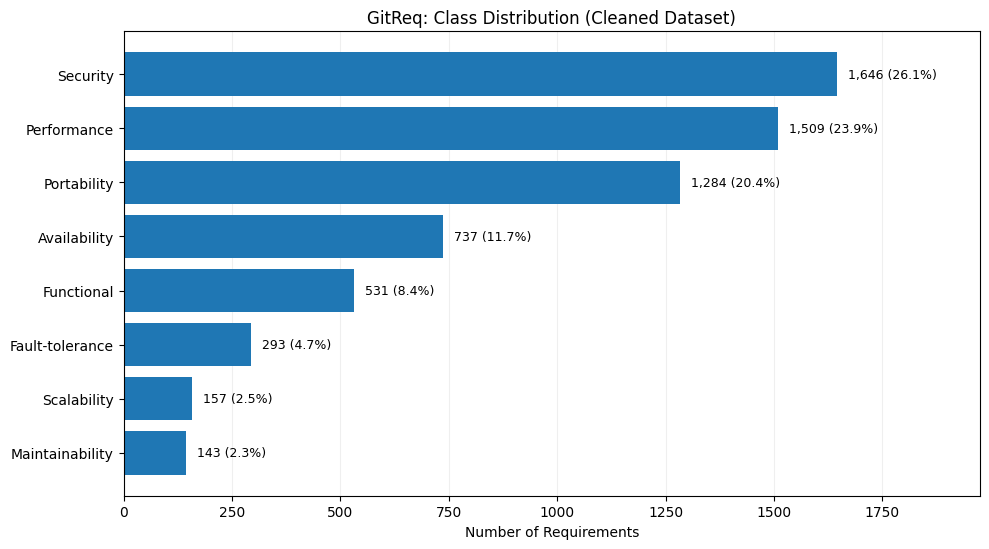


--- WORD LENGTH BY CATEGORY ---


,class_label,count,mean,median,min,max
0,Availability,737,41.79,42.0,26,50
1,Fault-tolerance,293,40.29,36.0,9,79
2,Functional,531,29.48,28.0,15,66
3,Maintainability,143,42.60,41.0,11,77
4,Performance,1509,63.88,66.0,20,87
5,Portability,1284,49.37,51.0,25,70
6,Scalability,157,34.66,28.0,10,95
7,Security,1646,61.39,63.0,24,82


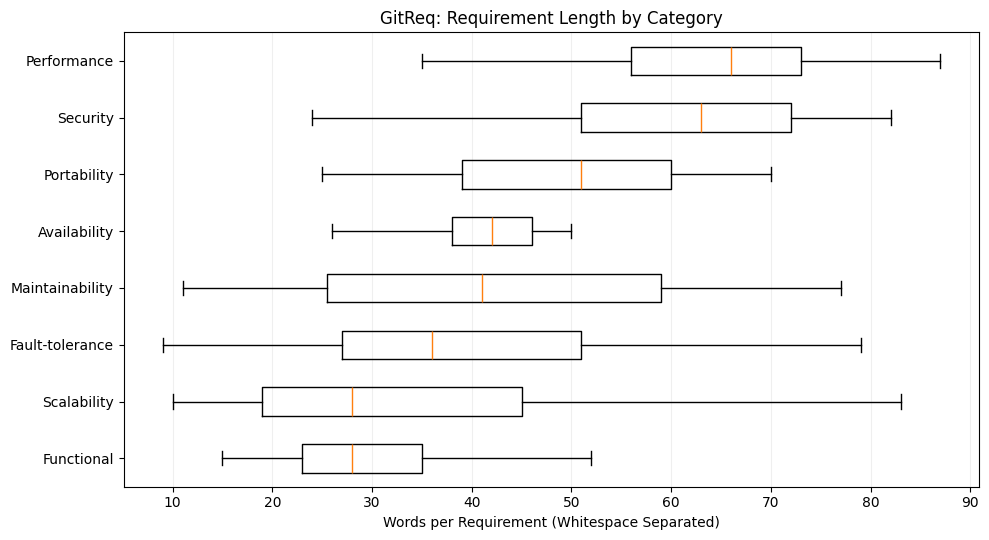


--- REPOSITORY SIZE DISTRIBUTION ---


,requirements_per_repository,repository_count
0,1,3240
1,2,465
2,3-5,271
3,6-10,65
4,11+,38


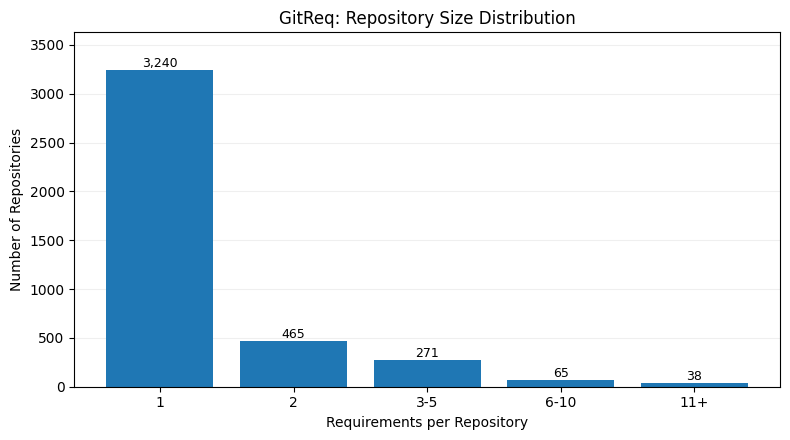


--- SOURCE DATASET COUNTS ---


,source,requirements
0,NFR,5769
1,FR,531



Unique GitHub issues: 6139
Issues containing multiple requirements: 101

SECTION 4 — EDA COMPLETED
dataset: GitReq_Research_Cleaned.csv
total_requirements: 6300
categories: 8
repositories: 4079
unique_issues: 6139
median_word_count: 52.0
mean_word_count: 52.48
single_requirement_repositories: 3240
issues_with_multiple_requirements: 101
source_counts: {'NFR': 5769, 'FR': 531}
records_removed_during_eda: 0

Research figures saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/results/figures

Research tables and EDA report saved.
No records or original labels modified.


In [6]:

# ============================================================
# GITREQ RESEARCH
# SECTION 4 — EXPLORATORY DATA ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

from IPython.display import display

print("=" * 55)
print("SECTION 4 — EXPLORATORY DATA ANALYSIS")
print("=" * 55)

# ------------------------------------------------------------
# 1. Load the cleaned dataset
# ------------------------------------------------------------

CLEANED_DATASET_PATH = (
    DATA_DIR / "processed" / "GitReq_Research_Cleaned.csv"
)

eda_df = pd.read_csv(CLEANED_DATASET_PATH)

assert len(eda_df) == 6300
assert eda_df["requirement_id"].is_unique
assert eda_df["class_label"].nunique() == 8
assert eda_df["repository_id"].nunique() == 4079
assert not eda_df["RequirementText"].isna().any()

FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("\nCleaned dataset loaded.")
print("Shape:", eda_df.shape)

# ------------------------------------------------------------
# 2. Calculate descriptive text lengths
# ------------------------------------------------------------

eda_df["word_count"] = (
    eda_df["RequirementText"]
    .astype(str)
    .str.split()
    .str.len()
)

eda_df["character_count"] = (
    eda_df["RequirementText"]
    .astype(str)
    .str.len()
)

print("\n--- REQUIREMENT LENGTH STATISTICS ---")

display(
    eda_df[
        ["word_count", "character_count"]
    ].describe().round(2)
)

# ------------------------------------------------------------
# 3. Class distribution
# ------------------------------------------------------------

category_counts = (
    eda_df["class_label"].value_counts()
)

category_summary = pd.DataFrame({
    "count": category_counts,
    "percentage": (
        category_counts / len(eda_df) * 100
    )
}).rename_axis("category").reset_index()

category_summary["percentage"] = (
    category_summary["percentage"].round(2)
)

print("\n--- CATEGORY DISTRIBUTION ---")

display(category_summary)

# ------------------------------------------------------------
# 4. Figure 1 — Class distribution
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5.6))

y_positions = np.arange(len(category_summary))

ax.barh(
    y_positions,
    category_summary["count"].to_numpy()
)

ax.set_yticks(y_positions)
ax.set_yticklabels(category_summary["category"])
ax.invert_yaxis()

ax.set_xlim(
    0,
    category_summary["count"].max() * 1.20
)

for pos, (count, percentage) in enumerate(
    zip(
        category_summary["count"],
        category_summary["percentage"]
    )
):
    ax.text(
        count + 25,
        pos,
        f"{count:,} ({percentage:.1f}%)",
        va="center",
        fontsize=9
    )

ax.set_xlabel("Number of Requirements")
ax.set_title(
    "GitReq: Class Distribution (Cleaned Dataset)"
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "figure_01_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. Requirement length by category
# ------------------------------------------------------------

length_summary = (
    eda_df.groupby("class_label")["word_count"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
    .reset_index()
)

print("\n--- WORD LENGTH BY CATEGORY ---")

display(length_summary)

# ------------------------------------------------------------
# 6. Figure 2 — Word length distribution
# ------------------------------------------------------------

ordered_categories = (
    length_summary
    .sort_values("median")["class_label"]
    .tolist()
)

length_data = [
    eda_df.loc[
        eda_df["class_label"] == category,
        "word_count"
    ].to_numpy()
    for category in ordered_categories
]

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.boxplot(
    length_data,
    vert=False,
    showfliers=False
)

ax.set_yticks(
    range(1, len(ordered_categories) + 1)
)

ax.set_yticklabels(ordered_categories)

ax.set_xlabel(
    "Words per Requirement (Whitespace Separated)"
)

ax.set_title(
    "GitReq: Requirement Length by Category"
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "figure_02_length_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 7. Repository distribution
# ------------------------------------------------------------

repository_sizes = (
    eda_df["repository_id"].value_counts()
)

repository_size_bins = pd.cut(
    repository_sizes,
    bins=[0, 1, 2, 5, 10, np.inf],
    labels=["1", "2", "3-5", "6-10", "11+"],
    include_lowest=True
)

repo_size_summary = (
    repository_size_bins
    .value_counts(sort=False)
    .rename_axis("requirements_per_repository")
    .reset_index(name="repository_count")
)

print("\n--- REPOSITORY SIZE DISTRIBUTION ---")

display(repo_size_summary)

# ------------------------------------------------------------
# 8. Figure 3 — Repository distribution
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.bar(
    repo_size_summary[
        "requirements_per_repository"
    ].astype(str),
    repo_size_summary["repository_count"]
)

ax.set_xlabel("Requirements per Repository")
ax.set_ylabel("Number of Repositories")

ax.set_title(
    "GitReq: Repository Size Distribution"
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

for pos, count in enumerate(
    repo_size_summary["repository_count"]
):
    ax.text(
        pos,
        count + 35,
        f"{count:,}",
        ha="center",
        fontsize=9
    )

ax.set_ylim(
    0,
    repo_size_summary["repository_count"].max() * 1.12
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "figure_03_repository_sizes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 9. GitHub issue and source statistics
# ------------------------------------------------------------

source_counts = (
    eda_df["source_dataset"].value_counts()
)

issue_counts = eda_df["url"].value_counts()

issues_with_multiple_requirements = int(
    (issue_counts > 1).sum()
)

print("\n--- SOURCE DATASET COUNTS ---")

display(
    source_counts.rename_axis("source")
    .reset_index(name="requirements")
)

print("\nUnique GitHub issues:",
      eda_df["url"].nunique())

print(
    "Issues containing multiple requirements:",
    issues_with_multiple_requirements
)

# ------------------------------------------------------------
# 10. Save research tables
# ------------------------------------------------------------

category_summary.to_csv(
    RESULTS_DIR / "eda_category_summary.csv",
    index=False
)

length_summary.to_csv(
    RESULTS_DIR / "eda_length_summary.csv",
    index=False
)

repo_size_summary.to_csv(
    RESULTS_DIR / "eda_repository_size_summary.csv",
    index=False
)

# ------------------------------------------------------------
# 11. Save EDA report
# ------------------------------------------------------------

eda_report = {
    "dataset": CLEANED_DATASET_PATH.name,
    "total_requirements": int(len(eda_df)),
    "categories": int(
        eda_df["class_label"].nunique()
    ),
    "repositories": int(
        eda_df["repository_id"].nunique()
    ),
    "unique_issues": int(
        eda_df["url"].nunique()
    ),
    "median_word_count": float(
        eda_df["word_count"].median()
    ),
    "mean_word_count": round(
        float(eda_df["word_count"].mean()), 2
    ),
    "single_requirement_repositories": int(
        (repository_sizes == 1).sum()
    ),
    "issues_with_multiple_requirements": (
        issues_with_multiple_requirements
    ),
    "source_counts": {
        str(key): int(value)
        for key, value in source_counts.items()
    },
    "records_removed_during_eda": 0
}

with open(
    RESULTS_DIR / "eda_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(eda_report, f, indent=4)

# ------------------------------------------------------------
# 12. Final output
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("SECTION 4 — EDA COMPLETED")
print("=" * 55)

for key, value in eda_report.items():
    print(f"{key}: {value}")

print("\nResearch figures saved to:")
print(FIGURES_DIR)

print("\nResearch tables and EDA report saved.")
print("No records or original labels modified.")
print("=" * 55)


In [7]:

# ============================================================
# GITREQ RESEARCH
# SECTION 5 — REPOSITORY-DISJOINT DATA SPLITTING
# ============================================================

import pandas as pd
import numpy as np
import sklearn
import hashlib
import json

from sklearn.model_selection import StratifiedGroupKFold
from IPython.display import display

print("=" * 55)
print("SECTION 5 — REPOSITORY-DISJOINT SPLITTING")
print("=" * 55)

# ------------------------------------------------------------
# 1. Load verified cleaned dataset
# ------------------------------------------------------------

CLEANED_DATASET_PATH = (
    DATA_DIR / "processed" / "GitReq_Research_Cleaned.csv"
)

split_df = pd.read_csv(CLEANED_DATASET_PATH)

dataset_hash = hashlib.sha256(
    CLEANED_DATASET_PATH.read_bytes()
).hexdigest()

EXPECTED_HASH = (
    "117e2438897c12cec3cd9aa144359bdf0a72950"
    "ef57caeb40eb83866d6f9cd6e"
)

assert dataset_hash == EXPECTED_HASH, (
    "Cleaned dataset fingerprint does not match!"
)

assert len(split_df) == 6300
assert split_df["requirement_id"].is_unique
assert split_df["repository_id"].nunique() == 4079

print("\nCleaned dataset verified.")
print("Requirements:", len(split_df))
print("Repositories:", split_df["repository_id"].nunique())

# ------------------------------------------------------------
# 2. Create held-out test set
# ------------------------------------------------------------

# Five folds means approximately 20% is held out.
# All requirements from one repository stay together.

outer_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

trainval_positions, test_positions = next(
    outer_splitter.split(
        X=split_df["RequirementText"],
        y=split_df["class_label"],
        groups=split_df["repository_id"]
    )
)

trainval_df = split_df.iloc[
    trainval_positions
].copy()

test_df = split_df.iloc[
    test_positions
].copy()

# ------------------------------------------------------------
# 3. Split remaining data into training and validation
# ------------------------------------------------------------

# Validation should be about 10% of the full dataset.
# This is 1/8 of the remaining approximately 80%.

inner_splitter = StratifiedGroupKFold(
    n_splits=8,
    shuffle=True,
    random_state=RANDOM_STATE + 1
)

train_positions, validation_positions = next(
    inner_splitter.split(
        X=trainval_df["RequirementText"],
        y=trainval_df["class_label"],
        groups=trainval_df["repository_id"]
    )
)

train_df = trainval_df.iloc[
    train_positions
].copy()

val_df = trainval_df.iloc[
    validation_positions
].copy()

splits = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

# ------------------------------------------------------------
# 4. Verify partition completeness
# ------------------------------------------------------------

all_original_ids = set(split_df["requirement_id"])

all_split_ids = set().union(
    *[
        set(part["requirement_id"])
        for part in splits.values()
    ]
)

assert all_original_ids == all_split_ids, (
    "Some requirements are missing!"
)

assert sum(len(part) for part in splits.values()) == 6300

# ------------------------------------------------------------
# 5. Verify zero repository and issue overlap
# ------------------------------------------------------------

split_names = list(splits.keys())

for i, first_name in enumerate(split_names):

    first = splits[first_name]

    for second_name in split_names[i + 1:]:

        second = splits[second_name]

        assert set(
            first["requirement_id"]
        ).isdisjoint(
            second["requirement_id"]
        ), "Requirement overlap detected!"

        assert set(
            first["repository_id"]
        ).isdisjoint(
            second["repository_id"]
        ), "Repository overlap detected!"

        assert set(
            first["url"]
        ).isdisjoint(
            second["url"]
        ), "GitHub issue overlap detected!"

print("\nZero repository overlap: VERIFIED")
print("Zero GitHub issue overlap: VERIFIED")
print("Zero requirement ID overlap: VERIFIED")

# ------------------------------------------------------------
# 6. Verify category coverage
# ------------------------------------------------------------

expected_classes = set(
    split_df["class_label"].unique()
)

for name, part in splits.items():

    assert set(
        part["class_label"].unique()
    ) == expected_classes, (
        f"Missing categories in {name} partition!"
    )

print("All 8 categories present in every split.")

# ------------------------------------------------------------
# 7. Build and verify assignment records
# ------------------------------------------------------------

assignments = pd.concat(
    [
        part.assign(split=name)
        for name, part in splits.items()
    ],
    ignore_index=True
)

assignment_map = dict(
    zip(
        assignments["requirement_id"],
        assignments["split"]
    )
)

# Check the previously identified near-duplicate pairs.
near_duplicate_path = (
    RESULTS_DIR / "near_duplicate_candidates.csv"
)

assert near_duplicate_path.exists(), (
    "Section 3 near-duplicate audit file is missing!"
)

near_pairs = pd.read_csv(near_duplicate_path)

cross_split_near_duplicates = 0
checked_near_duplicate_pairs = 0

for row in near_pairs.itertuples(index=False):

    id_a = row.requirement_id_1
    id_b = row.requirement_id_2

    # The cleaned dataset may exclude an audited record.
    if id_a not in assignment_map or id_b not in assignment_map:
        continue

    checked_near_duplicate_pairs += 1

    if assignment_map[id_a] != assignment_map[id_b]:
        cross_split_near_duplicates += 1

assert cross_split_near_duplicates == 0, (
    "Detected near-duplicates cross partitions!"
)

print(
    "\nRetained near-duplicate pairs checked:",
    checked_near_duplicate_pairs
)

print(
    "Near-duplicate pairs crossing partitions:",
    cross_split_near_duplicates
)

# ------------------------------------------------------------
# 8. Partition summary
# ------------------------------------------------------------

summary_rows = []

for name, part in splits.items():

    summary_rows.append({
        "split": name,
        "requirements": int(len(part)),
        "percentage": round(
            len(part) / len(split_df) * 100, 2
        ),
        "repositories": int(
            part["repository_id"].nunique()
        ),
        "github_issues": int(
            part["url"].nunique()
        ),
        "categories": int(
            part["class_label"].nunique()
        )
    })

split_summary = pd.DataFrame(summary_rows)

print("\n--- PARTITION SUMMARY ---")
display(split_summary)

# ------------------------------------------------------------
# 9. Compare class distributions
# ------------------------------------------------------------

class_comparison = pd.DataFrame({
    name: part["class_label"].value_counts()
    for name, part in splits.items()
}).fillna(0).astype(int)

class_comparison["total"] = (
    class_comparison.sum(axis=1)
)

assert (
    class_comparison["total"].sum() == 6300
)

print("\n--- CLASS DISTRIBUTION ---")
display(class_comparison)

# Also save percentages.
class_percentages = pd.DataFrame({
    name: (
        part["class_label"].value_counts()
        / len(part) * 100
    )
    for name, part in splits.items()
}).round(2)

print("\n--- CLASS PERCENTAGES ---")
display(class_percentages)

# ------------------------------------------------------------
# 10. Save and freeze the partitions
# ------------------------------------------------------------

SPLITS_DIR = DATA_DIR / "splits"
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

SPLIT_RESULTS_DIR = RESULTS_DIR / "splits"
SPLIT_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

output_paths = {}

for name, part in splits.items():

    output_path = (
        SPLITS_DIR / f"GitReq_{name}.csv"
    )

    part.to_csv(
        output_path,
        index=False,
        encoding="utf-8"
    )

    output_paths[name] = str(output_path)

# Save source-to-partition mapping.
assignments[
    [
        "requirement_id",
        "repository_id",
        "url",
        "class_label",
        "split"
    ]
].to_csv(
    SPLIT_RESULTS_DIR / "split_assignments.csv",
    index=False
)

split_summary.to_csv(
    SPLIT_RESULTS_DIR / "split_summary.csv",
    index=False
)

class_comparison.to_csv(
    SPLIT_RESULTS_DIR / "split_class_counts.csv"
)

class_percentages.to_csv(
    SPLIT_RESULTS_DIR / "split_class_percentages.csv"
)

# ------------------------------------------------------------
# 11. Save reproducibility manifest
# ------------------------------------------------------------

partition_hashes = {}

for name, path in output_paths.items():

    partition_hashes[name] = hashlib.sha256(
        open(path, "rb").read()
    ).hexdigest()

manifest = {
    "dataset_name": "GitReq_Research_Cleaned.csv",
    "dataset_sha256": dataset_hash,
    "random_state": RANDOM_STATE,
    "test_splitter": "StratifiedGroupKFold",
    "test_n_splits": 5,
    "validation_n_splits": 8,
    "validation_random_state": RANDOM_STATE + 1,
    "selected_fold": "first fold from each splitter",
    "group_column": "repository_id",
    "stratification_column": "class_label",
    "sklearn_version": sklearn.__version__,
    "partition_counts": {
        name: int(len(part))
        for name, part in splits.items()
    },
    "partition_sha256": partition_hashes,
    "cross_split_near_duplicate_pairs": (
        cross_split_near_duplicates
    ),
    "repository_overlap": 0,
    "github_issue_overlap": 0
}

with open(
    SPLIT_RESULTS_DIR / "split_manifest.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(manifest, f, indent=4)

# ------------------------------------------------------------
# 12. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("SECTION 5 — SPLITTING COMPLETED")
print("=" * 55)

for name, part in splits.items():
    print(
        f"{name}: {len(part)} requirements, "
        f"{part['repository_id'].nunique()} repositories"
    )

print("\nRepository overlap: 0")
print("GitHub issue overlap: 0")
print("Near-duplicate cross-split pairs:",
      cross_split_near_duplicates)

print("\nPartitions saved to:")
print(SPLITS_DIR)

print("\nSplit manifest saved to:")
print(SPLIT_RESULTS_DIR)

print("\nIMPORTANT: Do not regenerate these splits")
print("during model training or evaluation.")
print("=" * 55)


SECTION 5 — REPOSITORY-DISJOINT SPLITTING

Cleaned dataset verified.
Requirements: 6300
Repositories: 4079

Zero repository overlap: VERIFIED
Zero GitHub issue overlap: VERIFIED
Zero requirement ID overlap: VERIFIED
All 8 categories present in every split.

Retained near-duplicate pairs checked: 30
Near-duplicate pairs crossing partitions: 0

--- PARTITION SUMMARY ---


,split,requirements,percentage,repositories,github_issues,categories
0,train,4350,69.05,2856,4254,8
1,validation,651,10.33,408,609,8
2,test,1299,20.62,815,1276,8



--- CLASS DISTRIBUTION ---


,train,validation,test,total
class_label,,,,
Availability,505,77,155,737
Fault-tolerance,208,25,60,293
Functional,381,51,99,531
Maintainability,97,25,21,143
Performance,1029,133,347,1509
Portability,887,155,242,1284
Scalability,85,47,25,157
Security,1158,138,350,1646



--- CLASS PERCENTAGES ---


,train,validation,test
class_label,,,
Availability,11.61,11.83,11.93
Fault-tolerance,4.78,3.84,4.62
Functional,8.76,7.83,7.62
Maintainability,2.23,3.84,1.62
Performance,23.66,20.43,26.71
Portability,20.39,23.81,18.63
Scalability,1.95,7.22,1.92
Security,26.62,21.20,26.94



SECTION 5 — SPLITTING COMPLETED
train: 4350 requirements, 2856 repositories
validation: 651 requirements, 408 repositories
test: 1299 requirements, 815 repositories

Repository overlap: 0
GitHub issue overlap: 0
Near-duplicate cross-split pairs: 0

Partitions saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/data/splits

Split manifest saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/results/splits

IMPORTANT: Do not regenerate these splits
during model training or evaluation.


In [8]:

# ============================================================
# GITREQ RESEARCH
# SECTION 5B — BALANCED GROUP SPLIT SELECTION
# ============================================================

import pandas as pd
import numpy as np
import hashlib
import json
import sklearn

from sklearn.model_selection import StratifiedGroupKFold
from IPython.display import display

print("=" * 55)
print("SECTION 5B — BALANCED GROUP SPLIT SELECTION")
print("=" * 55)

# 1. Load cleaned dataset
data = pd.read_csv(CLEANED_DATASET_PATH)

assert len(data) == 6300
assert data["requirement_id"].is_unique

N = len(data)
labels = sorted(data["class_label"].unique())

global_rates = (
    data["class_label"]
    .value_counts(normalize=True)
    .reindex(labels)
    .to_numpy()
)

target_sizes = [0.70, 0.10, 0.20]

# 2. Define a predefined balance score
# Lower scores indicate better class and size balance.
# This does not use model performance.

def balance_score(parts):
    size_error = sum(
        abs(len(part) / N - target)
        for part, target in zip(parts, target_sizes)
    )

    deviations = []

    for part in parts:
        rates = (
            part["class_label"]
            .value_counts(normalize=True)
            .reindex(labels, fill_value=0)
            .to_numpy()
        )
        deviations.append(np.abs(rates - global_rates))

    relative_errors = [
        (dev / np.maximum(global_rates, 0.02)).mean()
        for dev in deviations
    ]

    relative_error = np.average(
        relative_errors,
        weights=target_sizes
    )

    max_error = max(dev.max() for dev in deviations)

    return float(
        2 * size_error
        + 0.5 * relative_error
        + max_error
    )

# 3. Evaluate a fixed set of candidate folds

outer = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

best = None
candidate_count = 0

for outer_fold, (trainval_idx, test_idx) in enumerate(
    outer.split(
        data["RequirementText"],
        data["class_label"],
        groups=data["repository_id"]
    )
):
    trainval = data.iloc[trainval_idx]
    test = data.iloc[test_idx]

    inner = StratifiedGroupKFold(
        n_splits=8,
        shuffle=True,
        random_state=43
    )

    for inner_fold, (train_idx, val_idx) in enumerate(
        inner.split(
            trainval["RequirementText"],
            trainval["class_label"],
            groups=trainval["repository_id"]
        )
    ):
        train = trainval.iloc[train_idx].copy()
        val = trainval.iloc[val_idx].copy()

        candidate_count += 1

        parts = [train, val, test]

        if any(
            set(part["class_label"]) != set(labels)
            for part in parts
        ):
            continue

        score = balance_score(parts)

        if best is None or score < best["score"]:
            best = {
                "score": score,
                "outer_fold": outer_fold,
                "inner_fold": inner_fold,
                "train": train,
                "validation": val,
                "test": test.copy()
            }

assert best is not None

# 4. Verify no overlap

selected = {
    name: best[name].copy()
    for name in ["train", "validation", "test"]
}

for index, name_a in enumerate(selected):
    for name_b in list(selected)[index + 1:]:
        for field in [
            "requirement_id",
            "repository_id",
            "url"
        ]:
            assert set(
                selected[name_a][field]
            ).isdisjoint(
                selected[name_b][field]
            ), f"Overlap detected: {field}"

assert sum(len(x) for x in selected.values()) == N

# 5. Check retained near-duplicate pairs

assignment_map = {
    req_id: split_name
    for split_name, part in selected.items()
    for req_id in part["requirement_id"]
}

near_pairs = pd.read_csv(
    RESULTS_DIR / "near_duplicate_candidates.csv"
)

cross_split_pairs = 0

for pair in near_pairs.itertuples(index=False):
    a = assignment_map.get(pair.requirement_id_1)
    b = assignment_map.get(pair.requirement_id_2)

    if a is not None and b is not None and a != b:
        cross_split_pairs += 1

assert cross_split_pairs == 0

# 6. Display selected partition statistics

summary = pd.DataFrame([
    {
        "split": name,
        "requirements": len(part),
        "percentage": round(len(part) / N * 100, 2),
        "repositories": part["repository_id"].nunique(),
        "issues": part["url"].nunique()
    }
    for name, part in selected.items()
])

class_counts = pd.DataFrame({
    name: part["class_label"].value_counts()
    for name, part in selected.items()
}).fillna(0).astype(int)

class_percentages = pd.DataFrame({
    name: (
        part["class_label"].value_counts(normalize=True)
        * 100
    )
    for name, part in selected.items()
}).round(2)

print("\nCandidates evaluated:", candidate_count)
print("Selected outer fold:", best["outer_fold"])
print("Selected inner fold:", best["inner_fold"])
print("Balance score:", round(best["score"], 6))

print("\n--- SELECTED PARTITION SUMMARY ---")
display(summary)

print("\n--- CLASS COUNTS ---")
display(class_counts)

print("\n--- CLASS PERCENTAGES ---")
display(class_percentages)

print("\nCross-split near-duplicate pairs:", cross_split_pairs)

# 7. Save as candidate V2 (do not overwrite Section 5)

V2_DIR = DATA_DIR / "splits_candidate_v2"
V2_RESULTS = RESULTS_DIR / "splits_candidate_v2"

V2_DIR.mkdir(parents=True, exist_ok=True)
V2_RESULTS.mkdir(parents=True, exist_ok=True)

hashes = {}
assignment_frames = []

for name, part in selected.items():
    path = V2_DIR / f"GitReq_{name}.csv"

    part.to_csv(path, index=False)

    hashes[name] = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    assignment_frames.append(
        part[
            [
                "requirement_id",
                "repository_id",
                "url",
                "class_label"
            ]
        ].assign(split=name)
    )

pd.concat(
    assignment_frames,
    ignore_index=True
).to_csv(
    V2_RESULTS / "split_assignments.csv",
    index=False
)

summary.to_csv(
    V2_RESULTS / "split_summary.csv",
    index=False
)

class_counts.to_csv(
    V2_RESULTS / "class_counts.csv"
)

class_percentages.to_csv(
    V2_RESULTS / "class_percentages.csv"
)

manifest_v2 = {
    "status": "candidate_not_final",
    "dataset_sha256": hashlib.sha256(
        CLEANED_DATASET_PATH.read_bytes()
    ).hexdigest(),
    "selection_method": (
        "Minimum predefined size/class balance score"
    ),
    "outer_splits": 5,
    "inner_splits": 8,
    "outer_seed": 42,
    "inner_seed": 43,
    "outer_fold": best["outer_fold"],
    "inner_fold": best["inner_fold"],
    "candidate_count": candidate_count,
    "balance_score": best["score"],
    "scikit_learn_version": sklearn.__version__,
    "partition_hashes": hashes,
    "repository_overlap": 0,
    "issue_overlap": 0,
    "cross_split_near_duplicate_pairs": cross_split_pairs
}

with open(
    V2_RESULTS / "candidate_manifest.json", "w"
) as f:
    json.dump(manifest_v2, f, indent=4)

print("\n" + "=" * 55)
print("SECTION 5B COMPLETED")
print("=" * 55)
print("Original Section 5 splits preserved.")
print("Candidate V2 partitions saved to:", V2_DIR)
print("Candidate V2 manifest saved to:", V2_RESULTS)
print("No models trained.")
print("=" * 55)


SECTION 5B — BALANCED GROUP SPLIT SELECTION

Candidates evaluated: 40
Selected outer fold: 0
Selected inner fold: 6
Balance score: 0.080222

--- SELECTED PARTITION SUMMARY ---


,split,requirements,percentage,repositories,issues
0,train,4384,69.59,2854,4271
1,validation,617,9.79,410,592
2,test,1299,20.62,815,1276



--- CLASS COUNTS ---


,train,validation,test
class_label,,,
Availability,503,79,155
Fault-tolerance,205,28,60
Functional,382,50,99
Maintainability,111,11,21
Performance,1031,131,347
Portability,906,136,242
Scalability,108,24,25
Security,1138,158,350



--- CLASS PERCENTAGES ---


,train,validation,test
class_label,,,
Availability,11.47,12.80,11.93
Fault-tolerance,4.68,4.54,4.62
Functional,8.71,8.10,7.62
Maintainability,2.53,1.78,1.62
Performance,23.52,21.23,26.71
Portability,20.67,22.04,18.63
Scalability,2.46,3.89,1.92
Security,25.96,25.61,26.94



Cross-split near-duplicate pairs: 0

SECTION 5B COMPLETED
Original Section 5 splits preserved.
Candidate V2 partitions saved to: /content/drive/MyDrive/GitReq_Reproduction_Run01/data/splits_candidate_v2
Candidate V2 manifest saved to: /content/drive/MyDrive/GitReq_Reproduction_Run01/results/splits_candidate_v2
No models trained.


In [9]:

# ============================================================
# GITREQ RESEARCH
# SECTION 5C — FINAL SPLIT FREEZE
# ============================================================

from pathlib import Path
import pandas as pd
import hashlib
import shutil
import json

print("=" * 55)
print("SECTION 5C — FINAL SPLIT FREEZE")
print("=" * 55)

# ------------------------------------------------------------
# 1. Define candidate and final locations
# ------------------------------------------------------------

SOURCE_DIR = DATA_DIR / "splits_candidate_v2"
FINAL_SPLITS_DIR = DATA_DIR / "splits_final"
FINAL_RESULTS_DIR = RESULTS_DIR / "splits_final"

SOURCE_MANIFEST = (
    RESULTS_DIR / "splits_candidate_v2"
    / "candidate_manifest.json"
)

FINAL_SPLITS_DIR.mkdir(parents=True, exist_ok=True)
FINAL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def file_sha256(path):
    return hashlib.sha256(
        Path(path).read_bytes()
    ).hexdigest()

# ------------------------------------------------------------
# 2. Verify candidate manifest
# ------------------------------------------------------------

with open(SOURCE_MANIFEST, "r") as f:
    candidate_manifest = json.load(f)

assert candidate_manifest["candidate_count"] == 40
assert candidate_manifest["outer_fold"] == 0
assert candidate_manifest["inner_fold"] == 6

assert (
    candidate_manifest["dataset_sha256"]
    == file_sha256(CLEANED_DATASET_PATH)
)

split_names = ["train", "validation", "test"]

candidate_parts = {}

for name in split_names:
    path = SOURCE_DIR / f"GitReq_{name}.csv"

    assert path.exists(), f"Missing candidate: {path}"

    assert (
        file_sha256(path)
        == candidate_manifest["partition_hashes"][name]
    ), f"Candidate hash mismatch: {name}"

    candidate_parts[name] = pd.read_csv(path)

print("\nCandidate V2 hashes verified.")

# ------------------------------------------------------------
# 3. Verify all record assignments
# ------------------------------------------------------------

cleaned = pd.read_csv(CLEANED_DATASET_PATH)

all_ids = set(cleaned["requirement_id"])

combined = pd.concat(
    candidate_parts.values(),
    ignore_index=True
)

assert len(combined) == len(cleaned) == 6300
assert combined["requirement_id"].is_unique
assert set(combined["requirement_id"]) == all_ids

assert (
    combined.set_index("requirement_id")["class_label"]
    .sort_index()
    .equals(
        cleaned.set_index("requirement_id")["class_label"]
        .sort_index()
    )
), "Original labels were changed!"

# ------------------------------------------------------------
# 4. Verify grouping and class coverage
# ------------------------------------------------------------

all_classes = set(cleaned["class_label"])

for i, name_a in enumerate(split_names):
    a = candidate_parts[name_a]

    assert set(a["class_label"]) == all_classes

    for name_b in split_names[i + 1:]:
        b = candidate_parts[name_b]

        for column in [
            "requirement_id",
            "repository_id",
            "url"
        ]:
            assert set(a[column]).isdisjoint(
                set(b[column])
            ), f"Overlap: {column}"

print("No repository or issue overlap.")
print("All categories present.")

# ------------------------------------------------------------
# 5. Confirm original test set is unchanged
# ------------------------------------------------------------

original_test_path = (
    DATA_DIR / "splits" / "GitReq_test.csv"
)

assert original_test_path.exists()

original_test = pd.read_csv(original_test_path)

assert (
    set(original_test["requirement_id"])
    == set(candidate_parts["test"]["requirement_id"])
), "The held-out test assignments changed!"

print("Original held-out test assignments unchanged.")

# ------------------------------------------------------------
# 6. Freeze approved files
# ------------------------------------------------------------

final_hashes = {}

for name in split_names:
    src = SOURCE_DIR / f"GitReq_{name}.csv"
    dst = FINAL_SPLITS_DIR / f"GitReq_{name}.csv"

    # Never overwrite a different frozen file.
    if dst.exists():
        assert file_sha256(dst) == file_sha256(src), (
            f"Existing frozen file differs: {name}"
        )
    else:
        shutil.copy2(src, dst)

    final_hashes[name] = file_sha256(dst)

# ------------------------------------------------------------
# 7. Save frozen experiment manifest
# ------------------------------------------------------------

frozen_manifest = {
    "status": "FROZEN",
    "dataset": CLEANED_DATASET_PATH.name,
    "dataset_sha256": file_sha256(CLEANED_DATASET_PATH),
    "split_method": "StratifiedGroupKFold",
    "selection": "Predefined class and size balance",
    "outer_fold": 0,
    "inner_fold": 6,
    "outer_seed": 42,
    "inner_seed": 43,
    "requirements": 6300,
    "class_count": 8,
    "partition_sizes": {
        name: len(candidate_parts[name])
        for name in split_names
    },
    "partition_sha256": final_hashes,
    "test_assignments_unchanged": True,
    "repository_overlap": 0,
    "issue_overlap": 0,
    "model_performance_used_in_selection": False
}

manifest_path = (
    FINAL_RESULTS_DIR / "frozen_manifest.json"
)

if manifest_path.exists():
    with open(manifest_path, "r") as f:
        existing_manifest = json.load(f)

    assert existing_manifest == frozen_manifest, (
        "Existing frozen manifest differs!"
    )
else:
    with open(manifest_path, "w") as f:
        json.dump(frozen_manifest, f, indent=4)

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("SECTION 5C — FINAL SPLITS FROZEN")
print("=" * 55)

for name in split_names:
    print(
        f"{name}: "
        f"{len(candidate_parts[name])} requirements"
    )

print("\nFrozen files:")
print(FINAL_SPLITS_DIR)

print("\nManifest:")
print(manifest_path)

print("\nAll fingerprints verified.")
print("No labels changed.")
print("No repositories overlap.")
print("Test partition unchanged.")
print("=" * 55)

# ------------------------------------------------------------
# INDEPENDENT REPRODUCTION — CHECK ORIGINAL SPLIT FINGERPRINTS
# This uses reference SHA-256 values, not original trained outputs.
# Stop if split assignments differ before training any models.
# ------------------------------------------------------------
EXPECTED_FINAL_SPLIT_HASHES = {
    "train": "bb58b812b97213a962ac20b4003dd7ad171ec1ffcf9b80e6b66e90947a342a24",
    "validation": "dabcf427dcd13f1845afabe9f1b99480b525ec19308d1a464964782daa6f370e",
    "test": "1e2f8d6fecbba440803bcf15c16e616152f2dd96c69b4324bdaf76169b2b8478"
}
for part, expected in EXPECTED_FINAL_SPLIT_HASHES.items():
    actual = file_sha256(FINAL_SPLITS_DIR / f"GitReq_{part}.csv")
    assert actual == expected, f"{part} frozen split differs from original research. Stop."
print("Independent reproduction: all 3 frozen split SHA-256 values match.")


SECTION 5C — FINAL SPLIT FREEZE

Candidate V2 hashes verified.
No repository or issue overlap.
All categories present.
Original held-out test assignments unchanged.

SECTION 5C — FINAL SPLITS FROZEN
train: 4384 requirements
validation: 617 requirements
test: 1299 requirements

Frozen files:
/content/drive/MyDrive/GitReq_Reproduction_Run01/data/splits_final

Manifest:
/content/drive/MyDrive/GitReq_Reproduction_Run01/results/splits_final/frozen_manifest.json

All fingerprints verified.
No labels changed.
No repositories overlap.
Test partition unchanged.
Independent reproduction: all 3 frozen split SHA-256 values match.


In [10]:

# ============================================================
# GITREQ RESEARCH
# SECTION 6A — TRADITIONAL ML BASELINES
# ============================================================

import pandas as pd
import numpy as np
import sklearn
import joblib
import time
import json
import hashlib

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from IPython.display import display

print("=" * 55)
print("SECTION 6A — TRADITIONAL ML BASELINES")
print("=" * 55)

# ------------------------------------------------------------
# 1. Locate frozen partitions and verify fingerprints
# ------------------------------------------------------------

FROZEN_DIR = DATA_DIR / "splits_final"

FROZEN_MANIFEST_PATH = (
    RESULTS_DIR / "splits_final" / "frozen_manifest.json"
)

with open(FROZEN_MANIFEST_PATH, "r") as f:
    frozen_manifest = json.load(f)

assert frozen_manifest["status"] == "FROZEN"

def verify_hash(path, expected_hash):
    actual_hash = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    assert actual_hash == expected_hash, (
        f"SHA-256 mismatch: {path.name}"
    )

    return actual_hash

TRAIN_PATH = FROZEN_DIR / "GitReq_train.csv"
VAL_PATH = FROZEN_DIR / "GitReq_validation.csv"

verify_hash(
    TRAIN_PATH,
    frozen_manifest["partition_sha256"]["train"]
)

verify_hash(
    VAL_PATH,
    frozen_manifest["partition_sha256"]["validation"]
)

train_data = pd.read_csv(TRAIN_PATH)
val_data = pd.read_csv(VAL_PATH)

assert len(train_data) == 4384
assert len(val_data) == 617

assert set(
    train_data["repository_id"]
).isdisjoint(
    set(val_data["repository_id"])
)

print("\nFrozen training and validation data verified.")
print("Training requirements:", len(train_data))
print("Validation requirements:", len(val_data))

# The test dataset is deliberately NOT loaded.

# ------------------------------------------------------------
# 2. Define model inputs and target labels
# ------------------------------------------------------------

X_train = (
    train_data["RequirementText"]
    .astype(str)
    .tolist()
)

X_val = (
    val_data["RequirementText"]
    .astype(str)
    .tolist()
)

y_train = train_data["class_label"].to_numpy()
y_val = val_data["class_label"].to_numpy()

CLASS_NAMES = sorted(train_data["class_label"].unique())

assert set(y_train) == set(y_val)
assert len(CLASS_NAMES) == 8

# ------------------------------------------------------------
# 3. Configure TF-IDF
# ------------------------------------------------------------

# TF-IDF is fitted ONLY on training requirements.
# Validation requirements are transformed using the
# vocabulary learned from training.

TFIDF_CONFIG = {
    "ngram_range": (1, 2),
    "min_df": 2,
    "max_features": 30000,
    "sublinear_tf": True,
    "lowercase": True
}

def create_tfidf():
    return TfidfVectorizer(
        **TFIDF_CONFIG,
        dtype=np.float32
    )

# ------------------------------------------------------------
# 4. Define models and fixed baseline settings
# ------------------------------------------------------------

models = {
    "dummy_majority": DummyClassifier(
        strategy="most_frequent"
    ),

    "tfidf_logistic_regression": Pipeline([
        ("tfidf", create_tfidf()),
        ("classifier", LogisticRegression(
            C=1.0,
            max_iter=1500,
            solver="lbfgs",
            random_state=RANDOM_STATE
        ))
    ]),

    "tfidf_linear_svm": Pipeline([
        ("tfidf", create_tfidf()),
        ("classifier", LinearSVC(
            C=1.0,
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ])
}

print("\nModels configured:")
for name in models:
    print("-", name)

# ------------------------------------------------------------
# 5. Prepare research output directories
# ------------------------------------------------------------

BASELINE_RESULTS_DIR = RESULTS_DIR / "ml_baselines_v1"
BASELINE_MODELS_DIR = MODELS_DIR / "ml_baselines_v1"

BASELINE_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BASELINE_MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

all_results = []

# ------------------------------------------------------------
# 6. Train and validate every baseline
# ------------------------------------------------------------

for model_name, model in models.items():

    print("\n" + "-" * 55)
    print("Model:", model_name)
    print("-" * 55)

    # DummyClassifier needs a two-dimensional input.
    # It uses only the labels, not the requirement words.

    if model_name == "dummy_majority":
        train_input = np.zeros(
            (len(X_train), 1),
            dtype=np.float32
        )

        val_input = np.zeros(
            (len(X_val), 1),
            dtype=np.float32
        )
    else:
        train_input = X_train
        val_input = X_val

    # --------------------------------------------------------
    # Model fitting
    # --------------------------------------------------------

    train_start = time.perf_counter()

    model.fit(train_input, y_train)

    training_seconds = (
        time.perf_counter() - train_start
    )

    # --------------------------------------------------------
    # Validation prediction
    # --------------------------------------------------------

    prediction_start = time.perf_counter()

    predictions = model.predict(val_input)

    prediction_seconds = (
        time.perf_counter() - prediction_start
    )

    # --------------------------------------------------------
    # Evaluation
    # --------------------------------------------------------

    result = {
        "model": model_name,
        "accuracy": accuracy_score(
            y_val, predictions
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_val, predictions
        ),
        "macro_precision": precision_score(
            y_val,
            predictions,
            average="macro",
            zero_division=0
        ),
        "macro_recall": recall_score(
            y_val,
            predictions,
            average="macro",
            zero_division=0
        ),
        "macro_f1": f1_score(
            y_val,
            predictions,
            average="macro",
            zero_division=0
        ),
        "weighted_f1": f1_score(
            y_val,
            predictions,
            average="weighted",
            zero_division=0
        ),
        "training_seconds": training_seconds,
        "prediction_seconds": prediction_seconds,
        "validation_samples": len(y_val)
    }

    # --------------------------------------------------------
    # Save trained model
    # --------------------------------------------------------

    model_path = (
        BASELINE_MODELS_DIR / f"{model_name}.joblib"
    )

    joblib.dump(
        model,
        model_path,
        compress=3
    )

    result["model_size_mb"] = (
        model_path.stat().st_size / (1024 ** 2)
    )

    all_results.append(result)

    # --------------------------------------------------------
    # Save per-class classification report
    # --------------------------------------------------------

    report = classification_report(
        y_val,
        predictions,
        labels=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).T

    report_df.to_csv(
        BASELINE_RESULTS_DIR
        / f"{model_name}_classification_report.csv"
    )

    # --------------------------------------------------------
    # Save validation predictions for future error analysis
    # --------------------------------------------------------

    prediction_df = val_data[
        [
            "requirement_id",
            "RequirementText",
            "class_label",
            "repository_id",
            "url"
        ]
    ].copy()

    prediction_df["predicted_label"] = predictions

    prediction_df["correct"] = (
        prediction_df["class_label"]
        == prediction_df["predicted_label"]
    )

    prediction_df.to_csv(
        BASELINE_RESULTS_DIR
        / f"{model_name}_validation_predictions.csv",
        index=False
    )

    # --------------------------------------------------------
    # Save confusion matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_val,
        predictions,
        labels=CLASS_NAMES
    )

    pd.DataFrame(
        cm,
        index=CLASS_NAMES,
        columns=CLASS_NAMES
    ).to_csv(
        BASELINE_RESULTS_DIR
        / f"{model_name}_confusion_matrix.csv"
    )

    # --------------------------------------------------------
    # Print model results
    # --------------------------------------------------------

    print(
        "Accuracy:",
        round(result["accuracy"], 4)
    )

    print(
        "Macro F1:",
        round(result["macro_f1"], 4)
    )

    print(
        "Weighted F1:",
        round(result["weighted_f1"], 4)
    )

    print(
        "Training seconds:",
        round(training_seconds, 3)
    )

    print(
        "Prediction seconds:",
        round(prediction_seconds, 3)
    )

    print(
        "Saved model size (MB):",
        round(result["model_size_mb"], 3)
    )

# ------------------------------------------------------------
# 7. Create comparison table
# ------------------------------------------------------------

baseline_results = pd.DataFrame(all_results)

baseline_results = (
    baseline_results
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "=" * 55)
print("BASELINE VALIDATION COMPARISON")
print("=" * 55)

display(
    baseline_results.round(4)
)

# ------------------------------------------------------------
# 8. Save experiment configurations
# ------------------------------------------------------------

experiment_config = {
    "experiment": "traditional_ml_baselines_v1",
    "evaluation_partition": "validation_only",
    "training_samples": len(train_data),
    "validation_samples": len(val_data),
    "test_samples_used": 0,
    "random_state": RANDOM_STATE,
    "primary_metric": "macro_f1",
    "tfidf_config": {
        "ngram_range": [1, 2],
        "min_df": 2,
        "max_features": 30000,
        "sublinear_tf": True,
        "lowercase": True,
        "dtype": "float32"
    },
    "model_settings": {
        "dummy_majority": {
            "strategy": "most_frequent"
        },
        "logistic_regression": {
            "C": 1.0,
            "solver": "lbfgs",
            "max_iter": 1500,
            "class_weight": None
        },
        "linear_svm": {
            "C": 1.0,
            "max_iter": 5000,
            "class_weight": None
        }
    },
    "scikit_learn_version": sklearn.__version__,
    "numpy_version": np.__version__,
    "frozen_train_sha256": (
        frozen_manifest["partition_sha256"]["train"]
    ),
    "frozen_validation_sha256": (
        frozen_manifest["partition_sha256"]["validation"]
    )
}

with open(
    BASELINE_RESULTS_DIR / "experiment_config.json",
    "w"
) as f:
    json.dump(experiment_config, f, indent=4)

baseline_results.to_csv(
    BASELINE_RESULTS_DIR / "baseline_comparison.csv",
    index=False
)

# ------------------------------------------------------------
# 9. Final output
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("SECTION 6A — BASELINE EXPERIMENTS COMPLETED")
print("=" * 55)

print("Models evaluated:", len(models))
print("Training records:", len(train_data))
print("Validation records:", len(val_data))
print("Test records used: 0")

print("\nResults saved to:")
print(BASELINE_RESULTS_DIR)

print("\nModels saved to:")
print(BASELINE_MODELS_DIR)

print("\nFrozen dataset splits unchanged.")
print("=" * 55)


SECTION 6A — TRADITIONAL ML BASELINES

Frozen training and validation data verified.
Training requirements: 4384
Validation requirements: 617

Models configured:
- dummy_majority
- tfidf_logistic_regression
- tfidf_linear_svm

-------------------------------------------------------
Model: dummy_majority
-------------------------------------------------------
Accuracy: 0.2561
Macro F1: 0.051
Weighted F1: 0.1044
Training seconds: 0.004
Prediction seconds: 0.0
Saved model size (MB): 0.001

-------------------------------------------------------
Model: tfidf_logistic_regression
-------------------------------------------------------
Accuracy: 0.8671
Macro F1: 0.6675
Weighted F1: 0.8413
Training seconds: 7.062
Prediction seconds: 0.16
Saved model size (MB): 2.003

-------------------------------------------------------
Model: tfidf_linear_svm
-------------------------------------------------------
Accuracy: 0.9028
Macro F1: 0.7853
Weighted F1: 0.8888
Training seconds: 0.931
Prediction secon

,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,training_seconds,prediction_seconds,validation_samples,model_size_mb
0,tfidf_linear_svm,0.9028,0.7655,0.9012,0.7655,0.7853,0.8888,0.9314,0.0528,617,1.7216
1,tfidf_logistic_regression,0.8671,0.6704,0.6725,0.6704,0.6675,0.8413,7.0617,0.1597,617,2.0026
2,dummy_majority,0.2561,0.1250,0.0320,0.1250,0.0510,0.1044,0.0036,0.0002,617,0.0006



SECTION 6A — BASELINE EXPERIMENTS COMPLETED
Models evaluated: 3
Training records: 4384
Validation records: 617
Test records used: 0

Results saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/results/ml_baselines_v1

Models saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/models/ml_baselines_v1

Frozen dataset splits unchanged.


SECTION 6B — DATA VALIDATION
Training samples: 4384
Validation samples: 617
Training repositories: 2854
Validation repositories: 410
Overlapping repositories: 0
Classes: ['Availability', 'Fault-tolerance', 'Functional', 'Maintainability', 'Performance', 'Portability', 'Scalability', 'Security']
Held-out test samples accessed: 0

VALIDATION METRICS RECOMPUTED
                    model  accuracy  macro_f1  correct  incorrect
tfidf_logistic_regression    0.8671    0.6675      535         82
         tfidf_linear_svm    0.9028    0.7853      557         60
Reproduction SVM validation macro-F1: 0.7852801523235886

PER-CLASS COMPARISON
                 precision_linear_svm  precision_logistic_regression  recall_linear_svm  recall_logistic_regression  f1_linear_svm  f1_logistic_regression
class                                                                                                                                                     
Availability                   0.9615               

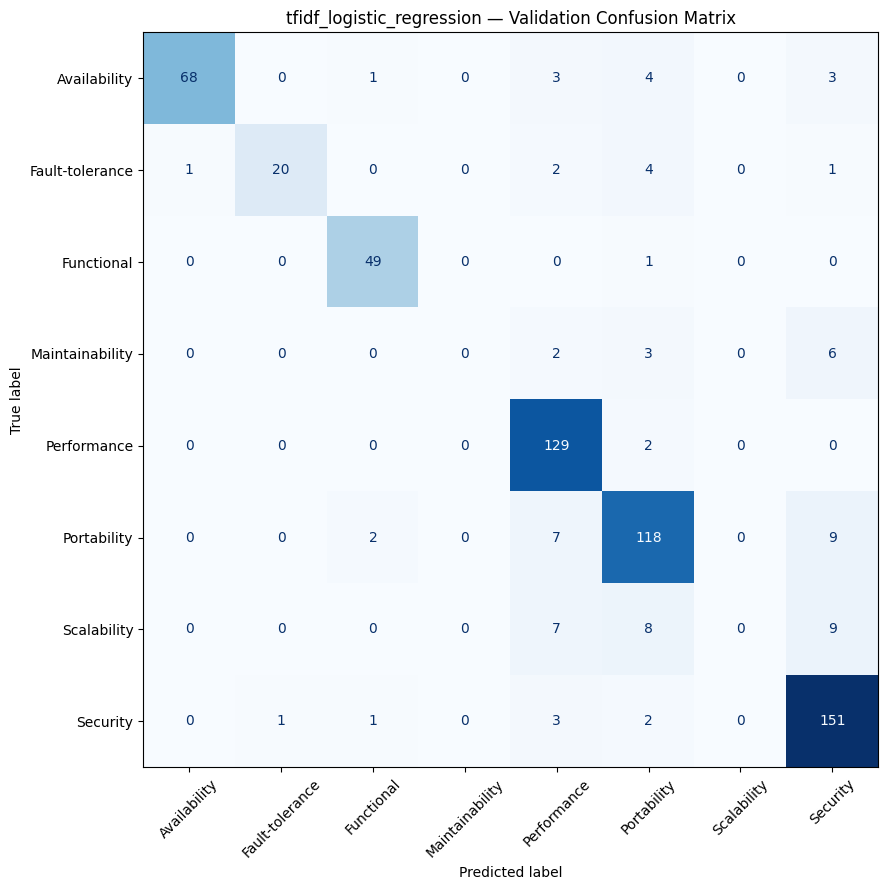

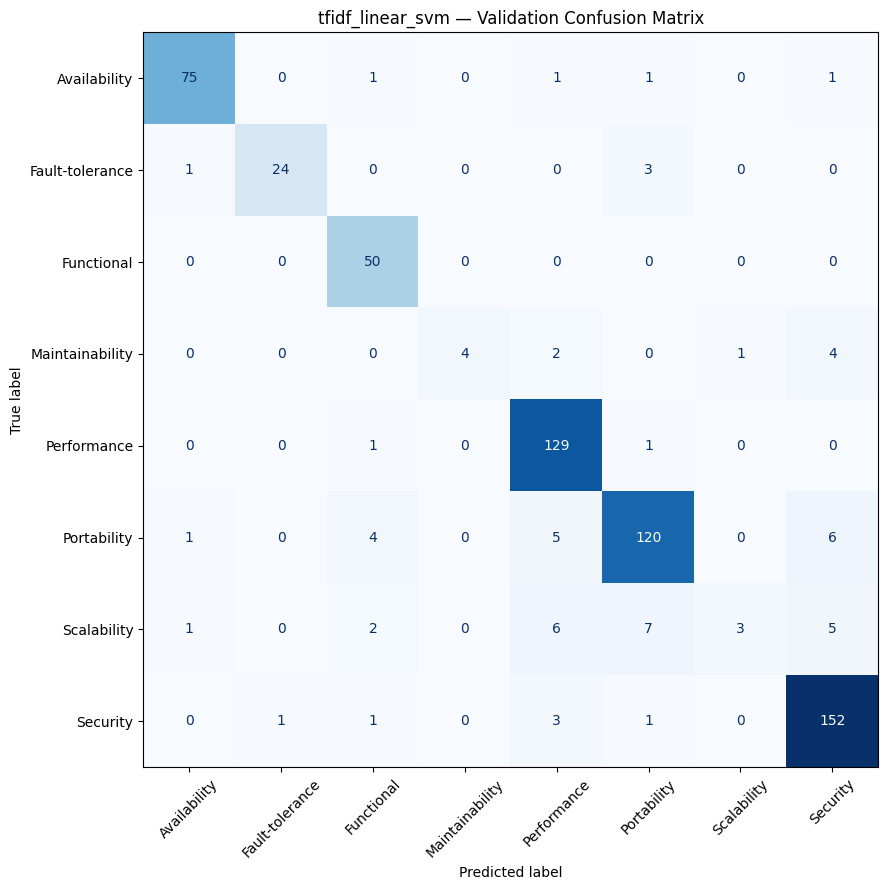


TOP LINEAR SVM CLASSIFICATION ERRORS
   actual_label predicted_label  error_count
    Scalability     Portability            7
    Portability        Security            6
    Scalability     Performance            6
    Portability     Performance            5
    Scalability        Security            5
Maintainability        Security            4
    Portability      Functional            4
Fault-tolerance     Portability            3
       Security     Performance            3
    Scalability      Functional            2
Maintainability     Performance            2
Fault-tolerance    Availability            1

SELECTED MISCLASSIFIED REQUIREMENTS:
   actual_label predicted_label                                                                                                                                                                         text_preview
   Availability      Functional Users should experience minimal downtime and lag. Profile Management: Users can create and upd

In [11]:

# ================================================================
# SECTION 6B — PER-CLASS DIAGNOSTICS AND ERROR ANALYSIS
# ================================================================
# Read-only analysis of frozen training/validation data.
# Uses predictions and trained models already saved by Section 6A.
#
# IMPORTANT:
# - No training or hyperparameter tuning
# - No changes to frozen splits
# - No test data loaded or evaluated
# ================================================================

from pathlib import Path
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer

# ------------------------------------------------
# 6B.1 — PROJECT PATHS
# ------------------------------------------------

ROOT = PROJECT_DIR

SPLIT_DIR = ROOT / "data" / "splits_final"
BASELINE_DIR = ROOT / "results" / "ml_baselines_v1"
MODEL_DIR = ROOT / "models" / "ml_baselines_v1"

OUTPUT_DIR = BASELINE_DIR / "diagnostics_6b"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = SPLIT_DIR / "GitReq_train.csv"
VAL_PATH = SPLIT_DIR / "GitReq_validation.csv"

for path in [TRAIN_PATH, VAL_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing frozen file: {path}")

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)

required_columns = {
    "requirement_id",
    "RequirementText",
    "class_label",
    "repository_id"
}

for split_name, frame in [
    ("train", train_df),
    ("validation", val_df)
]:
    missing = required_columns - set(frame.columns)
    if missing:
        raise ValueError(
            f"{split_name} is missing columns: {missing}"
        )

assert len(train_df) == 4384
assert len(val_df) == 617

train_df["requirement_id"] = (
    train_df["requirement_id"].astype(str)
)
val_df["requirement_id"] = (
    val_df["requirement_id"].astype(str)
)

assert train_df["requirement_id"].is_unique
assert val_df["requirement_id"].is_unique

train_repos = set(train_df["repository_id"].astype(str))
val_repos = set(val_df["repository_id"].astype(str))

assert not (train_repos & val_repos), (
    "Repository overlap between training and validation!"
)

labels = sorted(
    set(train_df["class_label"].astype(str))
    | set(val_df["class_label"].astype(str))
)

assert len(labels) == 8, (
    f"Expected 8 classes, found {len(labels)}"
)

print("=" * 65)
print("SECTION 6B — DATA VALIDATION")
print("=" * 65)
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Training repositories:", len(train_repos))
print("Validation repositories:", len(val_repos))
print("Overlapping repositories:", len(train_repos & val_repos))
print("Classes:", labels)
print("Held-out test samples accessed: 0")

# ------------------------------------------------
# 6B.2 — LOAD EXISTING VALIDATION PREDICTIONS
# ------------------------------------------------

model_names = [
    "tfidf_logistic_regression",
    "tfidf_linear_svm"
]

predictions = {}
reports = []
summary_rows = []

for model_name in model_names:

    prediction_path = (
        BASELINE_DIR /
        f"{model_name}_validation_predictions.csv"
    )

    if not prediction_path.is_file():
        raise FileNotFoundError(prediction_path)

    saved = pd.read_csv(prediction_path)

    needed = {
        "requirement_id",
        "class_label",
        "predicted_label"
    }

    if not needed.issubset(saved.columns):
        raise ValueError(
            f"Incorrect prediction schema: {prediction_path}"
        )

    saved["requirement_id"] = (
        saved["requirement_id"].astype(str)
    )

    assert saved["requirement_id"].is_unique

    merged = val_df[
        [
            "requirement_id",
            "RequirementText",
            "class_label",
            "repository_id"
        ]
    ].merge(
        saved[
            [
                "requirement_id",
                "class_label",
                "predicted_label"
            ]
        ],
        on="requirement_id",
        how="left",
        validate="one_to_one",
        suffixes=("_frozen", "_saved")
    )

    assert len(merged) == len(val_df)
    assert merged["predicted_label"].notna().all()

    actual = merged["class_label_frozen"].astype(str)
    saved_actual = merged["class_label_saved"].astype(str)
    predicted = merged["predicted_label"].astype(str)

    assert (actual == saved_actual).all(), (
        f"Label mismatch for {model_name}"
    )

    assert set(predicted).issubset(set(labels))

    merged = merged.rename(
        columns={
            "class_label_frozen": "actual_label"
        }
    )

    merged["actual_label"] = actual
    merged["predicted_label"] = predicted
    merged["correct"] = (
        actual == predicted
    )

    predictions[model_name] = merged

    report = classification_report(
        actual,
        predicted,
        labels=labels,
        output_dict=True,
        zero_division=0
    )

    for label in labels:
        reports.append({
            "model": model_name,
            "class": label,
            "precision": report[label]["precision"],
            "recall": report[label]["recall"],
            "f1": report[label]["f1-score"],
            "support": int(report[label]["support"])
        })

    summary_rows.append({
        "model": model_name,
        "accuracy": accuracy_score(actual, predicted),
        "macro_f1": f1_score(
            actual, predicted,
            labels=labels,
            average="macro",
            zero_division=0
        ),
        "correct": int(merged["correct"].sum()),
        "incorrect": int((~merged["correct"]).sum())
    })

report_df = pd.DataFrame(reports)
summary_df = pd.DataFrame(summary_rows)

report_df.to_csv(
    OUTPUT_DIR / "per_class_metrics.csv",
    index=False
)

summary_df.to_csv(
    OUTPUT_DIR / "diagnostic_summary.csv",
    index=False
)

print("\n" + "=" * 65)
print("VALIDATION METRICS RECOMPUTED")
print("=" * 65)

print(
    summary_df.round(4).to_string(index=False)
)

print("Reproduction SVM validation macro-F1:", summary_df.loc[summary_df["model"] == "tfidf_linear_svm", "macro_f1"].iloc[0])

# ------------------------------------------------
# 6B.3 — PER-CLASS MODEL COMPARISON
# ------------------------------------------------

print("\n" + "=" * 65)
print("PER-CLASS COMPARISON")
print("=" * 65)

per_class = report_df.pivot(
    index="class",
    columns="model",
    values=["precision", "recall", "f1"]
)

per_class.columns = [
    f"{metric}_{model.replace('tfidf_', '')}"
    for metric, model in per_class.columns
]

print(per_class.round(4).to_string())

per_class.to_csv(
    OUTPUT_DIR / "per_class_model_comparison.csv"
)

svm_class_report = report_df[
    report_df["model"] == "tfidf_linear_svm"
].copy()

print("\nHARDEST CLASSES FOR LINEAR SVM:")
print(
    svm_class_report.sort_values("f1")[
        ["class", "precision", "recall", "f1", "support"]
    ].round(4).to_string(index=False)
)

# ------------------------------------------------
# 6B.4 — CONFUSION MATRICES
# ------------------------------------------------

print("\n" + "=" * 65)
print("GENERATING CONFUSION MATRICES")
print("=" * 65)

for model_name in model_names:

    frame = predictions[model_name]

    cm = confusion_matrix(
        frame["actual_label"],
        frame["predicted_label"],
        labels=labels
    )

    cm_df = pd.DataFrame(
        cm,
        index=labels,
        columns=labels
    )

    cm_df.to_csv(
        OUTPUT_DIR / f"{model_name}_confusion_matrix.csv"
    )

    fig, ax = plt.subplots(figsize=(11, 9))

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45,
        colorbar=False,
        values_format="d"
    )

    ax.set_title(
        f"{model_name} — Validation Confusion Matrix"
    )

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / f"{model_name}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# ------------------------------------------------
# 6B.5 — MOST COMMON CLASSIFICATION ERRORS
# ------------------------------------------------

svm_df = predictions["tfidf_linear_svm"].copy()

svm_errors = svm_df[
    ~svm_df["correct"]
].copy()

svm_errors.to_csv(
    OUTPUT_DIR / "svm_all_validation_errors.csv",
    index=False
)

confusion_pairs = (
    svm_errors.groupby(
        ["actual_label", "predicted_label"]
    )
    .size()
    .reset_index(name="error_count")
    .sort_values(
        "error_count",
        ascending=False
    )
)

confusion_pairs.to_csv(
    OUTPUT_DIR / "svm_top_confusions.csv",
    index=False
)

print("\n" + "=" * 65)
print("TOP LINEAR SVM CLASSIFICATION ERRORS")
print("=" * 65)

print(
    confusion_pairs.head(12).to_string(index=False)
)

# Two examples from each actual class
example_errors = (
    svm_errors
    .sort_values(["actual_label", "requirement_id"])
    .groupby("actual_label", group_keys=False)
    .head(2)
    .copy()
)

example_errors["text_preview"] = (
    example_errors["RequirementText"]
    .astype(str)
    .str.slice(0, 180)
)

print("\nSELECTED MISCLASSIFIED REQUIREMENTS:")

print(
    example_errors[
        [
            "actual_label",
            "predicted_label",
            "text_preview"
        ]
    ].to_string(index=False)
)

example_errors.to_csv(
    OUTPUT_DIR / "svm_error_examples.csv",
    index=False
)

# ------------------------------------------------
# 6B.6 — WHERE DO THE TWO MODELS DISAGREE?
# ------------------------------------------------

lr_df = predictions[
    "tfidf_logistic_regression"
].set_index("requirement_id")

svm_indexed = predictions[
    "tfidf_linear_svm"
].set_index("requirement_id")

comparison = pd.DataFrame({
    "actual": svm_indexed["actual_label"],
    "svm_prediction": svm_indexed["predicted_label"],
    "lr_prediction": lr_df.loc[
        svm_indexed.index, "predicted_label"
    ]
})

comparison["svm_correct"] = (
    comparison["svm_prediction"] == comparison["actual"]
)

comparison["lr_correct"] = (
    comparison["lr_prediction"] == comparison["actual"]
)

svm_only_correct = int((
    comparison["svm_correct"]
    & ~comparison["lr_correct"]
).sum())

lr_only_correct = int((
    comparison["lr_correct"]
    & ~comparison["svm_correct"]
).sum())

both_correct = int((
    comparison["svm_correct"]
    & comparison["lr_correct"]
).sum())

both_wrong = int((
    ~comparison["svm_correct"]
    & ~comparison["lr_correct"]
).sum())

print("\n" + "=" * 65)
print("MODEL DISAGREEMENT")
print("=" * 65)

print("Both correct:", both_correct)
print("Only SVM correct:", svm_only_correct)
print("Only LR correct:", lr_only_correct)
print("Both wrong:", both_wrong)

comparison.reset_index().to_csv(
    OUTPUT_DIR / "model_disagreement.csv",
    index=False
)

# ------------------------------------------------
# 6B.7 — CROSS-SPLIT TEXT SIMILARITY AUDIT
# ------------------------------------------------

print("\n" + "=" * 65)
print("TRAIN–VALIDATION TEXT SIMILARITY AUDIT")
print("=" * 65)

def normalize_text(text):
    return re.sub(
        r"\s+", " ",
        str(text).strip().casefold()
    )

train_text = train_df[
    "RequirementText"
].fillna("").astype(str)

val_text = val_df[
    "RequirementText"
].fillna("").astype(str)

train_normalized = train_text.map(normalize_text)
val_normalized = val_text.map(normalize_text)

train_text_set = set(
    train_normalized[train_normalized != ""]
)

exact_overlap = (
    val_normalized.isin(train_text_set)
    & (val_normalized != "")
)

print(
    "Exact normalized validation-to-training overlaps:",
    int(exact_overlap.sum())
)

# Use the TF-IDF vocabulary already fitted by Section 6A.
# This does not retrain the classification model.

svm_model = joblib.load(
    MODEL_DIR / "tfidf_linear_svm.joblib"
)

vectorizer = next(
    (
        step for _, step in svm_model.steps
        if isinstance(step, TfidfVectorizer)
    ),
    None
)

if vectorizer is None:
    raise ValueError(
        "Could not locate fitted TF-IDF vectorizer "
        "inside the saved Linear SVM pipeline."
    )

X_train_text = vectorizer.transform(train_text)
X_val_text = vectorizer.transform(val_text)

similarities = cosine_similarity(
    X_val_text,
    X_train_text
)

max_similarity = similarities.max(axis=1)
nearest_train_index = similarities.argmax(axis=1)

similarity_audit = val_df[
    ["requirement_id", "class_label", "repository_id"]
].copy()

similarity_audit["max_train_cosine_similarity"] = (
    max_similarity
)

similarity_audit["nearest_train_requirement_id"] = (
    train_df.iloc[nearest_train_index][
        "requirement_id"
    ].to_numpy()
)

similarity_audit["exact_normalized_overlap"] = (
    exact_overlap.to_numpy()
)

similarity_audit["svm_correct"] = (
    svm_df["correct"].to_numpy()
)

similarity_audit.to_csv(
    OUTPUT_DIR / "text_similarity_audit.csv",
    index=False
)

for threshold in [0.85, 0.90, 0.95, 0.99]:
    count = int(
        (max_similarity >= threshold).sum()
    )
    print(
        f"Validation texts with maximum cosine "
        f"similarity >= {threshold:.2f}: {count}"
    )

print(
    "Mean maximum text similarity:",
    round(float(max_similarity.mean()), 4)
)

# Similar text does not automatically prove leakage.
# This audit flags examples for further investigation.

# ------------------------------------------------
# 6B.8 — FINAL SUMMARY
# ------------------------------------------------

print("\n" + "=" * 65)
print("SECTION 6B — COMPLETED")
print("=" * 65)

print("Models diagnosed:", len(model_names))
print("Validation samples:", len(val_df))
print("Held-out test samples accessed: 0")

print("\nSaved diagnostics:")
print(OUTPUT_DIR)

print("\nGenerated:")
print("- Per-class precision, recall and F1")
print("- Two confusion matrix figures")
print("- Common classification error pairs")
print("- Misclassified requirement examples")
print("- SVM vs Logistic Regression disagreement")
print("- Train-validation text similarity audit")

print("\nFrozen splits remain unchanged.")
print("=" * 65)


In [12]:

# ============================================================
# GITREQ RESEARCH
# SECTION 6C — CLASS IMBALANCE EXPERIMENT
# ============================================================

import pandas as pd
import numpy as np
import joblib
import json
import time
import hashlib

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

from IPython.display import display

print("=" * 60)
print("SECTION 6C — CLASS IMBALANCE EXPERIMENT")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify frozen training and validation data
# ------------------------------------------------------------

with open(
    RESULTS_DIR / "splits_final" / "frozen_manifest.json"
) as f:
    manifest_6c = json.load(f)

def sha256_6c(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

train_path_6c = DATA_DIR / "splits_final" / "GitReq_train.csv"
val_path_6c = DATA_DIR / "splits_final" / "GitReq_validation.csv"

assert sha256_6c(train_path_6c) == (
    manifest_6c["partition_sha256"]["train"]
)

assert sha256_6c(val_path_6c) == (
    manifest_6c["partition_sha256"]["validation"]
)

train_6c = pd.read_csv(train_path_6c)
val_6c = pd.read_csv(val_path_6c)

assert len(train_6c) == 4384
assert len(val_6c) == 617

assert set(train_6c["repository_id"]).isdisjoint(
    set(val_6c["repository_id"])
)

X_train_6c = train_6c["RequirementText"].astype(str)
X_val_6c = val_6c["RequirementText"].astype(str)

y_train_6c = train_6c["class_label"].to_numpy()
y_val_6c = val_6c["class_label"].to_numpy()

classes_6c = sorted(np.unique(y_train_6c))

print("\nFrozen partitions verified.")
print("Training:", len(train_6c))
print("Validation:", len(val_6c))
print("Test records accessed: 0")

# ------------------------------------------------------------
# 2. Configure exactly the same TF-IDF representation
# ------------------------------------------------------------

def make_tfidf_6c():
    return TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=30000,
        sublinear_tf=True,
        lowercase=True,
        dtype=np.float32
    )

# ------------------------------------------------------------
# 3. Define only two new weighted models
# ------------------------------------------------------------

models_6c = {
    "balanced_logistic_regression": Pipeline([
        ("tfidf", make_tfidf_6c()),
        ("classifier", LogisticRegression(
            C=1.0,
            class_weight="balanced",
            solver="lbfgs",
            max_iter=1500,
            random_state=42
        ))
    ]),

    "balanced_linear_svm": Pipeline([
        ("tfidf", make_tfidf_6c()),
        ("classifier", LinearSVC(
            C=1.0,
            class_weight="balanced",
            max_iter=5000,
            random_state=42
        ))
    ])
}

# ------------------------------------------------------------
# 4. Prepare output folders
# ------------------------------------------------------------

RESULTS_6C = RESULTS_DIR / "ml_class_weight_experiment"
MODELS_6C = MODELS_DIR / "ml_class_weight_experiment"

RESULTS_6C.mkdir(parents=True, exist_ok=True)
MODELS_6C.mkdir(parents=True, exist_ok=True)

comparison_rows_6c = []
per_class_rows_6c = []

# ------------------------------------------------------------
# 5. Evaluation helper
# ------------------------------------------------------------

def evaluate_6c(model_name, predictions,
                training_seconds=None,
                prediction_seconds=None,
                model_size_mb=None):

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_val_6c,
            predictions,
            labels=classes_6c,
            zero_division=0
        )
    )

    summary = {
        "model": model_name,
        "accuracy": accuracy_score(
            y_val_6c, predictions
        ),
        "macro_f1": f1_score(
            y_val_6c,
            predictions,
            average="macro",
            zero_division=0
        ),
        "weighted_f1": f1_score(
            y_val_6c,
            predictions,
            average="weighted",
            zero_division=0
        ),
        "training_seconds": training_seconds,
        "prediction_seconds": prediction_seconds,
        "model_size_mb": model_size_mb
    }

    for cls, p, r, f, n in zip(
        classes_6c,
        precision,
        recall,
        f1,
        support
    ):
        per_class_rows_6c.append({
            "model": model_name,
            "class_label": cls,
            "precision": float(p),
            "recall": float(r),
            "f1": float(f),
            "support": int(n)
        })

    return summary

# ------------------------------------------------------------
# 6. Read original baseline predictions
# ------------------------------------------------------------

BASELINE_DIR_6C = RESULTS_DIR / "ml_baselines_v1"

baseline_names_6c = [
    "tfidf_logistic_regression",
    "tfidf_linear_svm"
]

for name in baseline_names_6c:

    path = (
        BASELINE_DIR_6C
        / f"{name}_validation_predictions.csv"
    )

    baseline = pd.read_csv(path)

    assert baseline["requirement_id"].is_unique
    assert set(baseline["requirement_id"]) == set(
        val_6c["requirement_id"]
    )

    aligned = val_6c[
        ["requirement_id", "class_label"]
    ].merge(
        baseline[
            ["requirement_id", "class_label",
             "predicted_label"]
        ],
        on="requirement_id",
        how="left",
        validate="one_to_one",
        suffixes=("_frozen", "_saved")
    )

    assert (
        aligned["class_label_frozen"]
        == aligned["class_label_saved"]
    ).all()

    assert aligned["predicted_label"].notna().all()

    metrics = evaluate_6c(
        name,
        aligned["predicted_label"].to_numpy()
    )

    comparison_rows_6c.append(metrics)

print("\nOriginal baseline predictions verified.")

# ------------------------------------------------------------
# 7. Train weighted models
# ------------------------------------------------------------

for model_name, model in models_6c.items():

    print("\n" + "-" * 60)
    print("Training:", model_name)
    print("-" * 60)

    start = time.perf_counter()

    model.fit(X_train_6c, y_train_6c)

    training_seconds = time.perf_counter() - start

    start = time.perf_counter()

    predictions = model.predict(X_val_6c)

    prediction_seconds = time.perf_counter() - start

    # Save model
    model_path = MODELS_6C / f"{model_name}.joblib"

    joblib.dump(model, model_path, compress=3)

    model_size_mb = (
        model_path.stat().st_size / (1024 ** 2)
    )

    # Compute metrics
    result = evaluate_6c(
        model_name,
        predictions,
        training_seconds,
        prediction_seconds,
        model_size_mb
    )

    comparison_rows_6c.append(result)

    # Save per-requirement predictions
    prediction_df = val_6c[
        [
            "requirement_id",
            "RequirementText",
            "class_label",
            "repository_id",
            "url"
        ]
    ].copy()

    prediction_df["predicted_label"] = predictions

    prediction_df["correct"] = (
        prediction_df["class_label"]
        == prediction_df["predicted_label"]
    )

    prediction_df.to_csv(
        RESULTS_6C
        / f"{model_name}_validation_predictions.csv",
        index=False
    )

    # Save classification report
    report = classification_report(
        y_val_6c,
        predictions,
        labels=classes_6c,
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(report).T.to_csv(
        RESULTS_6C
        / f"{model_name}_classification_report.csv"
    )

    # Save confusion matrix
    cm = confusion_matrix(
        y_val_6c,
        predictions,
        labels=classes_6c
    )

    pd.DataFrame(
        cm,
        index=classes_6c,
        columns=classes_6c
    ).to_csv(
        RESULTS_6C
        / f"{model_name}_confusion_matrix.csv"
    )

    print("Accuracy:", round(result["accuracy"], 4))
    print("Macro F1:", round(result["macro_f1"], 4))
    print("Weighted F1:", round(result["weighted_f1"], 4))
    print("Training seconds:", round(training_seconds, 3))

# ------------------------------------------------------------
# 8. Compare all four models
# ------------------------------------------------------------

comparison_6c = pd.DataFrame(comparison_rows_6c)

comparison_6c = comparison_6c.sort_values(
    "macro_f1",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 60)
print("CLASS-WEIGHT EXPERIMENT — VALIDATION RESULTS")
print("=" * 60)

display(comparison_6c.round(4))

# ------------------------------------------------------------
# 9. Compare minority category performance
# ------------------------------------------------------------

per_class_6c = pd.DataFrame(per_class_rows_6c)

minority_classes_6c = [
    "Maintainability",
    "Scalability",
    "Fault-tolerance"
]

minority_results_6c = per_class_6c.loc[
    per_class_6c["class_label"].isin(
        minority_classes_6c
    )
].copy()

print("\n--- MINORITY CLASS COMPARISON ---")

display(
    minority_results_6c[
        [
            "model",
            "class_label",
            "precision",
            "recall",
            "f1",
            "support"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 10. Show the effect of balanced weights
# ------------------------------------------------------------

pairs_6c = [
    (
        "tfidf_logistic_regression",
        "balanced_logistic_regression"
    ),
    (
        "tfidf_linear_svm",
        "balanced_linear_svm"
    )
]

change_rows_6c = []

for original_name, balanced_name in pairs_6c:

    original = comparison_6c.loc[
        comparison_6c["model"] == original_name
    ].iloc[0]

    balanced = comparison_6c.loc[
        comparison_6c["model"] == balanced_name
    ].iloc[0]

    change_rows_6c.append({
        "comparison": balanced_name,
        "accuracy_change": (
            balanced["accuracy"] - original["accuracy"]
        ),
        "macro_f1_change": (
            balanced["macro_f1"] - original["macro_f1"]
        ),
        "weighted_f1_change": (
            balanced["weighted_f1"]
            - original["weighted_f1"]
        )
    })

changes_6c = pd.DataFrame(change_rows_6c)

print("\n--- BALANCED VS ORIGINAL ---")
display(changes_6c.round(4))

# ------------------------------------------------------------
# 11. Save research artifacts
# ------------------------------------------------------------

comparison_6c.to_csv(
    RESULTS_6C / "class_weight_model_comparison.csv",
    index=False
)

per_class_6c.to_csv(
    RESULTS_6C / "per_class_comparison.csv",
    index=False
)

changes_6c.to_csv(
    RESULTS_6C / "class_weight_changes.csv",
    index=False
)

experiment_config_6c = {
    "experiment": "class_weight_comparison",
    "primary_metric": "macro_f1",
    "evaluation_partition": "validation_only",
    "test_samples_used": 0,
    "train_samples": len(train_6c),
    "validation_samples": len(val_6c),
    "random_state": 42,
    "class_weight_options": [None, "balanced"],
    "C": 1.0,
    "tfidf": {
        "ngram_range": [1, 2],
        "min_df": 2,
        "max_features": 30000,
        "sublinear_tf": True,
        "lowercase": True
    },
    "frozen_train_sha256": sha256_6c(train_path_6c),
    "frozen_validation_sha256": sha256_6c(val_path_6c)
}

with open(
    RESULTS_6C / "experiment_config.json", "w"
) as f:
    json.dump(experiment_config_6c, f, indent=4)

# ------------------------------------------------------------
# 12. Final confirmation
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SECTION 6C — COMPLETED")
print("=" * 60)

print("Total models compared:", len(comparison_6c))
print("New weighted models trained:", len(models_6c))
print("Training requirements:", len(train_6c))
print("Validation requirements:", len(val_6c))
print("Held-out test requirements accessed: 0")

print("\nResults:", RESULTS_6C)
print("Models:", MODELS_6C)

print("\nFrozen partitions unchanged.")
print("=" * 60)


SECTION 6C — CLASS IMBALANCE EXPERIMENT

Frozen partitions verified.
Training: 4384
Validation: 617
Test records accessed: 0

Original baseline predictions verified.

------------------------------------------------------------
Training: balanced_logistic_regression
------------------------------------------------------------
Accuracy: 0.8849
Macro F1: 0.7826
Weighted F1: 0.8755
Training seconds: 6.388

------------------------------------------------------------
Training: balanced_linear_svm
------------------------------------------------------------
Accuracy: 0.9076
Macro F1: 0.8093
Weighted F1: 0.8968
Training seconds: 1.679

CLASS-WEIGHT EXPERIMENT — VALIDATION RESULTS


,model,accuracy,macro_f1,weighted_f1,training_seconds,prediction_seconds,model_size_mb
0,balanced_linear_svm,0.9076,0.8093,0.8968,1.6788,0.0527,1.7264
1,tfidf_linear_svm,0.9028,0.7853,0.8888,NaN,NaN,NaN
2,balanced_logistic_regression,0.8849,0.7826,0.8755,6.3879,0.1272,2.0028
3,tfidf_logistic_regression,0.8671,0.6675,0.8413,NaN,NaN,NaN



--- MINORITY CLASS COMPARISON ---


,model,class_label,precision,recall,f1,support
1,tfidf_logistic_regression,Fault-tolerance,0.9524,0.7143,0.8163,28
3,tfidf_logistic_regression,Maintainability,0.0000,0.0000,0.0000,11
6,tfidf_logistic_regression,Scalability,0.0000,0.0000,0.0000,24
9,tfidf_linear_svm,Fault-tolerance,0.9600,0.8571,0.9057,28
11,tfidf_linear_svm,Maintainability,1.0000,0.3636,0.5333,11
14,tfidf_linear_svm,Scalability,0.7500,0.1250,0.2143,24
17,balanced_logistic_regression,Fault-tolerance,0.9167,0.7857,0.8462,28
19,balanced_logistic_regression,Maintainability,0.7500,0.5455,0.6316,11
22,balanced_logistic_regression,Scalability,0.5000,0.1667,0.2500,24
25,balanced_linear_svm,Fault-tolerance,0.9231,0.8571,0.8889,28



--- BALANCED VS ORIGINAL ---


,comparison,accuracy_change,macro_f1_change,weighted_f1_change
0,balanced_logistic_regression,0.0178,0.115,0.0343
1,balanced_linear_svm,0.0049,0.024,0.0079



SECTION 6C — COMPLETED
Total models compared: 4
New weighted models trained: 2
Training requirements: 4384
Validation requirements: 617
Held-out test requirements accessed: 0

Results: /content/drive/MyDrive/GitReq_Reproduction_Run01/results/ml_class_weight_experiment
Models: /content/drive/MyDrive/GitReq_Reproduction_Run01/models/ml_class_weight_experiment

Frozen partitions unchanged.


In [13]:

# ============================================================
# GITREQ RESEARCH
# SECTION 6D — DATASET SHORTCUT DIAGNOSTIC
# ============================================================

import pandas as pd
import numpy as np
import joblib
import json
import time
import hashlib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from IPython.display import display

print("=" * 60)
print("SECTION 6D — DATASET SHORTCUT DIAGNOSTIC")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify frozen datasets
# ------------------------------------------------------------

with open(
    RESULTS_DIR / "splits_final" / "frozen_manifest.json"
) as f:
    frozen_6d = json.load(f)

def hash_6d(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

train_path_6d = (
    DATA_DIR / "splits_final" / "GitReq_train.csv"
)

val_path_6d = (
    DATA_DIR / "splits_final" / "GitReq_validation.csv"
)

assert hash_6d(train_path_6d) == (
    frozen_6d["partition_sha256"]["train"]
)

assert hash_6d(val_path_6d) == (
    frozen_6d["partition_sha256"]["validation"]
)

train_6d = pd.read_csv(train_path_6d)
val_6d = pd.read_csv(val_path_6d)

assert len(train_6d) == 4384
assert len(val_6d) == 617

assert set(train_6d["repository_id"]).isdisjoint(
    set(val_6d["repository_id"])
)

y_train_6d = train_6d["class_label"].to_numpy()
y_val_6d = val_6d["class_label"].to_numpy()

classes_6d = sorted(np.unique(y_train_6d))

print("\nFrozen data verified.")
print("Train:", len(train_6d))
print("Validation:", len(val_6d))
print("Held-out test accessed: 0")

# ------------------------------------------------------------
# 2. Extract nonsemantic numerical features
# ------------------------------------------------------------

def extract_features_6d(texts):

    s = pd.Series(list(texts)).fillna("").astype(str)

    chars = s.str.len().astype(float)
    words = s.str.split().str.len().astype(float)

    safe_chars = chars.clip(lower=1)
    safe_words = words.clip(lower=1)

    features = pd.DataFrame({
        "word_count": words,
        "character_count": chars,

        "average_chars_per_word": (
            chars / safe_words
        ),

        "newline_count": s.str.count(r"\n"),
        "colon_count": s.str.count(r":"),
        "semicolon_count": s.str.count(r";"),
        "question_mark_count": s.str.count(r"\?"),

        "digit_fraction": (
            s.str.count(r"\d") / safe_chars
        ),

        "uppercase_fraction": (
            s.str.count(r"[A-Z]") / safe_chars
        ),

        "bullet_line_count": s.str.count(
            r"(?m)^\s*[-*]\s+"
        ),

        "markdown_heading_count": s.str.count(
            r"(?m)^\s*#+\s+"
        ),

        "backtick_count": s.str.count(r"`"),

        "url_pattern_count": s.str.count(
            r"https?://|www\."
        )
    })

    assert features.notna().sum().sum() == len(
        features
    ) * len(features.columns)

    assert np.isfinite(
        features.to_numpy()
    ).all()

    return features

train_features_6d = extract_features_6d(
    train_6d["RequirementText"]
)

val_features_6d = extract_features_6d(
    val_6d["RequirementText"]
)

length_columns_6d = [
    "word_count",
    "character_count"
]

format_columns_6d = list(
    train_features_6d.columns
)

print("\nExtracted features:")
for column in format_columns_6d:
    print("-", column)

# ------------------------------------------------------------
# 3. Define diagnostic models
# ------------------------------------------------------------

def make_diagnostic_model_6d():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            C=1.0,
            class_weight="balanced",
            max_iter=2000,
            solver="lbfgs",
            random_state=42
        ))
    ])

experiments_6d = {
    "length_only_lr": length_columns_6d,
    "length_plus_format_lr": format_columns_6d
}

RESULTS_6D = RESULTS_DIR / "shortcut_diagnostic"
MODELS_6D = MODELS_DIR / "shortcut_diagnostic"

RESULTS_6D.mkdir(parents=True, exist_ok=True)
MODELS_6D.mkdir(parents=True, exist_ok=True)

results_6d = []
class_rows_6d = []

# ------------------------------------------------------------
# 4. Train and evaluate on validation only
# ------------------------------------------------------------

for name, columns in experiments_6d.items():

    print("\n" + "-" * 60)
    print("Model:", name)
    print("-" * 60)

    model = make_diagnostic_model_6d()

    X_train_num = train_features_6d[columns]
    X_val_num = val_features_6d[columns]

    train_start = time.perf_counter()

    model.fit(X_train_num, y_train_6d)

    training_time = (
        time.perf_counter() - train_start
    )

    prediction_start = time.perf_counter()

    predictions = model.predict(X_val_num)

    prediction_time = (
        time.perf_counter() - prediction_start
    )

    accuracy = accuracy_score(
        y_val_6d, predictions
    )

    macro_f1 = f1_score(
        y_val_6d,
        predictions,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_val_6d,
        predictions,
        average="weighted",
        zero_division=0
    )

    model_path = MODELS_6D / f"{name}.joblib"

    joblib.dump(model, model_path, compress=3)

    model_size = (
        model_path.stat().st_size / (1024 ** 2)
    )

    results_6d.append({
        "model": name,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "training_seconds": training_time,
        "prediction_seconds": prediction_time,
        "model_size_mb": model_size,
        "number_of_features": len(columns)
    })

    report = classification_report(
        y_val_6d,
        predictions,
        labels=classes_6d,
        output_dict=True,
        zero_division=0
    )

    for cls in classes_6d:
        class_rows_6d.append({
            "model": name,
            "class_label": cls,
            "precision": report[cls]["precision"],
            "recall": report[cls]["recall"],
            "f1": report[cls]["f1-score"],
            "support": report[cls]["support"]
        })

    prediction_df = val_6d[
        [
            "requirement_id",
            "class_label",
            "repository_id"
        ]
    ].copy()

    prediction_df["predicted_label"] = predictions

    prediction_df.to_csv(
        RESULTS_6D / f"{name}_predictions.csv",
        index=False
    )

    matrix = confusion_matrix(
        y_val_6d,
        predictions,
        labels=classes_6d
    )

    pd.DataFrame(
        matrix,
        index=classes_6d,
        columns=classes_6d
    ).to_csv(
        RESULTS_6D / f"{name}_confusion_matrix.csv"
    )

    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))
    print("Weighted F1:", round(weighted_f1, 4))
    print("Training seconds:", round(training_time, 3))

# ------------------------------------------------------------
# 5. Diagnostic model comparison
# ------------------------------------------------------------

results_table_6d = pd.DataFrame(results_6d)

print("\n" + "=" * 60)
print("NONSEMANTIC FEATURE CLASSIFICATION RESULTS")
print("=" * 60)

display(results_table_6d.round(4))

# ------------------------------------------------------------
# 6. Compare against text-based classifiers
# ------------------------------------------------------------

previous_results_path = (
    RESULTS_DIR / "ml_class_weight_experiment"
    / "class_weight_model_comparison.csv"
)

previous_results = pd.read_csv(
    previous_results_path
)

reference_names = [
    "balanced_logistic_regression",
    "balanced_linear_svm"
]

reference_results = previous_results.loc[
    previous_results["model"].isin(reference_names),
    ["model", "accuracy", "macro_f1", "weighted_f1"]
].copy()

diagnostic_results = results_table_6d[
    ["model", "accuracy", "macro_f1", "weighted_f1"]
]

combined_comparison = pd.concat(
    [reference_results, diagnostic_results],
    ignore_index=True
)

print("\n--- TEXT VS NONSEMANTIC FEATURES ---")

display(
    combined_comparison.sort_values(
        "macro_f1", ascending=False
    ).round(4)
)

# ------------------------------------------------------------
# 7. Per-class diagnostic results
# ------------------------------------------------------------

per_class_table_6d = pd.DataFrame(
    class_rows_6d
)

print("\n--- PER-CLASS DIAGNOSTIC RESULTS ---")

display(
    per_class_table_6d[
        ["model", "class_label", "recall", "f1", "support"]
    ].round(4)
)

# ------------------------------------------------------------
# 8. Save experiment artifacts
# ------------------------------------------------------------

results_table_6d.to_csv(
    RESULTS_6D / "diagnostic_model_results.csv",
    index=False
)

per_class_table_6d.to_csv(
    RESULTS_6D / "diagnostic_per_class_results.csv",
    index=False
)

combined_comparison.to_csv(
    RESULTS_6D / "text_vs_nonsemantic_comparison.csv",
    index=False
)

config_6d = {
    "experiment": "nonsemantic_shortcut_diagnostic",
    "primary_metric": "macro_f1",
    "train_samples": len(train_6d),
    "validation_samples": len(val_6d),
    "test_samples_accessed": 0,
    "random_state": 42,
    "class_weight": "balanced",
    "model": "LogisticRegression",
    "C": 1.0,
    "feature_sets": experiments_6d,
    "frozen_train_sha256": hash_6d(train_path_6d),
    "frozen_validation_sha256": hash_6d(val_path_6d)
}

with open(
    RESULTS_6D / "experiment_config.json",
    "w"
) as f:
    json.dump(config_6d, f, indent=4)

# ------------------------------------------------------------
# 9. Final confirmation
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SECTION 6D — COMPLETED")
print("=" * 60)

print("Diagnostic models trained:", len(experiments_6d))
print("Training records:", len(train_6d))
print("Validation records:", len(val_6d))
print("Test records accessed: 0")

print("\nResults saved to:")
print(RESULTS_6D)

print("\nModels saved to:")
print(MODELS_6D)

print("\nFrozen dataset partitions unchanged.")
print("=" * 60)


SECTION 6D — DATASET SHORTCUT DIAGNOSTIC

Frozen data verified.
Train: 4384
Validation: 617
Held-out test accessed: 0

Extracted features:
- word_count
- character_count
- average_chars_per_word
- newline_count
- colon_count
- semicolon_count
- question_mark_count
- digit_fraction
- uppercase_fraction
- bullet_line_count
- markdown_heading_count
- backtick_count
- url_pattern_count

------------------------------------------------------------
Model: length_only_lr
------------------------------------------------------------
Accuracy: 0.3144
Macro F1: 0.2442
Weighted F1: 0.3129
Training seconds: 0.148

------------------------------------------------------------
Model: length_plus_format_lr
------------------------------------------------------------
Accuracy: 0.3436
Macro F1: 0.2767
Weighted F1: 0.3476
Training seconds: 0.302

NONSEMANTIC FEATURE CLASSIFICATION RESULTS


,model,accuracy,macro_f1,weighted_f1,training_seconds,prediction_seconds,model_size_mb,number_of_features
0,length_only_lr,0.3144,0.2442,0.3129,0.1479,0.0027,0.0012,2
1,length_plus_format_lr,0.3436,0.2767,0.3476,0.3024,0.0058,0.0020,13



--- TEXT VS NONSEMANTIC FEATURES ---


,model,accuracy,macro_f1,weighted_f1
0,balanced_linear_svm,0.9076,0.8093,0.8968
1,balanced_logistic_regression,0.8849,0.7826,0.8755
3,length_plus_format_lr,0.3436,0.2767,0.3476
2,length_only_lr,0.3144,0.2442,0.3129



--- PER-CLASS DIAGNOSTIC RESULTS ---


,model,class_label,recall,f1,support
0,length_only_lr,Availability,0.1266,0.1887,79.0
1,length_only_lr,Fault-tolerance,0.0357,0.0194,28.0
2,length_only_lr,Functional,0.8400,0.5185,50.0
3,length_only_lr,Maintainability,0.1818,0.1111,11.0
4,length_only_lr,Performance,0.5115,0.4718,131.0
5,length_only_lr,Portability,0.2059,0.2581,136.0
6,length_only_lr,Scalability,0.0833,0.0556,24.0
7,length_only_lr,Security,0.2658,0.3307,158.0
8,length_plus_format_lr,Availability,0.2025,0.2712,79.0
9,length_plus_format_lr,Fault-tolerance,0.3571,0.1709,28.0



SECTION 6D — COMPLETED
Diagnostic models trained: 2
Training records: 4384
Validation records: 617
Test records accessed: 0

Results saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/results/shortcut_diagnostic

Models saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/models/shortcut_diagnostic

Frozen dataset partitions unchanged.


In [14]:

# ============================================================
# GITREQ RESEARCH
# SECTION 6E — LEXICAL CUE SENSITIVITY EXPERIMENT
# ============================================================

import pandas as pd
import numpy as np
import re
import json
import hashlib
import joblib
import time

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
from IPython.display import display

print("=" * 60)
print("SECTION 6E — LEXICAL CUE SENSITIVITY")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify frozen data
# ------------------------------------------------------------

with open(
    RESULTS_DIR / "splits_final" / "frozen_manifest.json"
) as f:
    manifest_6e = json.load(f)

def hash_6e(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

train_path_6e = (
    DATA_DIR / "splits_final" / "GitReq_train.csv"
)
val_path_6e = (
    DATA_DIR / "splits_final" / "GitReq_validation.csv"
)

assert hash_6e(train_path_6e) == (
    manifest_6e["partition_sha256"]["train"]
)
assert hash_6e(val_path_6e) == (
    manifest_6e["partition_sha256"]["validation"]
)

train_6e = pd.read_csv(train_path_6e)
val_6e = pd.read_csv(val_path_6e)

assert len(train_6e) == 4384
assert len(val_6e) == 617

assert set(train_6e["repository_id"]).isdisjoint(
    set(val_6e["repository_id"])
)

X_train_original = (
    train_6e["RequirementText"].astype(str).tolist()
)
X_val_original = (
    val_6e["RequirementText"].astype(str).tolist()
)

y_train_6e = train_6e["class_label"].to_numpy()
y_val_6e = val_6e["class_label"].to_numpy()

classes_6e = sorted(np.unique(y_train_6e))

print("Frozen data verified.")
print("Training:", len(train_6e))
print("Validation:", len(val_6e))
print("Held-out test accessed: 0")

# ------------------------------------------------------------
# 2. Define exact category-name patterns
# ------------------------------------------------------------

category_terms_6e = [
    "Availability",
    "Fault-tolerance",
    "Functional",
    "Maintainability",
    "Performance",
    "Portability",
    "Scalability",
    "Security"
]

# Accept a space or hyphen for Fault-tolerance.
term_parts_6e = []

for term in category_terms_6e:
    if term == "Fault-tolerance":
        term_parts_6e.append(r"Fault[\s-]tolerance")
    else:
        term_parts_6e.append(re.escape(term))

category_alternatives_6e = "|".join(
    term_parts_6e
)

category_pattern_6e = re.compile(
    rf"(?<!\w)(?:{category_alternatives_6e})(?!\w)",
    re.IGNORECASE
)

metadata_pattern_6e = re.compile(
    rf"(?<!\w)(?:type|label|category)"
    rf"\s*:\s*(?:{category_alternatives_6e})(?!\w)",
    re.IGNORECASE
)

# ------------------------------------------------------------
# 3. Define transformations
# ------------------------------------------------------------

def transform_text_6e(text, condition):

    text = str(text)

    if condition == "metadata_removed":
        return metadata_pattern_6e.sub(" ", text)

    if condition == "class_names_removed":
        return category_pattern_6e.sub(" ", text)

    raise ValueError("Unknown condition")

conditions_6e = [
    "metadata_removed",
    "class_names_removed"
]

# ------------------------------------------------------------
# 4. Load original balanced SVM
# ------------------------------------------------------------

baseline_model_path = (
    MODELS_DIR / "ml_class_weight_experiment"
    / "balanced_linear_svm.joblib"
)

baseline_model_6e = joblib.load(
    baseline_model_path
)

baseline_predictions_6e = baseline_model_6e.predict(
    X_val_original
)

baseline_f1_6e = f1_score(
    y_val_6e,
    baseline_predictions_6e,
    average="macro",
    zero_division=0
)

print("New balanced-SVM validation macro-F1:", round(baseline_f1_6e, 6))

# Verify saved validation predictions.
saved_predictions_path = (
    RESULTS_DIR / "ml_class_weight_experiment"
    / "balanced_linear_svm_validation_predictions.csv"
)

saved_predictions_6e = pd.read_csv(
    saved_predictions_path
)

aligned_saved_6e = val_6e[
    ["requirement_id"]
].merge(
    saved_predictions_6e[
        ["requirement_id", "predicted_label"]
    ],
    on="requirement_id",
    validate="one_to_one",
    how="left"
)

assert aligned_saved_6e["predicted_label"].notna().all()

assert np.array_equal(
    baseline_predictions_6e,
    aligned_saved_6e["predicted_label"].to_numpy()
)

print("\nOriginal balanced SVM reproduced.")
print("Original Macro F1:", round(baseline_f1_6e, 4))

# ------------------------------------------------------------
# 5. Configure identical SVM hyperparameters
# ------------------------------------------------------------

def make_svm_6e():

    return Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_features=30000,
            sublinear_tf=True,
            lowercase=True,
            dtype=np.float32
        )),
        ("classifier", LinearSVC(
            C=1.0,
            class_weight="balanced",
            max_iter=5000,
            random_state=42
        ))
    ])

# ------------------------------------------------------------
# 6. Output folders
# ------------------------------------------------------------

RESULTS_6E = RESULTS_DIR / "lexical_cue_sensitivity"
MODELS_6E = MODELS_DIR / "lexical_cue_sensitivity"

RESULTS_6E.mkdir(parents=True, exist_ok=True)
MODELS_6E.mkdir(parents=True, exist_ok=True)

results_6e = []
class_results_6e = []

# ------------------------------------------------------------
# 7. Evaluation helper
# ------------------------------------------------------------

def evaluate_condition_6e(
    name, predictions, changed_train,
    changed_val, train_seconds
):

    accuracy = accuracy_score(
        y_val_6e, predictions
    )

    macro = f1_score(
        y_val_6e,
        predictions,
        average="macro",
        zero_division=0
    )

    weighted = f1_score(
        y_val_6e,
        predictions,
        average="weighted",
        zero_division=0
    )

    results_6e.append({
        "condition": name,
        "accuracy": accuracy,
        "macro_f1": macro,
        "weighted_f1": weighted,
        "macro_f1_change": macro - baseline_f1_6e,
        "changed_training_texts": changed_train,
        "changed_validation_texts": changed_val,
        "training_seconds": train_seconds
    })

    report = classification_report(
        y_val_6e,
        predictions,
        labels=classes_6e,
        output_dict=True,
        zero_division=0
    )

    for cls in classes_6e:
        class_results_6e.append({
            "condition": name,
            "class_label": cls,
            "precision": report[cls]["precision"],
            "recall": report[cls]["recall"],
            "f1": report[cls]["f1-score"],
            "support": report[cls]["support"]
        })

    return macro

# Add original reference.
evaluate_condition_6e(
    "original_balanced_svm",
    baseline_predictions_6e,
    0,
    0,
    None
)

# ------------------------------------------------------------
# 8. Retrain on each transformed feature condition
# ------------------------------------------------------------

for condition in conditions_6e:

    print("\n" + "-" * 60)
    print("Condition:", condition)
    print("-" * 60)

    transformed_train = [
        transform_text_6e(text, condition)
        for text in X_train_original
    ]

    transformed_val = [
        transform_text_6e(text, condition)
        for text in X_val_original
    ]

    changed_train = sum(
        a != b
        for a, b in zip(
            X_train_original, transformed_train
        )
    )

    changed_val = sum(
        a != b
        for a, b in zip(
            X_val_original, transformed_val
        )
    )

    assert all(
        text.strip() for text in transformed_train
    )

    assert all(
        text.strip() for text in transformed_val
    )

    print("Changed training texts:", changed_train)
    print("Changed validation texts:", changed_val)

    model = make_svm_6e()

    start = time.perf_counter()

    model.fit(transformed_train, y_train_6e)

    training_seconds = time.perf_counter() - start

    predictions = model.predict(transformed_val)

    macro = evaluate_condition_6e(
        condition,
        predictions,
        changed_train,
        changed_val,
        training_seconds
    )

    print("Accuracy:",
          round(accuracy_score(y_val_6e, predictions), 4))
    print("Macro F1:", round(macro, 4))
    print(
        "Macro F1 change:",
        round(macro - baseline_f1_6e, 4)
    )

    # Save model.
    joblib.dump(
        model,
        MODELS_6E / f"{condition}.joblib",
        compress=3
    )

    # Save predictions and preserve original labels.
    prediction_df = val_6e[
        [
            "requirement_id",
            "class_label",
            "repository_id"
        ]
    ].copy()

    prediction_df["predicted_label"] = predictions
    prediction_df["baseline_prediction"] = (
        baseline_predictions_6e
    )

    prediction_df["text_modified"] = [
        a != b
        for a, b in zip(
            X_val_original, transformed_val
        )
    ]

    prediction_df.to_csv(
        RESULTS_6E / f"{condition}_predictions.csv",
        index=False
    )

# ------------------------------------------------------------
# 9. Compare experiment results
# ------------------------------------------------------------

results_table_6e = pd.DataFrame(results_6e)

per_class_table_6e = pd.DataFrame(class_results_6e)

print("\n" + "=" * 60)
print("LEXICAL CUE SENSITIVITY RESULTS")
print("=" * 60)

display(results_table_6e.round(4))

# ------------------------------------------------------------
# 10. Compare per-class F1
# ------------------------------------------------------------

class_comparison_6e = per_class_table_6e.pivot(
    index="class_label",
    columns="condition",
    values="f1"
)

print("\n--- PER-CLASS F1 COMPARISON ---")

display(class_comparison_6e.round(4))

# ------------------------------------------------------------
# 11. Save all research artifacts
# ------------------------------------------------------------

results_table_6e.to_csv(
    RESULTS_6E / "sensitivity_comparison.csv",
    index=False
)

per_class_table_6e.to_csv(
    RESULTS_6E / "per_class_sensitivity.csv",
    index=False
)

class_comparison_6e.to_csv(
    RESULTS_6E / "per_class_f1_comparison.csv"
)

config_6e = {
    "experiment": "lexical_cue_sensitivity",
    "model": "balanced_linear_svm",
    "C": 1.0,
    "class_weight": "balanced",
    "conditions": conditions_6e,
    "retrain_for_each_condition": True,
    "test_samples_accessed": 0,
    "primary_metric": "macro_f1",
    "random_state": 42,
    "train_samples": len(train_6e),
    "validation_samples": len(val_6e),
    "original_train_sha256": hash_6e(train_path_6e),
    "original_validation_sha256": hash_6e(val_path_6e),
    "metadata_regex": metadata_pattern_6e.pattern,
    "class_name_regex": category_pattern_6e.pattern,
    "important_limitation": (
        "Removing genuine domain terms does not prove "
        "that a model exploits dataset shortcuts."
    )
}

with open(
    RESULTS_6E / "experiment_config.json",
    "w"
) as f:
    json.dump(config_6e, f, indent=4)

print("\n" + "=" * 60)
print("SECTION 6E — COMPLETED")
print("=" * 60)

print("Conditions evaluated:", len(results_table_6e))
print("Training records:", len(train_6e))
print("Validation records:", len(val_6e))
print("Test records accessed: 0")

print("\nResults saved to:")
print(RESULTS_6E)

print("\nModels saved to:")
print(MODELS_6E)

print("\nFrozen partitions unchanged.")
print("=" * 60)


SECTION 6E — LEXICAL CUE SENSITIVITY
Frozen data verified.
Training: 4384
Validation: 617
Held-out test accessed: 0
New balanced-SVM validation macro-F1: 0.809318

Original balanced SVM reproduced.
Original Macro F1: 0.8093

------------------------------------------------------------
Condition: metadata_removed
------------------------------------------------------------
Changed training texts: 47
Changed validation texts: 1
Accuracy: 0.9076
Macro F1: 0.8093
Macro F1 change: 0.0

------------------------------------------------------------
Condition: class_names_removed
------------------------------------------------------------
Changed training texts: 1360
Changed validation texts: 183
Accuracy: 0.8849
Macro F1: 0.7525
Macro F1 change: -0.0568

LEXICAL CUE SENSITIVITY RESULTS


,condition,accuracy,macro_f1,weighted_f1,macro_f1_change,changed_training_texts,changed_validation_texts,training_seconds
0,original_balanced_svm,0.9076,0.8093,0.8968,0.0000,0,0,NaN
1,metadata_removed,0.9076,0.8093,0.8968,0.0000,47,1,1.8345
2,class_names_removed,0.8849,0.7525,0.8712,-0.0568,1360,183,1.7955



--- PER-CLASS F1 COMPARISON ---


condition,class_names_removed,metadata_removed,original_balanced_svm
class_label,,,
Availability,0.9231,0.9615,0.9615
Fault-tolerance,0.8889,0.8889,0.8889
Functional,0.9091,0.9091,0.9091
Maintainability,0.3750,0.6667,0.6667
Performance,0.9137,0.9309,0.9309
Portability,0.8830,0.9037,0.9037
Scalability,0.2069,0.2759,0.2759
Security,0.9202,0.9379,0.9379



SECTION 6E — COMPLETED
Conditions evaluated: 3
Training records: 4384
Validation records: 617
Test records accessed: 0

Results saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/results/lexical_cue_sensitivity

Models saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/models/lexical_cue_sensitivity

Frozen partitions unchanged.


In [15]:

# ============================================================
# GITREQ RESEARCH
# SECTION 7A — DISTILBERT SETUP & TOKENIZATION AUDIT
# ============================================================

%pip -q install "transformers==4.57.6" "accelerate>=1.0,<2" "safetensors>=0.4"

import os
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import torch
import transformers
import accelerate

from pathlib import Path
from transformers import AutoTokenizer
from IPython.display import display

print("=" * 60)
print("SECTION 7A — DISTILBERT PREPARATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify environment and GPU
# ------------------------------------------------------------

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\n--- ENVIRONMENT ---")
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    gpu_props = torch.cuda.get_device_properties(0)

    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory (GB):",
        round(gpu_props.total_memory / 1024**3, 2)
    )
else:
    print(
        "WARNING: No GPU detected. Tokenization can run "
        "on CPU, but enable a GPU before fine-tuning."
    )

# ------------------------------------------------------------
# 2. Define research paths
# ------------------------------------------------------------

FROZEN_DIR_7A = DATA_DIR / "splits_final"

TRAIN_PATH_7A = FROZEN_DIR_7A / "GitReq_train.csv"
VAL_PATH_7A = FROZEN_DIR_7A / "GitReq_validation.csv"

MANIFEST_PATH_7A = (
    RESULTS_DIR / "splits_final" / "frozen_manifest.json"
)

RESULTS_7A = RESULTS_DIR / "distilbert"
MODELS_7A = MODELS_DIR / "distilbert"

RESULTS_7A.mkdir(parents=True, exist_ok=True)
MODELS_7A.mkdir(parents=True, exist_ok=True)

with open(MANIFEST_PATH_7A, "r") as f:
    frozen_7a = json.load(f)

assert frozen_7a["status"] == "FROZEN"

def sha256_7a(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

assert sha256_7a(TRAIN_PATH_7A) == (
    frozen_7a["partition_sha256"]["train"]
)

assert sha256_7a(VAL_PATH_7A) == (
    frozen_7a["partition_sha256"]["validation"]
)

# ------------------------------------------------------------
# 3. Load training and validation ONLY
# ------------------------------------------------------------

train_7a = pd.read_csv(TRAIN_PATH_7A)
val_7a = pd.read_csv(VAL_PATH_7A)

assert len(train_7a) == 4384
assert len(val_7a) == 617

assert set(train_7a["repository_id"]).isdisjoint(
    set(val_7a["repository_id"])
)

CLASS_NAMES_7A = sorted(
    train_7a["class_label"].unique()
)

assert len(CLASS_NAMES_7A) == 8
assert set(CLASS_NAMES_7A) == set(
    val_7a["class_label"]
)

LABEL2ID_7A = {
    label: index
    for index, label in enumerate(CLASS_NAMES_7A)
}

ID2LABEL_7A = {
    index: label
    for label, index in LABEL2ID_7A.items()
}

print("\n--- DATASET ---")
print("Training:", len(train_7a))
print("Validation:", len(val_7a))
print("Classes:", CLASS_NAMES_7A)
print("Test records accessed: 0")

# ------------------------------------------------------------
# 4. Load pretrained DistilBERT tokenizer
# ------------------------------------------------------------

MODEL_ID_7A = "distilbert/distilbert-base-uncased"

# Pin the checkpoint revision for reproducibility.
MODEL_REVISION_7A = (
    "12040accade4e8a0f71eabdb258fecc2e7e948be"
)

print("\nLoading pretrained tokenizer...")

tokenizer_7a = AutoTokenizer.from_pretrained(
    MODEL_ID_7A,
    revision=MODEL_REVISION_7A,
    use_fast=True
)

assert tokenizer_7a.is_fast

print("Tokenizer:", tokenizer_7a.__class__.__name__)
print("Vocabulary size:", len(tokenizer_7a))
print(
    "Model maximum length:",
    tokenizer_7a.model_max_length
)

# Save tokenizer for reproducibility.
TOKENIZER_DIR_7A = MODELS_7A / "tokenizer"

tokenizer_7a.save_pretrained(
    TOKENIZER_DIR_7A
)

# ------------------------------------------------------------
# 5. Calculate token lengths without truncation
# ------------------------------------------------------------

def measure_token_lengths_7a(texts, batch_size=64):

    texts = list(texts)
    lengths = []

    for start in range(0, len(texts), batch_size):

        batch = texts[start:start + batch_size]

        encoded = tokenizer_7a(
            batch,
            add_special_tokens=True,
            truncation=False,
            padding=False
        )

        lengths.extend(
            len(ids) for ids in encoded["input_ids"]
        )

    return np.array(lengths, dtype=np.int32)

print("\nMeasuring training token lengths...")

train_tokens_7a = measure_token_lengths_7a(
    train_7a["RequirementText"].astype(str)
)

print("Measuring validation token lengths...")

val_tokens_7a = measure_token_lengths_7a(
    val_7a["RequirementText"].astype(str)
)

assert len(train_tokens_7a) == 4384
assert len(val_tokens_7a) == 617

# ------------------------------------------------------------
# 6. Summarize token-length distribution
# ------------------------------------------------------------

def summarize_lengths_7a(name, lengths):

    return {
        "partition": name,
        "count": int(len(lengths)),
        "minimum": int(np.min(lengths)),
        "median": float(np.median(lengths)),
        "p90": float(np.percentile(lengths, 90)),
        "p95": float(np.percentile(lengths, 95)),
        "p99": float(np.percentile(lengths, 99)),
        "maximum": int(np.max(lengths))
    }

token_stats_7a = pd.DataFrame([
    summarize_lengths_7a("train", train_tokens_7a),
    summarize_lengths_7a("validation", val_tokens_7a)
])

print("\n--- TOKEN LENGTH STATISTICS ---")
display(token_stats_7a)

# ------------------------------------------------------------
# 7. Compare candidate maximum sequence lengths
# ------------------------------------------------------------

candidate_lengths_7a = [128, 192, 256]

truncation_rows_7a = []

for name, lengths in [
    ("train", train_tokens_7a),
    ("validation", val_tokens_7a)
]:
    for max_length in candidate_lengths_7a:

        affected = int(np.sum(lengths > max_length))

        truncation_rows_7a.append({
            "partition": name,
            "max_length": max_length,
            "truncated_requirements": affected,
            "truncated_percentage": round(
                affected / len(lengths) * 100, 2
            )
        })

truncation_table_7a = pd.DataFrame(
    truncation_rows_7a
)

print("\n--- TRUNCATION COMPARISON ---")
display(truncation_table_7a)

# ------------------------------------------------------------
# 8. Inspect long text by category
# ------------------------------------------------------------

train_length_df_7a = train_7a[
    ["requirement_id", "class_label"]
].copy()

train_length_df_7a["token_length"] = (
    train_tokens_7a
)

long_by_class_7a = (
    train_length_df_7a
    .assign(over_256=lambda x: x["token_length"] > 256)
    .groupby("class_label")
    .agg(
        total=("requirement_id", "size"),
        over_256=("over_256", "sum"),
        maximum_tokens=("token_length", "max")
    )
    .reset_index()
)

print("\n--- LONG REQUIREMENTS BY CATEGORY ---")
display(long_by_class_7a)

# ------------------------------------------------------------
# 9. Save research artifacts
# ------------------------------------------------------------

token_stats_7a.to_csv(
    RESULTS_7A / "token_length_statistics.csv",
    index=False
)

truncation_table_7a.to_csv(
    RESULTS_7A / "truncation_comparison.csv",
    index=False
)

long_by_class_7a.to_csv(
    RESULTS_7A / "long_requirements_by_class.csv",
    index=False
)

token_audit_7a = {
    "section": "7A",
    "status": "preparation_complete",
    "model_id": MODEL_ID_7A,
    "model_revision": MODEL_REVISION_7A,
    "tokenizer": tokenizer_7a.__class__.__name__,
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "transformers_version": transformers.__version__,
    "accelerate_version": accelerate.__version__,
    "device": str(DEVICE),
    "train_samples": len(train_7a),
    "validation_samples": len(val_7a),
    "test_samples_accessed": 0,
    "label2id": LABEL2ID_7A,
    "train_sha256": sha256_7a(TRAIN_PATH_7A),
    "validation_sha256": sha256_7a(VAL_PATH_7A),
    "random_state": RANDOM_STATE
}

with open(
    RESULTS_7A / "tokenization_audit.json",
    "w"
) as f:
    json.dump(token_audit_7a, f, indent=4)

# ------------------------------------------------------------
# 10. Final confirmation
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SECTION 7A — COMPLETED")
print("=" * 60)

print("Tokenizer ready:", MODEL_ID_7A)
print("Device:", DEVICE)
print("Training samples:", len(train_7a))
print("Validation samples:", len(val_7a))
print("Test samples accessed: 0")

print("\nToken statistics saved to:")
print(RESULTS_7A)

print("\nTokenizer saved to:")
print(TOKENIZER_DIR_7A)

print("\nNo model fine-tuning performed.")
print("Frozen dataset partitions unchanged.")
print("=" * 60)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
SECTION 7A — DISTILBERT PREPARATION

--- ENVIRONMENT ---
Python: 3.13.16
PyTorch: 2.11.0+cu130
Transformers: 4.57.6
Accelerate: 1.15.0
Device: cuda
GPU: Tesla T4
GPU memory (GB): 14.56

--- DATASET ---
Training: 4384
Validation: 617
Classes: ['Availability', 'Fault-tolerance', 'Functional', 'Maintainability', 'Performance', 'Portability', 'Scalability', 'Security']
Test records accessed: 0

Loading pretrained tokenizer...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

...


--- TRUNCATION COMPARISON ---


,partition,max_length,truncated_requirements,truncated_percentage
0,train,128,49,1.12
1,train,192,5,0.11
2,train,256,2,0.05
3,validation,128,6,0.97
4,validation,192,0,0.00
5,validation,256,0,0.00



--- LONG REQUIREMENTS BY CATEGORY ---


,class_label,total,over_256,maximum_tokens
0,Availability,503,0,102
1,Fault-tolerance,205,0,140
2,Functional,382,0,114
3,Maintainability,111,0,183
4,Performance,1031,0,169
5,Portability,906,2,336
6,Scalability,108,0,229
7,Security,1138,0,206



SECTION 7A — COMPLETED
Tokenizer ready: distilbert/distilbert-base-uncased
Device: cuda
Training samples: 4384
Validation samples: 617
Test samples accessed: 0

Token statistics saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/results/distilbert

Tokenizer saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/models/distilbert/tokenizer

No model fine-tuning performed.
Frozen dataset partitions unchanged.


In [16]:

# ============================================================
# GITREQ RESEARCH
# SECTION 7B — DISTILBERT FINE-TUNING
# ============================================================

import os
import json
import time
import hashlib
import numpy as np
import pandas as pd
import torch
import transformers

from pathlib import Path
from scipy.special import softmax
from torch.utils.data import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from IPython.display import display

print("=" * 65)
print("SECTION 7B — DISTILBERT FINE-TUNING")
print("=" * 65)

# ------------------------------------------------------------
# 1. Verify GPU and frozen data
# ------------------------------------------------------------

assert torch.cuda.is_available(), (
    "GPU unavailable. Enable a Colab GPU runtime."
)

assert transformers.__version__ == "4.57.6"

SEED_7B = 42
set_seed(SEED_7B)

TRAIN_PATH_7B = (
    DATA_DIR / "splits_final" / "GitReq_train.csv"
)

VAL_PATH_7B = (
    DATA_DIR / "splits_final" / "GitReq_validation.csv"
)

MANIFEST_PATH_7B = (
    RESULTS_DIR / "splits_final" / "frozen_manifest.json"
)

with open(MANIFEST_PATH_7B) as f:
    manifest_7b = json.load(f)

def sha256_7b(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

assert sha256_7b(TRAIN_PATH_7B) == (
    manifest_7b["partition_sha256"]["train"]
)

assert sha256_7b(VAL_PATH_7B) == (
    manifest_7b["partition_sha256"]["validation"]
)

train_7b = pd.read_csv(TRAIN_PATH_7B)
val_7b = pd.read_csv(VAL_PATH_7B)

assert len(train_7b) == 4384
assert len(val_7b) == 617

assert set(train_7b["repository_id"]).isdisjoint(
    set(val_7b["repository_id"])
)

CLASS_NAMES_7B = sorted(
    train_7b["class_label"].unique()
)

LABEL2ID_7B = {
    label: idx
    for idx, label in enumerate(CLASS_NAMES_7B)
}

ID2LABEL_7B = {
    idx: label
    for label, idx in LABEL2ID_7B.items()
}

assert len(CLASS_NAMES_7B) == 8
assert set(val_7b["class_label"]) == set(CLASS_NAMES_7B)

print("\nGPU:", torch.cuda.get_device_name(0))
print("Training requirements:", len(train_7b))
print("Validation requirements:", len(val_7b))
print("Classes:", len(CLASS_NAMES_7B))
print("Held-out test accessed: 0")

# ------------------------------------------------------------
# 2. Define model configuration
# ------------------------------------------------------------

MODEL_ID_7B = "distilbert/distilbert-base-uncased"

MODEL_REVISION_7B = (
    "12040accade4e8a0f71eabdb258fecc2e7e948be"
)

MAX_LENGTH_7B = 192

TRAIN_BATCH_7B = 8
EVAL_BATCH_7B = 16

GRAD_ACCUM_7B = 2
EPOCHS_7B = 4

LEARNING_RATE_7B = 2e-5
WEIGHT_DECAY_7B = 0.01
WARMUP_RATIO_7B = 0.10

# ------------------------------------------------------------
# 3. Define output folders
# ------------------------------------------------------------

RESULTS_7B = RESULTS_DIR / "distilbert" / "baseline_v1"

FINAL_MODEL_7B = (
    MODELS_DIR / "distilbert" / "baseline_v1"
)

# Temporary checkpoints are stored on Colab's local disk.
# Only the selected model is copied to Google Drive.

CHECKPOINT_DIR_7B = Path("/content/gitreq_reproduction_run01_checkpoints")

RESULTS_7B.mkdir(parents=True, exist_ok=True)
FINAL_MODEL_7B.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR_7B.mkdir(parents=True, exist_ok=True)

# Avoid accidentally overwriting completed experiments.
COMPLETION_FILE_7B = (
    RESULTS_7B / "experiment_manifest.json"
)

assert not COMPLETION_FILE_7B.exists(), (
    "This experiment is already completed. "
    "Do not overwrite it without reviewing the results."
)

# ------------------------------------------------------------
# 4. Load pretrained tokenizer
# ------------------------------------------------------------

tokenizer_7b = AutoTokenizer.from_pretrained(
    MODEL_ID_7B,
    revision=MODEL_REVISION_7B,
    use_fast=True
)

assert tokenizer_7b.is_fast

# ------------------------------------------------------------
# 5. Prepare labeled PyTorch datasets
# ------------------------------------------------------------

class GitReqDataset7B(Dataset):

    def __init__(self, texts, labels, tokenizer, max_length):

        self.encodings = tokenizer(
            list(texts),
            truncation=True,
            max_length=max_length,
            padding=False
        )

        self.labels = [
            LABEL2ID_7B[label]
            for label in labels
        ]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": (
                self.encodings["attention_mask"][idx]
            ),
            "labels": int(self.labels[idx])
        }

train_dataset_7b = GitReqDataset7B(
    train_7b["RequirementText"].astype(str),
    train_7b["class_label"],
    tokenizer_7b,
    MAX_LENGTH_7B
)

val_dataset_7b = GitReqDataset7B(
    val_7b["RequirementText"].astype(str),
    val_7b["class_label"],
    tokenizer_7b,
    MAX_LENGTH_7B
)

assert len(train_dataset_7b) == 4384
assert len(val_dataset_7b) == 617

# Dynamic padding reduces unnecessary computation.
data_collator_7b = DataCollatorWithPadding(
    tokenizer=tokenizer_7b,
    padding=True,
    pad_to_multiple_of=8
)

print("\nTokenized datasets ready.")
print("Maximum sequence length:", MAX_LENGTH_7B)

# ------------------------------------------------------------
# 6. Load pretrained classification model
# ------------------------------------------------------------

model_7b = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID_7B,
    revision=MODEL_REVISION_7B,
    num_labels=len(CLASS_NAMES_7B),
    id2label=ID2LABEL_7B,
    label2id=LABEL2ID_7B,
    use_safetensors=True
)

assert model_7b.config.num_labels == 8

print("\nDistilBERT classification model initialized.")

# ------------------------------------------------------------
# 7. Define validation metrics
# ------------------------------------------------------------

def compute_metrics_7b(eval_prediction):

    logits, labels = eval_prediction

    if isinstance(logits, tuple):
        logits = logits[0]

    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),

        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        ),

        "weighted_f1": f1_score(
            labels,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "balanced_accuracy": balanced_accuracy_score(
            labels,
            predictions
        )
    }

# ------------------------------------------------------------
# 8. Configure training
# ------------------------------------------------------------

training_args_7b = TrainingArguments(

    output_dir=str(CHECKPOINT_DIR_7B),

    num_train_epochs=EPOCHS_7B,

    learning_rate=LEARNING_RATE_7B,

    per_device_train_batch_size=TRAIN_BATCH_7B,
    per_device_eval_batch_size=EVAL_BATCH_7B,

    gradient_accumulation_steps=GRAD_ACCUM_7B,

    weight_decay=WEIGHT_DECAY_7B,
    warmup_ratio=WARMUP_RATIO_7B,

    lr_scheduler_type="linear",
    optim="adamw_torch",

    fp16=True,
    bf16=False,

    max_grad_norm=1.0,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    save_total_limit=2,

    logging_strategy="steps",
    logging_steps=50,

    seed=SEED_7B,
    data_seed=SEED_7B,

    dataloader_num_workers=0,

    report_to="none",
    push_to_hub=False,

    save_safetensors=True
)

trainer_7b = Trainer(
    model=model_7b,
    args=training_args_7b,

    train_dataset=train_dataset_7b,
    eval_dataset=val_dataset_7b,

    data_collator=data_collator_7b,
    processing_class=tokenizer_7b,

    compute_metrics=compute_metrics_7b
)

print("\nTraining configuration ready.")
print("Epochs:", EPOCHS_7B)
print("Learning rate:", LEARNING_RATE_7B)
print(
    "Effective training batch size:",
    TRAIN_BATCH_7B * GRAD_ACCUM_7B
)

# ------------------------------------------------------------
# 9. Train DistilBERT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STARTING DISTILBERT TRAINING")
print("=" * 65)

torch.cuda.reset_peak_memory_stats()

train_start_7b = time.perf_counter()

training_output_7b = trainer_7b.train()

training_seconds_7b = (
    time.perf_counter() - train_start_7b
)

peak_gpu_gb_7b = (
    torch.cuda.max_memory_allocated()
    / (1024 ** 3)
)

print("\nTraining completed.")
print("Training seconds:", round(training_seconds_7b, 2))
print("Peak allocated GPU memory (GB):",
      round(peak_gpu_gb_7b, 3))

# ------------------------------------------------------------
# 10. Verify selected checkpoint
# ------------------------------------------------------------

best_checkpoint_7b = (
    trainer_7b.state.best_model_checkpoint
)

best_macro_f1_7b = (
    trainer_7b.state.best_metric
)

assert best_checkpoint_7b is not None
assert best_macro_f1_7b is not None

print("\nBest checkpoint:", best_checkpoint_7b)
print("Best validation Macro F1:",
      round(best_macro_f1_7b, 4))

# ------------------------------------------------------------
# 11. Predict on validation using best checkpoint
# ------------------------------------------------------------

prediction_start_7b = time.perf_counter()

prediction_output_7b = trainer_7b.predict(
    val_dataset_7b,
    metric_key_prefix="validation"
)

prediction_seconds_7b = (
    time.perf_counter() - prediction_start_7b
)

logits_7b = prediction_output_7b.predictions

if isinstance(logits_7b, tuple):
    logits_7b = logits_7b[0]

probabilities_7b = softmax(logits_7b, axis=1)

predicted_ids_7b = np.argmax(
    probabilities_7b, axis=1
)

predicted_labels_7b = [
    ID2LABEL_7B[int(idx)]
    for idx in predicted_ids_7b
]

actual_labels_7b = val_7b[
    "class_label"
].to_numpy()

validation_metrics_7b = {
    "accuracy": accuracy_score(
        actual_labels_7b, predicted_labels_7b
    ),

    "macro_f1": f1_score(
        actual_labels_7b,
        predicted_labels_7b,
        average="macro",
        zero_division=0
    ),

    "weighted_f1": f1_score(
        actual_labels_7b,
        predicted_labels_7b,
        average="weighted",
        zero_division=0
    )
}

assert abs(
    validation_metrics_7b["macro_f1"]
    - best_macro_f1_7b
) < 0.0001

print("\n" + "=" * 65)
print("BEST DISTILBERT — VALIDATION PERFORMANCE")
print("=" * 65)

for metric, value in validation_metrics_7b.items():
    print(metric, ":", round(value, 4))

# ------------------------------------------------------------
# 12. Save model and tokenizer
# ------------------------------------------------------------

trainer_7b.save_model(
    str(FINAL_MODEL_7B)
)

tokenizer_7b.save_pretrained(
    str(FINAL_MODEL_7B)
)

assert (FINAL_MODEL_7B / "config.json").exists()
assert (
    FINAL_MODEL_7B / "model.safetensors"
).exists()

print("\nBest model saved to:")
print(FINAL_MODEL_7B)

# ------------------------------------------------------------
# 13. Save validation predictions
# ------------------------------------------------------------

predictions_df_7b = val_7b[
    [
        "requirement_id",
        "class_label",
        "repository_id",
        "url"
    ]
].copy()

predictions_df_7b["predicted_label"] = (
    predicted_labels_7b
)

predictions_df_7b["correct"] = (
    predictions_df_7b["class_label"]
    == predictions_df_7b["predicted_label"]
)

# Softmax scores are not yet calibrated confidence.
predictions_df_7b["raw_softmax_max"] = (
    probabilities_7b.max(axis=1)
)

for idx, label in enumerate(CLASS_NAMES_7B):
    predictions_df_7b[f"prob_{label}"] = (
        probabilities_7b[:, idx]
    )

predictions_df_7b.to_csv(
    RESULTS_7B / "validation_predictions.csv",
    index=False
)

# ------------------------------------------------------------
# 14. Save per-class report and confusion matrix
# ------------------------------------------------------------

report_7b = classification_report(
    actual_labels_7b,
    predicted_labels_7b,
    labels=CLASS_NAMES_7B,
    output_dict=True,
    zero_division=0
)

report_df_7b = pd.DataFrame(report_7b).T

report_df_7b.to_csv(
    RESULTS_7B / "classification_report.csv"
)

cm_7b = confusion_matrix(
    actual_labels_7b,
    predicted_labels_7b,
    labels=CLASS_NAMES_7B
)

cm_df_7b = pd.DataFrame(
    cm_7b,
    index=CLASS_NAMES_7B,
    columns=CLASS_NAMES_7B
)

cm_df_7b.to_csv(
    RESULTS_7B / "confusion_matrix.csv"
)

print("\n--- PER-CLASS PERFORMANCE ---")
display(
    report_df_7b.loc[
        CLASS_NAMES_7B,
        ["precision", "recall", "f1-score", "support"]
    ].round(4)
)

# ------------------------------------------------------------
# 15. Save epoch-level training history
# ------------------------------------------------------------

history_7b = pd.DataFrame(
    trainer_7b.state.log_history
)

history_7b.to_csv(
    RESULTS_7B / "training_history.csv",
    index=False
)

epoch_history_7b = history_7b.loc[
    history_7b.get(
        "eval_macro_f1",
        pd.Series(np.nan, index=history_7b.index)
    ).notna()
].copy()

print("\n--- EPOCH-LEVEL VALIDATION RESULTS ---")

available_columns_7b = [
    column for column in [
        "epoch",
        "eval_loss",
        "eval_accuracy",
        "eval_macro_f1",
        "eval_weighted_f1"
    ]
    if column in epoch_history_7b.columns
]

display(
    epoch_history_7b[
        available_columns_7b
    ].round(4)
)

# ------------------------------------------------------------
# 16. Save experiment manifest
# ------------------------------------------------------------

experiment_manifest_7b = {
    "experiment": "distilbert_baseline_v1",
    "status": "completed",

    "model_id": MODEL_ID_7B,
    "model_revision": MODEL_REVISION_7B,

    "train_samples": len(train_7b),
    "validation_samples": len(val_7b),
    "test_samples_accessed": 0,

    "num_classes": len(CLASS_NAMES_7B),
    "label2id": LABEL2ID_7B,

    "max_length": MAX_LENGTH_7B,
    "epochs": EPOCHS_7B,

    "learning_rate": LEARNING_RATE_7B,
    "weight_decay": WEIGHT_DECAY_7B,
    "warmup_ratio": WARMUP_RATIO_7B,

    "per_device_train_batch": TRAIN_BATCH_7B,
    "gradient_accumulation": GRAD_ACCUM_7B,

    "class_weighting": None,
    "mixed_precision": "fp16",

    "seed": SEED_7B,

    "best_checkpoint_epoch_selection": (
        "maximum_validation_macro_f1"
    ),

    "best_validation_macro_f1": float(
        best_macro_f1_7b
    ),

    "final_validation_metrics": {
        k: float(v)
        for k, v in validation_metrics_7b.items()
    },

    "training_seconds": float(training_seconds_7b),
    "validation_prediction_seconds": float(
        prediction_seconds_7b
    ),
    "peak_gpu_memory_gb": float(peak_gpu_gb_7b),

    "train_sha256": sha256_7b(TRAIN_PATH_7B),
    "validation_sha256": sha256_7b(VAL_PATH_7B),

    "pytorch_version": torch.__version__,
    "transformers_version": transformers.__version__,

    "model_directory": str(FINAL_MODEL_7B)
}

with open(
    COMPLETION_FILE_7B,
    "w",
    encoding="utf-8"
) as f:
    json.dump(experiment_manifest_7b, f, indent=4)

# ------------------------------------------------------------
# 17. Final confirmation
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("SECTION 7B — DISTILBERT BASELINE COMPLETED")
print("=" * 65)

print("Training records:", len(train_7b))
print("Validation records:", len(val_7b))
print("Test records accessed: 0")

print("\nBest validation Macro F1:",
      round(best_macro_f1_7b, 4))

print("Training seconds:",
      round(training_seconds_7b, 2))

print("Peak GPU memory (GB):",
      round(peak_gpu_gb_7b, 3))

print("\nResults saved to:")
print(RESULTS_7B)

print("\nBest model saved to:")
print(FINAL_MODEL_7B)

print("\nFrozen data partitions unchanged.")
print("=" * 65)


SECTION 7B — DISTILBERT FINE-TUNING

GPU: Tesla T4
Training requirements: 4384
Validation requirements: 617
Classes: 8
Held-out test accessed: 0

Tokenized datasets ready.
Maximum sequence length: 192


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



DistilBERT classification model initialized.

Training configuration ready.
Epochs: 4
Learning rate: 2e-05
Effective training batch size: 16

STARTING DISTILBERT TRAINING


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1,Balanced Accuracy
1,0.467500,0.351659,0.909238,0.685286,0.886804,0.710542
2,0.191300,0.219511,0.930308,0.809034,0.916464,0.837178
3,0.134900,0.194886,0.936791,0.845057,0.930201,0.851437
4,0.049100,0.179244,0.948136,0.874391,0.944606,0.864711


...


BEST DISTILBERT — VALIDATION PERFORMANCE
accuracy : 0.9481
macro_f1 : 0.8744
weighted_f1 : 0.9446

Best model saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/models/distilbert/baseline_v1

--- PER-CLASS PERFORMANCE ---


,precision,recall,f1-score,support
Availability,0.9873,0.9873,0.9873,79.0
Fault-tolerance,0.8889,0.8571,0.8727,28.0
Functional,0.9091,1.0000,0.9524,50.0
Maintainability,0.8000,0.7273,0.7619,11.0
Performance,0.9489,0.9924,0.9701,131.0
Portability,0.9701,0.9559,0.9630,136.0
Scalability,0.6667,0.4167,0.5128,24.0
Security,0.9688,0.9810,0.9748,158.0



--- EPOCH-LEVEL VALIDATION RESULTS ---


,epoch,eval_loss,eval_accuracy,eval_macro_f1,eval_weighted_f1
5,1.0,0.3517,0.9092,0.6853,0.8868
11,2.0,0.2195,0.9303,0.8090,0.9165
18,3.0,0.1949,0.9368,0.8451,0.9302
24,4.0,0.1792,0.9481,0.8744,0.9446



SECTION 7B — DISTILBERT BASELINE COMPLETED
Training records: 4384
Validation records: 617
Test records accessed: 0

Best validation Macro F1: 0.8744
Training seconds: 168.27
Peak GPU memory (GB): 1.436

Results saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/results/distilbert/baseline_v1

Best model saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/models/distilbert/baseline_v1

Frozen data partitions unchanged.


In [17]:

# ============================================================
# GITREQ RESEARCH
# SECTION 7C — PAIRED STATISTICS AND ERROR ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import json
import hashlib

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support
)
from IPython.display import display

print("=" * 60)
print("SECTION 7C — MODEL COMPARISON")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify frozen validation partition
# ------------------------------------------------------------

VAL_PATH_7C = (
    DATA_DIR / "splits_final"
    / "GitReq_validation.csv"
)

with open(
    RESULTS_DIR / "splits_final"
    / "frozen_manifest.json"
) as f:
    manifest_7c = json.load(f)

def sha256_7c(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

assert sha256_7c(VAL_PATH_7C) == (
    manifest_7c["partition_sha256"]["validation"]
)

validation_7c = pd.read_csv(VAL_PATH_7C)

assert len(validation_7c) == 617
assert validation_7c["requirement_id"].is_unique

# ------------------------------------------------------------
# 2. Load saved model predictions
# ------------------------------------------------------------

svm_path_7c = (
    RESULTS_DIR / "ml_class_weight_experiment"
    / "balanced_linear_svm_validation_predictions.csv"
)

bert_path_7c = (
    RESULTS_DIR / "distilbert" / "baseline_v1"
    / "validation_predictions.csv"
)

svm_predictions = pd.read_csv(svm_path_7c)
bert_predictions = pd.read_csv(bert_path_7c)

assert svm_predictions["requirement_id"].is_unique
assert bert_predictions["requirement_id"].is_unique

# Align strictly by requirement ID.
comparison_7c = validation_7c[
    [
        "requirement_id",
        "RequirementText",
        "class_label",
        "repository_id",
        "url"
    ]
].copy()

comparison_7c = comparison_7c.merge(
    svm_predictions[
        ["requirement_id", "class_label", "predicted_label"]
    ].rename(columns={
        "class_label": "svm_true_label",
        "predicted_label": "svm_prediction"
    }),
    on="requirement_id",
    how="left",
    validate="one_to_one"
)

comparison_7c = comparison_7c.merge(
    bert_predictions[
        ["requirement_id", "class_label", "predicted_label"]
    ].rename(columns={
        "class_label": "bert_true_label",
        "predicted_label": "bert_prediction"
    }),
    on="requirement_id",
    how="left",
    validate="one_to_one"
)

assert len(comparison_7c) == 617
assert comparison_7c[
    ["svm_prediction", "bert_prediction"]
].notna().all().all()

assert (
    comparison_7c["class_label"]
    == comparison_7c["svm_true_label"]
).all()

assert (
    comparison_7c["class_label"]
    == comparison_7c["bert_true_label"]
).all()

print("\nSaved predictions verified and aligned.")
print("Validation requirements:", len(comparison_7c))
print("Repositories:", comparison_7c["repository_id"].nunique())
print("Test data accessed: 0")

# ------------------------------------------------------------
# 3. Recompute original metrics
# ------------------------------------------------------------

y_true = comparison_7c["class_label"].to_numpy()
y_svm = comparison_7c["svm_prediction"].to_numpy()
y_bert = comparison_7c["bert_prediction"].to_numpy()

CLASSES_7C = sorted(np.unique(y_true))

def macro_f1_7c(actual, predicted):
    return f1_score(
        actual,
        predicted,
        labels=CLASSES_7C,
        average="macro",
        zero_division=0
    )

svm_macro = macro_f1_7c(y_true, y_svm)
bert_macro = macro_f1_7c(y_true, y_bert)

svm_accuracy = accuracy_score(y_true, y_svm)
bert_accuracy = accuracy_score(y_true, y_bert)

print("Reproduced validation macro-F1: SVM", round(svm_macro, 6), "DistilBERT", round(bert_macro, 6))

print("\n--- METRICS VERIFIED ---")
print("SVM Macro F1:", round(svm_macro, 4))
print("DistilBERT Macro F1:", round(bert_macro, 4))
print("Macro F1 difference:", round(bert_macro - svm_macro, 4))

# ------------------------------------------------------------
# 4. Compare correct and incorrect predictions
# ------------------------------------------------------------

comparison_7c["svm_correct"] = (
    comparison_7c["class_label"]
    == comparison_7c["svm_prediction"]
)

comparison_7c["bert_correct"] = (
    comparison_7c["class_label"]
    == comparison_7c["bert_prediction"]
)

both_correct = int((
    comparison_7c["svm_correct"]
    & comparison_7c["bert_correct"]
).sum())

only_svm = int((
    comparison_7c["svm_correct"]
    & ~comparison_7c["bert_correct"]
).sum())

only_bert = int((
    ~comparison_7c["svm_correct"]
    & comparison_7c["bert_correct"]
).sum())

both_wrong = int((
    ~comparison_7c["svm_correct"]
    & ~comparison_7c["bert_correct"]
).sum())

assert (
    both_correct + only_svm + only_bert + both_wrong
) == 617

print("\n--- PREDICTION AGREEMENT ---")
print("Both correct:", both_correct)
print("Only SVM correct:", only_svm)
print("Only DistilBERT correct:", only_bert)
print("Both incorrect:", both_wrong)

# ------------------------------------------------------------
# 5. Per-class comparison
# ------------------------------------------------------------

class_rows_7c = []

for model_name, predictions in [
    ("balanced_svm", y_svm),
    ("distilbert", y_bert)
]:

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            predictions,
            labels=CLASSES_7C,
            zero_division=0
        )
    )

    for cls, p, r, f, n in zip(
        CLASSES_7C, precision, recall, f1, support
    ):
        class_rows_7c.append({
            "model": model_name,
            "class_label": cls,
            "precision": float(p),
            "recall": float(r),
            "f1": float(f),
            "support": int(n)
        })

per_class_7c = pd.DataFrame(class_rows_7c)

f1_comparison_7c = per_class_7c.pivot(
    index="class_label",
    columns="model",
    values="f1"
)

f1_comparison_7c["f1_difference"] = (
    f1_comparison_7c["distilbert"]
    - f1_comparison_7c["balanced_svm"]
)

print("\n--- PER-CLASS F1 DIFFERENCES ---")
display(f1_comparison_7c.round(4))

# ------------------------------------------------------------
# 6. Paired repository-level bootstrap
# ------------------------------------------------------------

print("\nRunning repository-level bootstrap...")

BOOTSTRAP_REPETITIONS = 2000
BOOTSTRAP_SEED = 42

rng_7c = np.random.default_rng(BOOTSTRAP_SEED)

repository_groups = comparison_7c[
    "repository_id"
].to_numpy()

unique_repositories = np.unique(repository_groups)

# Precompute positions for each repository.
group_positions = [
    np.flatnonzero(repository_groups == repository)
    for repository in unique_repositories
]

n_groups = len(group_positions)

bootstrap_rows_7c = []
missing_class_replicates = 0

for iteration in range(BOOTSTRAP_REPETITIONS):

    # Sample repositories with replacement.
    sampled_group_indices = rng_7c.integers(
        low=0,
        high=n_groups,
        size=n_groups
    )

    sampled_rows = np.concatenate([
        group_positions[idx]
        for idx in sampled_group_indices
    ])

    actual = y_true[sampled_rows]
    svm_pred = y_svm[sampled_rows]
    bert_pred = y_bert[sampled_rows]

    if len(np.unique(actual)) < len(CLASSES_7C):
        missing_class_replicates += 1

    svm_score = macro_f1_7c(actual, svm_pred)
    bert_score = macro_f1_7c(actual, bert_pred)

    bootstrap_rows_7c.append({
        "replicate": iteration + 1,
        "svm_macro_f1": svm_score,
        "bert_macro_f1": bert_score,
        "difference": bert_score - svm_score
    })

bootstrap_df_7c = pd.DataFrame(bootstrap_rows_7c)

# Percentile confidence intervals.
ci_rows_7c = []

for name, column, observed in [
    ("balanced_svm", "svm_macro_f1", svm_macro),
    ("distilbert", "bert_macro_f1", bert_macro),
    (
        "distilbert_minus_svm",
        "difference",
        bert_macro - svm_macro
    )
]:

    lower, upper = np.percentile(
        bootstrap_df_7c[column],
        [2.5, 97.5]
    )

    ci_rows_7c.append({
        "measurement": name,
        "observed": float(observed),
        "ci_lower_95": float(lower),
        "ci_upper_95": float(upper)
    })

confidence_intervals_7c = pd.DataFrame(ci_rows_7c)

print("\n--- PAIRED BOOTSTRAP RESULTS ---")
display(confidence_intervals_7c.round(4))

print(
    "\nBootstrap repetitions missing at least one class:",
    missing_class_replicates
)

print(
    "Bootstrap repetitions with positive F1 difference:",
    int((bootstrap_df_7c["difference"] > 0).sum())
)

# ------------------------------------------------------------
# 7. Inspect DistilBERT's corrected SVM errors
# ------------------------------------------------------------

corrected_by_bert_7c = comparison_7c.loc[
    ~comparison_7c["svm_correct"]
    & comparison_7c["bert_correct"]
].copy()

new_bert_errors_7c = comparison_7c.loc[
    comparison_7c["svm_correct"]
    & ~comparison_7c["bert_correct"]
].copy()

print("\n--- ERRORS CORRECTED BY DISTILBERT ---")
print("Total:", len(corrected_by_bert_7c))

display(
    corrected_by_bert_7c[
        [
            "requirement_id",
            "class_label",
            "svm_prediction",
            "bert_prediction"
        ]
    ].head(20)
)

print("\n--- NEW ERRORS INTRODUCED BY DISTILBERT ---")
print("Total:", len(new_bert_errors_7c))

display(
    new_bert_errors_7c[
        [
            "requirement_id",
            "class_label",
            "svm_prediction",
            "bert_prediction"
        ]
    ].head(20)
)

# ------------------------------------------------------------
# 8. Save research artifacts
# ------------------------------------------------------------

RESULTS_7C = RESULTS_DIR / "model_comparison_7c"

RESULTS_7C.mkdir(parents=True, exist_ok=True)

comparison_7c.to_csv(
    RESULTS_7C / "paired_validation_predictions.csv",
    index=False
)

per_class_7c.to_csv(
    RESULTS_7C / "per_class_comparison.csv",
    index=False
)

f1_comparison_7c.to_csv(
    RESULTS_7C / "per_class_f1_differences.csv"
)

bootstrap_df_7c.to_csv(
    RESULTS_7C / "bootstrap_replicates.csv",
    index=False
)

confidence_intervals_7c.to_csv(
    RESULTS_7C / "bootstrap_confidence_intervals.csv",
    index=False
)

corrected_by_bert_7c.to_csv(
    RESULTS_7C / "errors_corrected_by_distilbert.csv",
    index=False
)

new_bert_errors_7c.to_csv(
    RESULTS_7C / "errors_introduced_by_distilbert.csv",
    index=False
)

config_7c = {
    "experiment": "paired_validation_model_comparison",
    "models": ["balanced_linear_svm", "distilbert"],
    "primary_metric": "macro_f1",
    "bootstrap_unit": "repository_id",
    "bootstrap_repetitions": BOOTSTRAP_REPETITIONS,
    "bootstrap_seed": BOOTSTRAP_SEED,
    "confidence_interval": "percentile_95",
    "missing_class_replicates": missing_class_replicates,
    "validation_records": 617,
    "test_records_accessed": 0,
    "validation_sha256": sha256_7c(VAL_PATH_7C),
    "limitation": (
        "Validation data was used in model selection. "
        "Confidence intervals are exploratory, not "
        "independent confirmatory evidence."
    )
}

with open(
    RESULTS_7C / "experiment_config.json",
    "w"
) as f:
    json.dump(config_7c, f, indent=4)

print("\n" + "=" * 60)
print("SECTION 7C — COMPLETED")
print("=" * 60)

print("Validation records:", len(comparison_7c))
print("Repositories:", n_groups)
print("Bootstrap repetitions:", BOOTSTRAP_REPETITIONS)
print("Held-out test accessed: 0")
print("Frozen partitions unchanged.")

print("\nResults saved to:")
print(RESULTS_7C)
print("=" * 60)


SECTION 7C — MODEL COMPARISON

Saved predictions verified and aligned.
Validation requirements: 617
Repositories: 410
Test data accessed: 0
Reproduced validation macro-F1: SVM 0.809318 DistilBERT 0.874391

--- METRICS VERIFIED ---
SVM Macro F1: 0.8093
DistilBERT Macro F1: 0.8744
Macro F1 difference: 0.0651

--- PREDICTION AGREEMENT ---
Both correct: 550
Only SVM correct: 10
Only DistilBERT correct: 35
Both incorrect: 22

--- PER-CLASS F1 DIFFERENCES ---


model,balanced_svm,distilbert,f1_difference
class_label,,,
Availability,0.9615,0.9873,0.0258
Fault-tolerance,0.8889,0.8727,-0.0162
Functional,0.9091,0.9524,0.0433
Maintainability,0.6667,0.7619,0.0952
Performance,0.9309,0.9701,0.0392
Portability,0.9037,0.9630,0.0593
Scalability,0.2759,0.5128,0.2370
Security,0.9379,0.9748,0.0370



Running repository-level bootstrap...

--- PAIRED BOOTSTRAP RESULTS ---


,measurement,observed,ci_lower_95,ci_upper_95
0,balanced_svm,0.8093,0.7365,0.9147
1,distilbert,0.8744,0.7758,0.9344
2,distilbert_minus_svm,0.0651,-0.0622,0.1197



Bootstrap repetitions missing at least one class: 18
Bootstrap repetitions with positive F1 difference: 1745

--- ERRORS CORRECTED BY DISTILBERT ---
Total: 35


,requirement_id,class_label,svm_prediction,bert_prediction
8,GR00068,Portability,Functional,Portability
13,GR00146,Maintainability,Scalability,Maintainability
41,GR00435,Security,Functional,Security
42,GR00437,Portability,Performance,Portability
63,GR00617,Portability,Functional,Portability
114,GR01100,Portability,Security,Portability
124,GR01213,Portability,Security,Portability
144,GR01375,Scalability,Security,Scalability
147,GR01443,Scalability,Functional,Scalability
185,GR01749,Scalability,Portability,Scalability



--- NEW ERRORS INTRODUCED BY DISTILBERT ---
Total: 10


,requirement_id,class_label,svm_prediction,bert_prediction
14,GR00149,Fault-tolerance,Fault-tolerance,Scalability
46,GR00456,Portability,Portability,Performance
49,GR00488,Security,Security,Portability
210,GR02025,Maintainability,Maintainability,Scalability
223,GR02138,Performance,Performance,Security
232,GR02185,Portability,Portability,Functional
335,GR03291,Portability,Portability,Security
343,GR03399,Availability,Availability,Fault-tolerance
417,GR04209,Maintainability,Maintainability,Scalability
537,GR05532,Security,Security,Scalability



SECTION 7C — COMPLETED
Validation records: 617
Repositories: 410
Bootstrap repetitions: 2000
Held-out test accessed: 0
Frozen partitions unchanged.

Results saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/results/model_comparison_7c


SECTION 7D — CONFIDENCE AND RELIABILITY
New DistilBERT validation accuracy / macro-F1: 0.948136 0.874391

Saved DistilBERT predictions verified.
Validation requirements: 617
Accuracy: 0.9481
Macro F1: 0.8744
Test records accessed: 0

--- RELIABILITY METRICS ---


,accuracy,macro_f1,mean_confidence,ECE_10_bins,ECE_5_bins,multiclass_brier,NLL,high_confidence_errors_90,total_errors
0,0.9481,0.8744,0.966,0.025,0.0204,0.0808,0.1793,7,32



--- CONFIDENCE BINS (10 BINS) ---


,bin,lower,upper,count,mean_confidence,accuracy,gap
0,4,0.3,0.4,4,0.3619,0.5000,0.1381
1,5,0.4,0.5,3,0.4547,1.0000,0.5453
2,6,0.5,0.6,8,0.5501,0.3750,0.1751
3,7,0.6,0.7,11,0.6481,0.4545,0.1935
4,8,0.7,0.8,7,0.7493,0.5714,0.1779
5,9,0.8,0.9,23,0.8629,0.6087,0.2542
6,10,0.9,1.0,561,0.9922,0.9875,0.0046



--- RISK-COVERAGE RESULTS ---


,requested_coverage,retained_requirements,actual_coverage,accuracy,error_rate,classes_represented
0,0.25,155,0.2512,0.9935,0.0065,3
1,0.50,309,0.5008,0.9935,0.0065,3
2,0.75,463,0.7504,0.9935,0.0065,6
3,0.90,556,0.9011,0.9910,0.0090,7
4,1.00,617,1.0000,0.9481,0.0519,8



--- PER-CLASS CONFIDENCE ---


,class_label,support,accuracy,mean_confidence
0,Availability,79,0.9873,0.9815
1,Fault-tolerance,28,0.8571,0.9447
2,Functional,50,1.0000,0.9854
3,Maintainability,11,0.7273,0.7938
4,Performance,131,0.9924,0.9911
5,Portability,136,0.9559,0.9750
6,Scalability,24,0.4167,0.6948
7,Security,158,0.9810,0.9806



--- TOP HIGH-CONFIDENCE ERRORS ---


,requirement_id,class_label,predicted_label,confidence,text_preview
335,GR03291,Portability,Security,0.9961,Authentication failed on first login Describe ...
356,GR03564,Portability,Performance,0.9953,"When declared as PIPELINED, they support row-b..."
366,GR03666,Scalability,Performance,0.9945,Repeated computation of the same metrics Query...
46,GR00456,Portability,Performance,0.9810,"Currently in Docker images of RDF4J, JDK 17 is..."
146,GR01436,Fault-tolerance,Availability,0.9593,Implement Comprehensive Fault Tolerance with R...
361,GR03616,Security,Performance,0.9222,"Scope Define Zod schemas for: Entry, DailyMeta..."
290,GR02773,Scalability,Performance,0.9206,Current monolithic table structure will face: ...
232,GR02185,Portability,Functional,0.8962,"Edit: in what follows, note that if you have d..."
261,GR02440,Scalability,Functional,0.8828,QA will only test SES and pinpoint at this poi...
72,GR00694,Scalability,Fault-tolerance,0.8794,ORM Querying Guide Calls to third parties (ex....


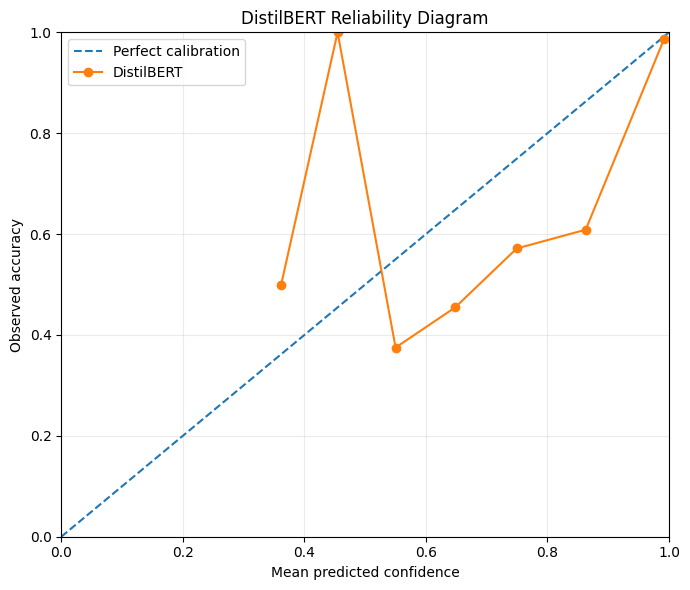

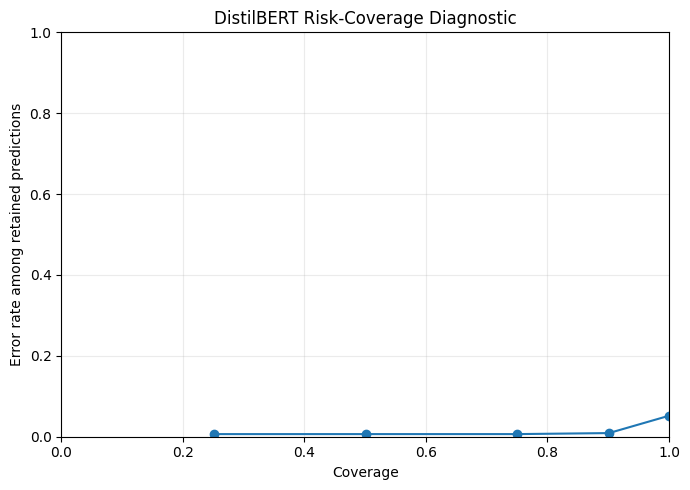


SECTION 7D — COMPLETED
Validation samples: 617
Total incorrect predictions: 32
Test samples accessed: 0
Calibration model fitted: No
Frozen partitions unchanged.

Results saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/results/distilbert/reliability_7d


In [18]:

# ============================================================
# GITREQ RESEARCH
# SECTION 7D — DISTILBERT CONFIDENCE AND RELIABILITY
# ============================================================

import pandas as pd
import numpy as np
import json
import hashlib
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, f1_score
from IPython.display import display

print("=" * 65)
print("SECTION 7D — CONFIDENCE AND RELIABILITY")
print("=" * 65)

# ------------------------------------------------------------
# 1. Verify the frozen validation dataset
# ------------------------------------------------------------

VAL_PATH_7D = (
    DATA_DIR / "splits_final" / "GitReq_validation.csv"
)

MANIFEST_PATH_7D = (
    RESULTS_DIR / "splits_final" / "frozen_manifest.json"
)

with open(MANIFEST_PATH_7D) as f:
    manifest_7d = json.load(f)

def sha256_7d(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

assert sha256_7d(VAL_PATH_7D) == (
    manifest_7d["partition_sha256"]["validation"]
)

validation_7d = pd.read_csv(VAL_PATH_7D)

assert len(validation_7d) == 617
assert validation_7d["requirement_id"].is_unique

# ------------------------------------------------------------
# 2. Load DistilBERT's saved validation probabilities
# ------------------------------------------------------------

PREDICTIONS_PATH_7D = (
    RESULTS_DIR / "distilbert" / "baseline_v1"
    / "validation_predictions.csv"
)

predictions_7d = pd.read_csv(PREDICTIONS_PATH_7D)

assert predictions_7d["requirement_id"].is_unique

CLASSES_7D = sorted(
    validation_7d["class_label"].unique()
)

assert len(CLASSES_7D) == 8

probability_columns_7d = [
    f"prob_{label}"
    for label in CLASSES_7D
]

required_columns_7d = [
    "requirement_id",
    "class_label",
    "predicted_label"
] + probability_columns_7d

assert set(required_columns_7d).issubset(
    predictions_7d.columns
)

# Align saved predictions with the frozen validation set.
data_7d = validation_7d[
    [
        "requirement_id",
        "RequirementText",
        "class_label",
        "repository_id"
    ]
].merge(
    predictions_7d[required_columns_7d].rename(
        columns={"class_label": "saved_label"}
    ),
    on="requirement_id",
    how="left",
    validate="one_to_one"
)

assert len(data_7d) == 617
assert data_7d[required_columns_7d[2:]].notna().all().all()

assert (
    data_7d["class_label"]
    == data_7d["saved_label"]
).all()

probabilities_7d = data_7d[
    probability_columns_7d
].to_numpy(dtype=np.float64)

assert np.isfinite(probabilities_7d).all()
assert (probabilities_7d >= 0).all()
assert (probabilities_7d <= 1).all()

assert np.allclose(
    probabilities_7d.sum(axis=1),
    1.0,
    atol=1e-4
)

# ------------------------------------------------------------
# 3. Validate predictions and prepare labels
# ------------------------------------------------------------

class_to_index_7d = {
    label: idx
    for idx, label in enumerate(CLASSES_7D)
}

actual_indices_7d = np.array([
    class_to_index_7d[label]
    for label in data_7d["class_label"]
])

predicted_indices_7d = probabilities_7d.argmax(axis=1)

predicted_labels_7d = np.array([
    CLASSES_7D[idx]
    for idx in predicted_indices_7d
])

assert np.array_equal(
    predicted_labels_7d,
    data_7d["predicted_label"].to_numpy()
)

correct_7d = (
    actual_indices_7d == predicted_indices_7d
)

confidence_7d = probabilities_7d.max(axis=1)

accuracy_7d = accuracy_score(
    data_7d["class_label"],
    predicted_labels_7d
)

macro_f1_7d = f1_score(
    data_7d["class_label"],
    predicted_labels_7d,
    labels=CLASSES_7D,
    average="macro",
    zero_division=0
)

print("New DistilBERT validation accuracy / macro-F1:", round(accuracy_7d, 6), round(macro_f1_7d, 6))

print("\nSaved DistilBERT predictions verified.")
print("Validation requirements:", len(data_7d))
print("Accuracy:", round(accuracy_7d, 4))
print("Macro F1:", round(macro_f1_7d, 4))
print("Test records accessed: 0")

# ------------------------------------------------------------
# 4. Calculate probability quality metrics
# ------------------------------------------------------------

eps_7d = 1e-12
n_7d = len(data_7d)

actual_probabilities_7d = probabilities_7d[
    np.arange(n_7d),
    actual_indices_7d
]

nll_7d = -np.mean(
    np.log(
        np.clip(actual_probabilities_7d, eps_7d, 1.0)
    )
)

one_hot_7d = np.eye(len(CLASSES_7D))[
    actual_indices_7d
]

# Multiclass Brier Score, summed over classes.
brier_7d = np.mean(
    np.sum(
        (probabilities_7d - one_hot_7d) ** 2,
        axis=1
    )
)

# ------------------------------------------------------------
# 5. Expected Calibration Error
# ------------------------------------------------------------

def calibration_bins_7d(
    confidences, correctness, n_bins=10
):

    edges = np.linspace(0.0, 1.0, n_bins + 1)

    rows = []

    for b in range(n_bins):

        lower = edges[b]
        upper = edges[b + 1]

        if b == n_bins - 1:
            mask = (
                (confidences >= lower)
                & (confidences <= upper)
            )
        else:
            mask = (
                (confidences >= lower)
                & (confidences < upper)
            )

        count = int(mask.sum())

        if count == 0:
            continue

        mean_conf = float(
            confidences[mask].mean()
        )

        observed_accuracy = float(
            correctness[mask].mean()
        )

        rows.append({
            "bin": b + 1,
            "lower": lower,
            "upper": upper,
            "count": count,
            "mean_confidence": mean_conf,
            "accuracy": observed_accuracy,
            "gap": abs(
                mean_conf - observed_accuracy
            )
        })

    result = pd.DataFrame(rows)

    ece = float(
        (
            result["count"]
            * result["gap"]
        ).sum() / len(confidences)
    )

    return result, ece

bins_10_7d, ece_10_7d = calibration_bins_7d(
    confidence_7d,
    correct_7d,
    n_bins=10
)

bins_5_7d, ece_5_7d = calibration_bins_7d(
    confidence_7d,
    correct_7d,
    n_bins=5
)

assert bins_10_7d["count"].sum() == n_7d

# ------------------------------------------------------------
# 6. Display reliability summary
# ------------------------------------------------------------

reliability_summary_7d = pd.DataFrame([{
    "accuracy": accuracy_7d,
    "macro_f1": macro_f1_7d,
    "mean_confidence": confidence_7d.mean(),
    "ECE_10_bins": ece_10_7d,
    "ECE_5_bins": ece_5_7d,
    "multiclass_brier": brier_7d,
    "NLL": nll_7d,
    "high_confidence_errors_90": int(
        ((~correct_7d) & (confidence_7d >= 0.90)).sum()
    ),
    "total_errors": int((~correct_7d).sum())
}])

print("\n--- RELIABILITY METRICS ---")
display(reliability_summary_7d.round(4))

print("\n--- CONFIDENCE BINS (10 BINS) ---")
display(bins_10_7d.round(4))

# ------------------------------------------------------------
# 7. Risk-coverage diagnostic
# ------------------------------------------------------------

# Coverage means the proportion of requirements retained.
# At lower coverage, the system can defer less-confident
# predictions to a human reviewer.

descending_indices_7d = np.argsort(
    -confidence_7d,
    kind="stable"
)

coverage_levels_7d = [
    0.25, 0.50, 0.75, 0.90, 1.00
]

risk_rows_7d = []

for requested_coverage in coverage_levels_7d:

    keep_n = int(
        np.ceil(requested_coverage * n_7d)
    )

    retained = descending_indices_7d[:keep_n]

    retained_accuracy = float(
        correct_7d[retained].mean()
    )

    retained_classes = len(
        np.unique(actual_indices_7d[retained])
    )

    risk_rows_7d.append({
        "requested_coverage": requested_coverage,
        "retained_requirements": keep_n,
        "actual_coverage": keep_n / n_7d,
        "accuracy": retained_accuracy,
        "error_rate": 1.0 - retained_accuracy,
        "classes_represented": retained_classes
    })

risk_table_7d = pd.DataFrame(risk_rows_7d)

print("\n--- RISK-COVERAGE RESULTS ---")
display(risk_table_7d.round(4))

# ------------------------------------------------------------
# 8. Confidence and accuracy by actual class
# ------------------------------------------------------------

data_7d["confidence"] = confidence_7d
data_7d["correct"] = correct_7d

per_class_confidence_7d = (
    data_7d.groupby("class_label")
    .agg(
        support=("requirement_id", "count"),
        accuracy=("correct", "mean"),
        mean_confidence=("confidence", "mean")
    )
    .reset_index()
)

print("\n--- PER-CLASS CONFIDENCE ---")
display(per_class_confidence_7d.round(4))

# ------------------------------------------------------------
# 9. Inspect highly confident mistakes
# ------------------------------------------------------------

errors_7d = data_7d.loc[
    ~data_7d["correct"],
    [
        "requirement_id",
        "RequirementText",
        "class_label",
        "predicted_label",
        "repository_id",
        "confidence"
    ]
].copy()

errors_7d = errors_7d.sort_values(
    "confidence",
    ascending=False
)

errors_7d["text_preview"] = (
    errors_7d["RequirementText"]
    .str.replace(r"\s+", " ", regex=True)
    .str.slice(0, 180)
)

print("\n--- TOP HIGH-CONFIDENCE ERRORS ---")
display(
    errors_7d[
        [
            "requirement_id",
            "class_label",
            "predicted_label",
            "confidence",
            "text_preview"
        ]
    ].head(15).round(4)
)

# ------------------------------------------------------------
# 10. Save figures and diagnostics
# ------------------------------------------------------------

RESULTS_7D = RESULTS_DIR / "distilbert" / "reliability_7d"

RESULTS_7D.mkdir(parents=True, exist_ok=True)

# Reliability diagram
fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

ax.plot(
    bins_10_7d["mean_confidence"],
    bins_10_7d["accuracy"],
    marker="o",
    label="DistilBERT"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.set_xlabel("Mean predicted confidence")
ax.set_ylabel("Observed accuracy")
ax.set_title("DistilBERT Reliability Diagram")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    RESULTS_7D / "reliability_diagram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Risk-coverage curve
fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    risk_table_7d["actual_coverage"],
    risk_table_7d["error_rate"],
    marker="o"
)

ax.set_xlabel("Coverage")
ax.set_ylabel("Error rate among retained predictions")
ax.set_title("DistilBERT Risk-Coverage Diagnostic")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    RESULTS_7D / "risk_coverage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Save tables
reliability_summary_7d.to_csv(
    RESULTS_7D / "reliability_metrics.csv",
    index=False
)

bins_10_7d.to_csv(
    RESULTS_7D / "calibration_bins_10.csv",
    index=False
)

risk_table_7d.to_csv(
    RESULTS_7D / "risk_coverage.csv",
    index=False
)

per_class_confidence_7d.to_csv(
    RESULTS_7D / "per_class_confidence.csv",
    index=False
)

errors_7d.to_csv(
    RESULTS_7D / "high_confidence_errors.csv",
    index=False
)

config_7d = {
    "experiment": "distilbert_raw_reliability",
    "status": "completed",
    "probabilities": "raw_softmax_uncalibrated",
    "calibration_fitting_performed": False,
    "validation_samples": 617,
    "test_samples_accessed": 0,
    "ece_primary_bins": 10,
    "ece_sensitivity_bins": 5,
    "brier_definition": (
        "mean sum of squared multiclass probability errors"
    ),
    "frozen_validation_sha256": sha256_7d(VAL_PATH_7D),
    "interpretation_limit": (
        "Validation was used for model selection. "
        "These diagnostics are exploratory."
    )
}

with open(
    RESULTS_7D / "experiment_config.json",
    "w"
) as f:
    json.dump(config_7d, f, indent=4)

print("\n" + "=" * 65)
print("SECTION 7D — COMPLETED")
print("=" * 65)
print("Validation samples:", len(data_7d))
print("Total incorrect predictions:", len(errors_7d))
print("Test samples accessed: 0")
print("Calibration model fitted: No")
print("Frozen partitions unchanged.")
print("\nResults saved to:")
print(RESULTS_7D)
print("=" * 65)


In [19]:

# ============================================================
# GITREQ RESEARCH
# SECTION 7E — CROSS-FITTED TEMPERATURE CALIBRATION
# ============================================================

import numpy as np
import pandas as pd
import json
import hashlib

from scipy.optimize import minimize_scalar
from scipy.special import softmax
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score
from IPython.display import display

print("=" * 65)
print("SECTION 7E — CROSS-FITTED TEMPERATURE CALIBRATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Verify frozen validation partition
# ------------------------------------------------------------

VAL_PATH_7E = (
    DATA_DIR / "splits_final"
    / "GitReq_validation.csv"
)

with open(
    RESULTS_DIR / "splits_final" / "frozen_manifest.json"
) as f:
    frozen_7e = json.load(f)

def sha256_7e(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

assert sha256_7e(VAL_PATH_7E) == (
    frozen_7e["partition_sha256"]["validation"]
)

val_7e = pd.read_csv(VAL_PATH_7E)

assert len(val_7e) == 617
assert val_7e["requirement_id"].is_unique

PRED_PATH_7E = (
    RESULTS_DIR / "distilbert" / "baseline_v1"
    / "validation_predictions.csv"
)

saved_7e = pd.read_csv(PRED_PATH_7E)

assert saved_7e["requirement_id"].is_unique

CLASSES_7E = sorted(val_7e["class_label"].unique())

prob_columns_7e = [
    f"prob_{label}" for label in CLASSES_7E
]

assert all(
    column in saved_7e.columns
    for column in prob_columns_7e
)

# Align predictions by requirement ID.
data_7e = val_7e[
    ["requirement_id", "class_label", "repository_id"]
].merge(
    saved_7e[
        ["requirement_id", "class_label",
         "predicted_label"] + prob_columns_7e
    ].rename(columns={
        "class_label": "saved_true_label"
    }),
    on="requirement_id",
    how="left",
    validate="one_to_one"
)

assert len(data_7e) == 617
assert data_7e[prob_columns_7e].notna().all().all()
assert (
    data_7e["class_label"]
    == data_7e["saved_true_label"]
).all()

probs_7e = data_7e[
    prob_columns_7e
].to_numpy(dtype=np.float64)

assert np.isfinite(probs_7e).all()
assert np.all(probs_7e >= 0)
assert np.allclose(
    probs_7e.sum(axis=1), 1.0, atol=1e-4
)

class_to_id_7e = {
    label: i for i, label in enumerate(CLASSES_7E)
}

y_7e = np.array([
    class_to_id_7e[label]
    for label in data_7e["class_label"]
])

groups_7e = data_7e["repository_id"].to_numpy()

original_preds_7e = probs_7e.argmax(axis=1)

assert np.array_equal(
    np.array(CLASSES_7E)[original_preds_7e],
    data_7e["predicted_label"].to_numpy()
)

print("Reproduced pre-calibration validation macro-F1:", f1_score(y_7e, original_preds_7e, average="macro", zero_division=0))

print("\nValidation data and predictions verified.")
print("Requirements:", len(data_7e))
print("Repositories:", len(np.unique(groups_7e)))
print("Test records accessed: 0")

# ------------------------------------------------------------
# 2. Define temperature scaling
# ------------------------------------------------------------

# Applying temperature scaling to log probabilities is
# equivalent to scaling logits, up to an additive constant.

def scale_probs_7e(probabilities, temperature):

    assert temperature > 0

    log_probs = np.log(
        np.clip(probabilities, 1e-12, 1.0)
    )

    return softmax(
        log_probs / temperature,
        axis=1
    )

def nll_7e(probabilities, labels):

    selected = probabilities[
        np.arange(len(labels)), labels
    ]

    return float(
        -np.log(
            np.clip(selected, 1e-12, 1.0)
        ).mean()
    )

def brier_7e(probabilities, labels):

    one_hot = np.eye(
        probabilities.shape[1]
    )[labels]

    return float(np.mean(
        np.sum(
            (probabilities - one_hot) ** 2,
            axis=1
        )
    ))

def ece_7e(probabilities, labels, n_bins=10):

    confidence = probabilities.max(axis=1)

    predictions = probabilities.argmax(axis=1)

    correct = predictions == labels

    bin_ids = np.minimum(
        (confidence * n_bins).astype(int),
        n_bins - 1
    )

    total = len(labels)
    error = 0.0

    for b in range(n_bins):

        mask = bin_ids == b

        if not np.any(mask):
            continue

        average_conf = confidence[mask].mean()
        observed_acc = correct[mask].mean()

        error += (
            mask.sum() / total
            * abs(average_conf - observed_acc)
        )

    return float(error)

# ------------------------------------------------------------
# 3. Define temperature fitting
# ------------------------------------------------------------

def fit_temperature_7e(probabilities, labels):

    # Optimize log temperature for numerical stability.
    # Bounds correspond to temperatures 0.2 to 5.0.

    def objective(log_temperature):

        temperature = np.exp(log_temperature)

        calibrated = scale_probs_7e(
            probabilities, temperature
        )

        return nll_7e(calibrated, labels)

    result = minimize_scalar(
        objective,
        method="bounded",
        bounds=(np.log(0.2), np.log(5.0)),
        options={"xatol": 1e-7}
    )

    assert result.success

    return float(np.exp(result.x))

# ------------------------------------------------------------
# 4. Five-fold repository-disjoint cross-fitting
# ------------------------------------------------------------

FOLDS_7E = 5

group_cv_7e = GroupKFold(n_splits=FOLDS_7E)

out_of_fold_probs_7e = np.full_like(
    probs_7e,
    np.nan,
    dtype=np.float64
)

assigned_7e = np.zeros(
    len(data_7e),
    dtype=int
)

fold_rows_7e = []

for fold, (fit_idx, holdout_idx) in enumerate(
    group_cv_7e.split(
        probs_7e,
        y_7e,
        groups=groups_7e
    ),
    start=1
):

    assert set(groups_7e[fit_idx]).isdisjoint(
        set(groups_7e[holdout_idx])
    )

    temperature = fit_temperature_7e(
        probs_7e[fit_idx],
        y_7e[fit_idx]
    )

    calibrated_fold = scale_probs_7e(
        probs_7e[holdout_idx],
        temperature
    )

    out_of_fold_probs_7e[holdout_idx] = calibrated_fold
    assigned_7e[holdout_idx] += 1

    fold_rows_7e.append({
        "fold": fold,
        "fit_records": len(fit_idx),
        "heldout_records": len(holdout_idx),
        "temperature": temperature,
        "raw_heldout_nll": nll_7e(
            probs_7e[holdout_idx],
            y_7e[holdout_idx]
        ),
        "calibrated_heldout_nll": nll_7e(
            calibrated_fold,
            y_7e[holdout_idx]
        )
    })

assert np.all(assigned_7e == 1)
assert np.isfinite(out_of_fold_probs_7e).all()

# Positive temperature does not change the top class.
assert np.array_equal(
    out_of_fold_probs_7e.argmax(axis=1),
    original_preds_7e
)

fold_table_7e = pd.DataFrame(fold_rows_7e)

print("\n--- CALIBRATION FOLDS ---")
display(fold_table_7e.round(4))

# ------------------------------------------------------------
# 5. Evaluate raw vs cross-fitted probabilities
# ------------------------------------------------------------

metric_rows_7e = []

for name, probabilities in [
    ("raw_softmax", probs_7e),
    ("cross_fitted_temperature", out_of_fold_probs_7e)
]:

    metric_rows_7e.append({
        "method": name,
        "accuracy": accuracy_score(
            y_7e, probabilities.argmax(axis=1)
        ),
        "macro_f1": f1_score(
            y_7e,
            probabilities.argmax(axis=1),
            average="macro",
            zero_division=0
        ),
        "mean_confidence": float(
            probabilities.max(axis=1).mean()
        ),
        "ECE_10": ece_7e(
            probabilities, y_7e, 10
        ),
        "ECE_5": ece_7e(
            probabilities, y_7e, 5
        ),
        "Brier": brier_7e(
            probabilities, y_7e
        ),
        "NLL": nll_7e(
            probabilities, y_7e
        )
    })

calibration_metrics_7e = pd.DataFrame(
    metric_rows_7e
)

print("\n--- RAW VS CROSS-FITTED CALIBRATION ---")
display(calibration_metrics_7e.round(4))

# ------------------------------------------------------------
# 6. Evaluate selective prediction by true class
# ------------------------------------------------------------

THRESHOLDS_7E = [0.90, 0.95]

selectivity_rows_7e = []

for method, probabilities in [
    ("raw_softmax", probs_7e),
    ("cross_fitted_temperature", out_of_fold_probs_7e)
]:

    confidence = probabilities.max(axis=1)
    correct = probabilities.argmax(axis=1) == y_7e

    for threshold in THRESHOLDS_7E:

        for class_idx, label in enumerate(CLASSES_7E):

            class_mask = y_7e == class_idx

            accepted = class_mask & (
                confidence >= threshold
            )

            total = int(class_mask.sum())
            accepted_n = int(accepted.sum())

            accepted_accuracy = (
                float(correct[accepted].mean())
                if accepted_n > 0
                else np.nan
            )

            selectivity_rows_7e.append({
                "method": method,
                "threshold": threshold,
                "class_label": label,
                "total": total,
                "accepted": accepted_n,
                "referred_for_review": total - accepted_n,
                "class_coverage": accepted_n / total,
                "accepted_accuracy": accepted_accuracy
            })

selectivity_7e = pd.DataFrame(
    selectivity_rows_7e
)

print("\n--- CLASS-WISE AUTOMATIC COVERAGE (90%) ---")

display(
    selectivity_7e.loc[
        selectivity_7e["threshold"] == 0.90,
        [
            "method",
            "class_label",
            "total",
            "accepted",
            "referred_for_review",
            "class_coverage",
            "accepted_accuracy"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 7. Overall selective prediction performance
# ------------------------------------------------------------

overall_rows_7e = []

for method, probabilities in [
    ("raw_softmax", probs_7e),
    ("cross_fitted_temperature", out_of_fold_probs_7e)
]:

    confidence = probabilities.max(axis=1)
    correct = probabilities.argmax(axis=1) == y_7e

    for threshold in THRESHOLDS_7E:

        accepted = confidence >= threshold

        n_accepted = int(accepted.sum())

        overall_rows_7e.append({
            "method": method,
            "threshold": threshold,
            "accepted": n_accepted,
            "referred_for_review": (
                len(y_7e) - n_accepted
            ),
            "coverage": n_accepted / len(y_7e),
            "accepted_accuracy": (
                float(correct[accepted].mean())
                if n_accepted else np.nan
            ),
            "accepted_errors": int(
                (~correct[accepted]).sum()
            )
        })

overall_7e = pd.DataFrame(overall_rows_7e)

print("\n--- OVERALL SELECTIVE PERFORMANCE ---")
display(overall_7e.round(4))

# ------------------------------------------------------------
# 8. Fit final temperature on all validation data
# ------------------------------------------------------------

# This temperature is for later test-set application.
# DO NOT evaluate it on the same validation data as if
# that were an independent calibration assessment.

final_temperature_7e = fit_temperature_7e(
    probs_7e,
    y_7e
)

print("\nFinal temperature fitted on full validation:")
print(round(final_temperature_7e, 6))

# ------------------------------------------------------------
# 9. Save results and final calibration parameter
# ------------------------------------------------------------

RESULTS_7E = (
    RESULTS_DIR / "distilbert" / "calibration_7e"
)

RESULTS_7E.mkdir(parents=True, exist_ok=True)

fold_table_7e.to_csv(
    RESULTS_7E / "crossfit_folds.csv",
    index=False
)

calibration_metrics_7e.to_csv(
    RESULTS_7E / "calibration_comparison.csv",
    index=False
)

selectivity_7e.to_csv(
    RESULTS_7E / "classwise_selectivity.csv",
    index=False
)

overall_7e.to_csv(
    RESULTS_7E / "overall_selectivity.csv",
    index=False
)

oof_predictions_7e = data_7e[
    ["requirement_id", "class_label", "repository_id"]
].copy()

for idx, label in enumerate(CLASSES_7E):
    oof_predictions_7e[
        f"calibrated_prob_{label}"
    ] = out_of_fold_probs_7e[:, idx]

oof_predictions_7e.to_csv(
    RESULTS_7E / "crossfitted_probabilities.csv",
    index=False
)

final_config_7e = {
    "experiment": "repository_grouped_temperature_scaling",
    "status": "completed",
    "method": "scalar_temperature",
    "objective": "negative_log_likelihood",
    "temperature_bounds": [0.2, 5.0],
    "folds": FOLDS_7E,
    "crossfit_group": "repository_id",
    "final_temperature": final_temperature_7e,
    "num_classes": len(CLASSES_7E),
    "class_names": CLASSES_7E,
    "validation_samples": len(data_7e),
    "test_samples_accessed": 0,
    "frozen_validation_sha256": sha256_7e(
        VAL_PATH_7E
    ),
    "model": "distilbert_baseline_v1",
    "warning": (
        "Cross-fitted calibration is exploratory "
        "because the model checkpoint was selected "
        "using the same validation partition. "
        "The final fitted temperature must be "
        "evaluated on independent held-out test data."
    )
}

config_path_7e = (
    RESULTS_7E / "temperature_calibration.json"
)

if config_path_7e.exists():
    with open(config_path_7e) as f:
        existing_7e = json.load(f)

    assert np.isclose(
        existing_7e["final_temperature"],
        final_temperature_7e,
        atol=1e-6
    ), "An existing calibration temperature differs."

with open(config_path_7e, "w") as f:
    json.dump(final_config_7e, f, indent=4)

print("\n" + "=" * 65)
print("SECTION 7E — COMPLETED")
print("=" * 65)

print("Validation samples:", len(data_7e))
print("Cross-fitting folds:", FOLDS_7E)
print("Final temperature:", round(final_temperature_7e, 6))
print("Held-out test accessed: 0")
print("Neural network retrained: No")

print("\nResults saved to:")
print(RESULTS_7E)

print("\nFrozen dataset partitions unchanged.")
print("=" * 65)


SECTION 7E — CROSS-FITTED TEMPERATURE CALIBRATION
Reproduced pre-calibration validation macro-F1: 0.8743912819969129

Validation data and predictions verified.
Requirements: 617
Repositories: 410
Test records accessed: 0

--- CALIBRATION FOLDS ---


,fold,fit_records,heldout_records,temperature,raw_heldout_nll,calibrated_heldout_nll
0,1,493,124,1.1113,0.1450,0.1457
1,2,493,124,1.0555,0.3706,0.3641
2,3,494,123,1.1102,0.1396,0.1400
3,4,494,123,1.1277,0.0818,0.0874
4,5,494,123,1.0808,0.1581,0.1532



--- RAW VS CROSS-FITTED CALIBRATION ---


,method,accuracy,macro_f1,mean_confidence,ECE_10,ECE_5,Brier,NLL
0,raw_softmax,0.9481,0.8744,0.9660,0.0250,0.0204,0.0808,0.1793
1,cross_fitted_temperature,0.9481,0.8744,0.9579,0.0239,0.0137,0.0798,0.1783



--- CLASS-WISE AUTOMATIC COVERAGE (90%) ---


,method,class_label,total,accepted,referred_for_review,class_coverage,accepted_accuracy
0,raw_softmax,Availability,79,76,3,0.9620,1.0000
1,raw_softmax,Fault-tolerance,28,25,3,0.8929,0.9600
2,raw_softmax,Functional,50,49,1,0.9800,1.0000
3,raw_softmax,Maintainability,11,1,10,0.0909,1.0000
4,raw_softmax,Performance,131,129,2,0.9847,1.0000
5,raw_softmax,Portability,136,127,9,0.9338,0.9764
6,raw_softmax,Scalability,24,2,22,0.0833,0.0000
7,raw_softmax,Security,158,152,6,0.9620,0.9934
16,cross_fitted_temperature,Availability,79,76,3,0.9620,1.0000
17,cross_fitted_temperature,Fault-tolerance,28,25,3,0.8929,0.9600



--- OVERALL SELECTIVE PERFORMANCE ---


,method,threshold,accepted,referred_for_review,coverage,accepted_accuracy,accepted_errors
0,raw_softmax,0.90,561,56,0.9092,0.9875,7
1,raw_softmax,0.95,554,63,0.8979,0.9910,5
2,cross_fitted_temperature,0.90,559,58,0.9060,0.9893,6
3,cross_fitted_temperature,0.95,545,72,0.8833,0.9927,4



Final temperature fitted on full validation:
1.098397

SECTION 7E — COMPLETED
Validation samples: 617
Cross-fitting folds: 5
Final temperature: 1.098397
Held-out test accessed: 0
Neural network retrained: No

Results saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/results/distilbert/calibration_7e

Frozen dataset partitions unchanged.


In [20]:

# ============================================================
# GITREQ RESEARCH
# SECTION 8A — CONTROLLED INFERENCE EFFICIENCY
# ============================================================

import os
import gc
import json
import time
import hashlib
import joblib

import numpy as np
import pandas as pd
import torch

from pathlib import Path
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
from IPython.display import display

print("=" * 65)
print("SECTION 8A — INFERENCE EFFICIENCY BENCHMARK")
print("=" * 65)

# ------------------------------------------------------------
# 1. Verify frozen validation data
# ------------------------------------------------------------

VAL_PATH_8A = (
    DATA_DIR / "splits_final" / "GitReq_validation.csv"
)

MANIFEST_PATH_8A = (
    RESULTS_DIR / "splits_final" / "frozen_manifest.json"
)

with open(MANIFEST_PATH_8A) as f:
    frozen_8a = json.load(f)

def sha256_8a(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

assert sha256_8a(VAL_PATH_8A) == (
    frozen_8a["partition_sha256"]["validation"]
)

validation_8a = pd.read_csv(VAL_PATH_8A)

assert len(validation_8a) == 617
assert validation_8a["requirement_id"].is_unique

print("\nFrozen validation dataset verified.")
print("Validation requirements:", len(validation_8a))
print("Held-out test accessed: 0")

# ------------------------------------------------------------
# 2. Fixed benchmark configuration
# ------------------------------------------------------------

BENCHMARK_SEED_8A = 42
BENCHMARK_SAMPLES_8A = 256
BATCH_SIZE_8A = 16
WARMUPS_8A = 1
REPEATS_8A = 5

MAX_LENGTH_8A = 192

# Limit CPU thread oversubscription.
CPU_THREADS_8A = min(os.cpu_count() or 2, 4)
torch.set_num_threads(CPU_THREADS_8A)

rng_8a = np.random.default_rng(
    BENCHMARK_SEED_8A
)

selected_indices_8a = np.sort(
    rng_8a.choice(
        len(validation_8a),
        size=BENCHMARK_SAMPLES_8A,
        replace=False
    )
)

benchmark_data_8a = validation_8a.iloc[
    selected_indices_8a
].copy()

benchmark_texts_8a = (
    benchmark_data_8a["RequirementText"]
    .astype(str)
    .tolist()
)

benchmark_ids_8a = (
    benchmark_data_8a["requirement_id"]
    .tolist()
)

print("\nBenchmark samples:", BENCHMARK_SAMPLES_8A)
print("Batch size:", BATCH_SIZE_8A)
print("Warm-up repetitions:", WARMUPS_8A)
print("Timed repetitions:", REPEATS_8A)
print("CPU threads:", CPU_THREADS_8A)

# ------------------------------------------------------------
# 3. Load saved models
# ------------------------------------------------------------

SVM_PATH_8A = (
    MODELS_DIR / "ml_class_weight_experiment"
    / "balanced_linear_svm.joblib"
)

BERT_DIR_8A = (
    MODELS_DIR / "distilbert" / "baseline_v1"
)

assert SVM_PATH_8A.exists()
assert (BERT_DIR_8A / "config.json").exists()
assert (BERT_DIR_8A / "model.safetensors").exists()

svm_8a = joblib.load(SVM_PATH_8A)

tokenizer_8a = AutoTokenizer.from_pretrained(
    str(BERT_DIR_8A),
    local_files_only=True,
    use_fast=True
)

bert_8a = (
    AutoModelForSequenceClassification.from_pretrained(
        str(BERT_DIR_8A),
        local_files_only=True
    )
)

bert_8a.eval()
bert_8a.to("cpu")

assert bert_8a.config.num_labels == 8

parameter_count_8a = sum(
    p.numel() for p in bert_8a.parameters()
)

print("\nModels loaded successfully.")
print("DistilBERT parameters:", parameter_count_8a)

# ------------------------------------------------------------
# 4. Define identical input batches
# ------------------------------------------------------------

text_batches_8a = [
    benchmark_texts_8a[i:i + BATCH_SIZE_8A]
    for i in range(
        0,
        len(benchmark_texts_8a),
        BATCH_SIZE_8A
    )
]

assert sum(
    len(batch) for batch in text_batches_8a
) == BENCHMARK_SAMPLES_8A

# ------------------------------------------------------------
# 5. Prediction functions
# ------------------------------------------------------------

def predict_svm_8a():

    predictions = []

    for batch in text_batches_8a:

        # Includes TF-IDF text transformation
        # and classification.
        result = svm_8a.predict(batch)

        predictions.extend(result.tolist())

    return np.asarray(predictions)


def predict_bert_8a(device):

    prediction_ids = []

    with torch.inference_mode():

        for batch in text_batches_8a:

            # Includes tokenization and dynamic padding.
            inputs = tokenizer_8a(
                batch,
                truncation=True,
                padding=True,
                max_length=MAX_LENGTH_8A,
                return_tensors="pt"
            )

            inputs = {
                key: value.to(device)
                for key, value in inputs.items()
            }

            logits = bert_8a(**inputs).logits

            ids = logits.argmax(dim=1)

            prediction_ids.extend(
                ids.cpu().numpy().tolist()
            )

    return np.asarray([
        bert_8a.config.id2label[int(idx)]
        for idx in prediction_ids
    ])

# ------------------------------------------------------------
# 6. Verify predictions against saved experiment results
# ------------------------------------------------------------

SVM_PRED_PATH_8A = (
    RESULTS_DIR / "ml_class_weight_experiment"
    / "balanced_linear_svm_validation_predictions.csv"
)

BERT_PRED_PATH_8A = (
    RESULTS_DIR / "distilbert" / "baseline_v1"
    / "validation_predictions.csv"
)

svm_reference_8a = pd.read_csv(
    SVM_PRED_PATH_8A
).set_index("requirement_id")

bert_reference_8a = pd.read_csv(
    BERT_PRED_PATH_8A
).set_index("requirement_id")

expected_svm_8a = (
    svm_reference_8a
    .loc[benchmark_ids_8a, "predicted_label"]
    .to_numpy()
)

expected_bert_8a = (
    bert_reference_8a
    .loc[benchmark_ids_8a, "predicted_label"]
    .to_numpy()
)

observed_svm_8a = predict_svm_8a()
observed_bert_cpu_8a = predict_bert_8a(
    torch.device("cpu")
)

assert np.array_equal(
    observed_svm_8a,
    expected_svm_8a
)

assert np.array_equal(
    observed_bert_cpu_8a,
    expected_bert_8a
)

print("\nSaved predictions independently reproduced.")
print("SVM predictions: verified")
print("DistilBERT CPU predictions: verified")

# ------------------------------------------------------------
# 7. Benchmark helper
# ------------------------------------------------------------

timing_rows_8a = []

def benchmark_8a(name, prediction_fn, device):

    for _ in range(WARMUPS_8A):

        prediction_fn()

        if device == "cuda":
            torch.cuda.synchronize()

    times = []

    for repeat in range(REPEATS_8A):

        gc.collect()

        if device == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        prediction_fn()

        if device == "cuda":
            torch.cuda.synchronize()

        seconds = time.perf_counter() - start

        times.append(seconds)

    median_seconds = float(np.median(times))

    result = {
        "model_device": name,
        "samples": BENCHMARK_SAMPLES_8A,
        "batch_size": BATCH_SIZE_8A,
        "median_total_seconds": median_seconds,
        "mean_total_seconds": float(np.mean(times)),
        "std_total_seconds": float(np.std(times)),
        "ms_per_requirement": (
            median_seconds
            / BENCHMARK_SAMPLES_8A
            * 1000
        ),
        "requirements_per_second": (
            BENCHMARK_SAMPLES_8A
            / median_seconds
        )
    }

    timing_rows_8a.append(result)

    print("\n", name)
    print(
        "Median total seconds:",
        round(median_seconds, 4)
    )
    print(
        "Milliseconds/requirement:",
        round(result["ms_per_requirement"], 4)
    )
    print(
        "Requirements/second:",
        round(result["requirements_per_second"], 2)
    )

# ------------------------------------------------------------
# 8. CPU measurements
# ------------------------------------------------------------

print("\n--- CPU BENCHMARKS ---")

benchmark_8a(
    "balanced_svm_cpu",
    predict_svm_8a,
    "cpu"
)

benchmark_8a(
    "distilbert_cpu",
    lambda: predict_bert_8a(torch.device("cpu")),
    "cpu"
)

# ------------------------------------------------------------
# 9. GPU measurement (DistilBERT only)
# ------------------------------------------------------------

GPU_NAME_8A = None

if torch.cuda.is_available():

    GPU_NAME_8A = torch.cuda.get_device_name(0)

    print("\n--- DISTILBERT GPU BENCHMARK ---")
    print("GPU:", GPU_NAME_8A)

    bert_8a.to("cuda")
    bert_8a.eval()

    # Verify GPU predictions before timing.
    observed_bert_gpu_8a = predict_bert_8a(
        torch.device("cuda")
    )

    assert np.array_equal(
        observed_bert_gpu_8a,
        expected_bert_8a
    )

    benchmark_8a(
        "distilbert_gpu",
        lambda: predict_bert_8a(
            torch.device("cuda")
        ),
        "cuda"
    )

else:
    print("\nNo GPU available; GPU benchmark skipped.")

# ------------------------------------------------------------
# 10. Measure model storage
# ------------------------------------------------------------

def directory_size_8a(path):

    return sum(
        file.stat().st_size
        for file in path.rglob("*")
        if file.is_file()
    )

svm_size_mb_8a = (
    SVM_PATH_8A.stat().st_size / (1024 ** 2)
)

bert_size_mb_8a = (
    directory_size_8a(BERT_DIR_8A) / (1024 ** 2)
)

storage_table_8a = pd.DataFrame([
    {
        "model": "balanced_linear_svm",
        "saved_storage_mb": svm_size_mb_8a,
        "parameters": np.nan
    },
    {
        "model": "distilbert",
        "saved_storage_mb": bert_size_mb_8a,
        "parameters": parameter_count_8a
    }
])

print("\n--- SAVED MODEL STORAGE ---")
display(storage_table_8a.round(4))

# ------------------------------------------------------------
# 11. Display benchmark comparison
# ------------------------------------------------------------

timing_table_8a = pd.DataFrame(
    timing_rows_8a
)

print("\n--- INFERENCE EFFICIENCY COMPARISON ---")

display(timing_table_8a.round(4))

# ------------------------------------------------------------
# 12. Save research artifacts
# ------------------------------------------------------------

RESULTS_8A = RESULTS_DIR / "efficiency_benchmark_8a"

RESULTS_8A.mkdir(
    parents=True,
    exist_ok=True
)

timing_table_8a.to_csv(
    RESULTS_8A / "inference_timings.csv",
    index=False
)

storage_table_8a.to_csv(
    RESULTS_8A / "model_storage.csv",
    index=False
)

benchmark_data_8a[
    ["requirement_id", "repository_id", "class_label"]
].to_csv(
    RESULTS_8A / "benchmark_samples.csv",
    index=False
)

config_8a = {
    "experiment": "controlled_inference_efficiency",
    "status": "completed",
    "benchmark_samples": BENCHMARK_SAMPLES_8A,
    "batch_size": BATCH_SIZE_8A,
    "warmups": WARMUPS_8A,
    "timed_repetitions": REPEATS_8A,
    "sampling_seed": BENCHMARK_SEED_8A,
    "max_length": MAX_LENGTH_8A,
    "cpu_threads": CPU_THREADS_8A,
    "cpu_description": os.cpu_count(),
    "gpu_name": GPU_NAME_8A,
    "includes_text_processing": True,
    "includes_model_loading": False,
    "includes_calibration": False,
    "test_records_accessed": 0,
    "validation_sha256": sha256_8a(VAL_PATH_8A),
    "interpretation_limit": (
        "These are environment-specific inference "
        "measurements. CPU results are most directly "
        "comparable; GPU results use different hardware."
    )
}

with open(
    RESULTS_8A / "benchmark_config.json",
    "w"
) as f:
    json.dump(config_8a, f, indent=4)

print("\n" + "=" * 65)
print("SECTION 8A — COMPLETED")
print("=" * 65)

print("Validation samples benchmarked:", BENCHMARK_SAMPLES_8A)
print("Repetitions:", REPEATS_8A)
print("Models compared: Balanced SVM, DistilBERT")
print("Test records accessed: 0")
print("Frozen partitions unchanged.")

print("\nResults saved to:")
print(RESULTS_8A)

print("=" * 65)


SECTION 8A — INFERENCE EFFICIENCY BENCHMARK

Frozen validation dataset verified.
Validation requirements: 617
Held-out test accessed: 0

Benchmark samples: 256
Batch size: 16
Warm-up repetitions: 1
Timed repetitions: 5
CPU threads: 2

Models loaded successfully.
DistilBERT parameters: 66959624

Saved predictions independently reproduced.
SVM predictions: verified
DistilBERT CPU predictions: verified

--- CPU BENCHMARKS ---

 balanced_svm_cpu
Median total seconds: 0.0385
Milliseconds/requirement: 0.1503
Requirements/second: 6653.56

 distilbert_cpu
Median total seconds: 25.6643
Milliseconds/requirement: 100.2514
Requirements/second: 9.97

--- DISTILBERT GPU BENCHMARK ---
GPU: Tesla T4

 distilbert_gpu
Median total seconds: 0.7647
Milliseconds/requirement: 2.9872
Requirements/second: 334.76

--- SAVED MODEL STORAGE ---


,model,saved_storage_mb,parameters
0,balanced_linear_svm,1.7264,NaN
1,distilbert,256.3498,66959624.0



--- INFERENCE EFFICIENCY COMPARISON ---


,model_device,samples,batch_size,median_total_seconds,mean_total_seconds,std_total_seconds,ms_per_requirement,requirements_per_second
0,balanced_svm_cpu,256,16,0.0385,0.0384,0.0014,0.1503,6653.5562
1,distilbert_cpu,256,16,25.6643,26.1236,1.0747,100.2514,9.9749
2,distilbert_gpu,256,16,0.7647,0.7637,0.0053,2.9872,334.7577



SECTION 8A — COMPLETED
Validation samples benchmarked: 256
Repetitions: 5
Models compared: Balanced SVM, DistilBERT
Test records accessed: 0
Frozen partitions unchanged.

Results saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/results/efficiency_benchmark_8a


In [21]:

# ============================================================
# GITREQ RESEARCH
# SECTION 8B — FREEZE FINAL EVALUATION PROTOCOL
# ============================================================

from pathlib import Path
import hashlib
import json
import pandas as pd
import numpy as np

print("=" * 65)
print("SECTION 8B — FINAL EVALUATION PROTOCOL FREEZE")
print("=" * 65)

# ------------------------------------------------------------
# 1. Reusable SHA-256 function
# ------------------------------------------------------------

def file_hash_8b(path):

    path = Path(path)

    assert path.exists(), f"Missing file: {path}"

    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()

# ------------------------------------------------------------
# 2. Verify frozen dataset manifest
# ------------------------------------------------------------

FROZEN_MANIFEST_PATH_8B = (
    RESULTS_DIR / "splits_final"
    / "frozen_manifest.json"
)

with open(FROZEN_MANIFEST_PATH_8B) as f:
    frozen_8b = json.load(f)

assert frozen_8b["status"] == "FROZEN"
assert frozen_8b["requirements"] == 6300

TRAIN_8B = DATA_DIR / "splits_final" / "GitReq_train.csv"
VAL_8B = DATA_DIR / "splits_final" / "GitReq_validation.csv"

# The test file is identified but NOT read.
TEST_8B = DATA_DIR / "splits_final" / "GitReq_test.csv"

assert TEST_8B.exists()

assert file_hash_8b(TRAIN_8B) == (
    frozen_8b["partition_sha256"]["train"]
)

assert file_hash_8b(VAL_8B) == (
    frozen_8b["partition_sha256"]["validation"]
)

assert frozen_8b["partition_sizes"] == {
    "train": 4384,
    "validation": 617,
    "test": 1299
}

train_8b = pd.read_csv(TRAIN_8B)
val_8b = pd.read_csv(VAL_8B)

assert len(train_8b) == 4384
assert len(val_8b) == 617

assert set(train_8b["repository_id"]).isdisjoint(
    set(val_8b["repository_id"])
)

CLASSES_8B = sorted(
    train_8b["class_label"].unique()
)

assert len(CLASSES_8B) == 8

print("\nDataset manifest verified.")
print("Training:", len(train_8b))
print("Validation:", len(val_8b))
print("Held-out test contents accessed: 0")

# ------------------------------------------------------------
# 3. Verify traditional ML model files
# ------------------------------------------------------------

ML_MODEL_FILES_8B = {
    "dummy_majority": (
        MODELS_DIR / "ml_baselines_v1"
        / "dummy_majority.joblib"
    ),
    "tfidf_logistic_regression": (
        MODELS_DIR / "ml_baselines_v1"
        / "tfidf_logistic_regression.joblib"
    ),
    "tfidf_linear_svm": (
        MODELS_DIR / "ml_baselines_v1"
        / "tfidf_linear_svm.joblib"
    ),
    "balanced_logistic_regression": (
        MODELS_DIR / "ml_class_weight_experiment"
        / "balanced_logistic_regression.joblib"
    ),
    "balanced_linear_svm": (
        MODELS_DIR / "ml_class_weight_experiment"
        / "balanced_linear_svm.joblib"
    )
}

model_hashes_8b = {}

for name, path in ML_MODEL_FILES_8B.items():

    model_hashes_8b[name] = {
        "path": str(path),
        "sha256": file_hash_8b(path)
    }

# ------------------------------------------------------------
# 4. Verify saved DistilBERT checkpoint
# ------------------------------------------------------------

BERT_MODEL_DIR_8B = (
    MODELS_DIR / "distilbert" / "baseline_v1"
)

BERT_FILES_8B = [
    "model.safetensors",
    "config.json",
    "tokenizer.json",
    "tokenizer_config.json"
]

bert_hashes_8b = {}

for filename in BERT_FILES_8B:

    path = BERT_MODEL_DIR_8B / filename

    bert_hashes_8b[filename] = (
        file_hash_8b(path)
    )

BERT_MANIFEST_PATH_8B = (
    RESULTS_DIR / "distilbert" / "baseline_v1"
    / "experiment_manifest.json"
)

with open(BERT_MANIFEST_PATH_8B) as f:
    bert_manifest_8b = json.load(f)

assert bert_manifest_8b["status"] == "completed"
assert bert_manifest_8b["num_classes"] == 8
assert bert_manifest_8b["max_length"] == 192
assert bert_manifest_8b["epochs"] == 4

assert bert_manifest_8b["train_sha256"] == (
    frozen_8b["partition_sha256"]["train"]
)

assert bert_manifest_8b["validation_sha256"] == (
    frozen_8b["partition_sha256"]["validation"]
)

assert np.isfinite(bert_manifest_8b["best_validation_macro_f1"])

model_hashes_8b["distilbert"] = {
    "path": str(BERT_MODEL_DIR_8B),
    "file_sha256": bert_hashes_8b
}

print("\nAll six model artifacts verified.")

# ------------------------------------------------------------
# 5. Verify final calibration parameter
# ------------------------------------------------------------

CALIBRATION_PATH_8B = (
    RESULTS_DIR / "distilbert" / "calibration_7e"
    / "temperature_calibration.json"
)

with open(CALIBRATION_PATH_8B) as f:
    calibration_8b = json.load(f)

assert calibration_8b["status"] == "completed"
assert calibration_8b["model"] == "distilbert_baseline_v1"
assert calibration_8b["test_samples_accessed"] == 0

FINAL_TEMPERATURE_8B = float(
    calibration_8b["final_temperature"]
)

assert np.isfinite(FINAL_TEMPERATURE_8B)
assert FINAL_TEMPERATURE_8B > 0

assert np.isfinite(FINAL_TEMPERATURE_8B) and FINAL_TEMPERATURE_8B > 0

print(
    "Final temperature verified:",
    round(FINAL_TEMPERATURE_8B, 6)
)

# ------------------------------------------------------------
# 6. Verify reference validation results
# ------------------------------------------------------------

BASELINE_COMPARISON_8B = pd.read_csv(
    RESULTS_DIR / "ml_class_weight_experiment"
    / "class_weight_model_comparison.csv"
)

svm_row_8b = BASELINE_COMPARISON_8B.loc[
    BASELINE_COMPARISON_8B["model"]
    == "balanced_linear_svm"
].iloc[0]

assert np.isfinite(svm_row_8b["macro_f1"])

assert np.isfinite(svm_row_8b["accuracy"])

print("Balanced SVM validation results verified.")
print("DistilBERT validation results verified.")

# ------------------------------------------------------------
# 7. Define final evaluation protocol
# ------------------------------------------------------------

FINAL_PROTOCOL_8B = {

    "project": "GitReq Requirements Classification",

    "status": "FROZEN_BEFORE_TEST",

    "primary_metric": "macro_f1",

    "secondary_metrics": [
        "accuracy",
        "weighted_f1",
        "balanced_accuracy",
        "macro_precision",
        "macro_recall",
        "per_class_precision",
        "per_class_recall",
        "per_class_f1",
        "confusion_matrix"
    ],

    "dataset": {
        "total_requirements": 6300,
        "training": 4384,
        "validation": 617,
        "test": 1299,
        "split_method": "repository_disjoint",
        "test_accessed_during_development": False,
        "partition_sha256": frozen_8b[
            "partition_sha256"
        ]
    },

    "classes": CLASSES_8B,

    "models": model_hashes_8b,

    "primary_comparison": [
        "balanced_linear_svm",
        "distilbert"
    ],

    "additional_baselines": [
        "dummy_majority",
        "tfidf_logistic_regression",
        "tfidf_linear_svm",
        "balanced_logistic_regression"
    ],

    "distilbert": {
        "max_length": 192,
        "training_epochs": 4,
        "training_seed": 42,
        "class_weighting": None,
        "checkpoint_selection": (
            "maximum_validation_macro_f1"
        )
    },

    "calibration": {
        "method": "scalar_temperature",
        "temperature": FINAL_TEMPERATURE_8B,
        "temperature_source": "validation_partition",
        "calibration_file_sha256": (
            file_hash_8b(CALIBRATION_PATH_8B)
        ),
        "evaluate_raw_and_calibrated": True,
        "metrics": [
            "ECE_10",
            "ECE_5",
            "multiclass_brier",
            "NLL"
        ]
    },

    "selective_prediction": {
        "thresholds": [0.90, 0.95],
        "report_overall_coverage": True,
        "report_classwise_coverage": True,
        "report_accepted_accuracy": True,
        "report_accepted_errors": True,
        "report_human_review_count": True
    },

    "uncertainty_analysis": {
        "method": "paired_repository_bootstrap",
        "bootstrap_repetitions": 2000,
        "bootstrap_seed": 42,
        "confidence_interval": "percentile_95",
        "group_column": "repository_id",
        "class_labels_fixed": True,
        "zero_division": 0,
        "report_replicates_missing_classes": True
    },

    "rules": {
        "do_not_retrain_after_test": True,
        "do_not_change_frozen_splits": True,
        "do_not_tune_on_test": True,
        "do_not_change_confidence_thresholds": True,
        "do_not_change_calibration_temperature": True,
        "report_all_prespecified_models": True,
        "report_minority_class_performance": True,
        "one_final_test_evaluation": True
    },

    "limitations": [
        "Single frozen repository-disjoint data split.",
        "Limited minority-class test support.",
        "Main neural model trained with one random seed.",
        "Validation used for model and checkpoint selection.",
        "Calibration parameters selected using validation.",
        "Inference benchmark is environment-specific."
    ]
}

# ------------------------------------------------------------
# 8. Save immutable final evaluation protocol
# ------------------------------------------------------------

PROTOCOL_DIR_8B = (
    RESULTS_DIR / "final_evaluation_protocol"
)

PROTOCOL_DIR_8B.mkdir(
    parents=True,
    exist_ok=True
)

PROTOCOL_PATH_8B = (
    PROTOCOL_DIR_8B / "final_protocol.json"
)

if PROTOCOL_PATH_8B.exists():

    with open(PROTOCOL_PATH_8B) as f:
        existing_protocol_8b = json.load(f)

    assert existing_protocol_8b == FINAL_PROTOCOL_8B, (
        "A different final protocol already exists. "
        "Do not overwrite a frozen protocol."
    )

    print("\nExisting protocol verified unchanged.")

else:

    with open(
        PROTOCOL_PATH_8B,
        "x",
        encoding="utf-8"
    ) as f:
        json.dump(
            FINAL_PROTOCOL_8B,
            f,
            indent=4
        )

    print("\nNew final protocol frozen successfully.")

protocol_hash_8b = file_hash_8b(
    PROTOCOL_PATH_8B
)

# ------------------------------------------------------------
# 9. Final confirmation
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("SECTION 8B — FINAL EVALUATION PROTOCOL FROZEN")
print("=" * 65)

print("Models locked:", len(model_hashes_8b))
print("Primary metric: Macro F1")
print("Primary comparison: Balanced SVM vs DistilBERT")
print("Final temperature:", round(FINAL_TEMPERATURE_8B, 6))
print("Confidence thresholds: 0.90 and 0.95")
print("Bootstrap repetitions: 2000")
print("Held-out test contents accessed: 0")

print("\nProtocol saved to:")
print(PROTOCOL_PATH_8B)

print("\nProtocol SHA-256:")
print(protocol_hash_8b)

print("\nFrozen models must not change.")
print("No more validation-driven model tuning.")
print("=" * 65)

# Independent reproducibility lock: created before Section 9A.
# The original paper's fingerprint is intentionally NOT reused.
LOCK_PATH_8B = PROTOCOL_PATH_8B.parent / "protocol_sha256.lock"
if LOCK_PATH_8B.exists():
    assert LOCK_PATH_8B.read_text(encoding="utf-8").strip() == file_hash_8b(PROTOCOL_PATH_8B)
else:
    with LOCK_PATH_8B.open("x", encoding="utf-8") as lock_file:
        lock_file.write(file_hash_8b(PROTOCOL_PATH_8B) + "\n")
print("Reproduction protocol fingerprint locked before test:", file_hash_8b(PROTOCOL_PATH_8B))


SECTION 8B — FINAL EVALUATION PROTOCOL FREEZE

Dataset manifest verified.
Training: 4384
Validation: 617
Held-out test contents accessed: 0

All six model artifacts verified.
Final temperature verified: 1.098397
Balanced SVM validation results verified.
DistilBERT validation results verified.

New final protocol frozen successfully.

SECTION 8B — FINAL EVALUATION PROTOCOL FROZEN
Models locked: 6
Primary metric: Macro F1
Primary comparison: Balanced SVM vs DistilBERT
Final temperature: 1.098397
Confidence thresholds: 0.90 and 0.95
Bootstrap repetitions: 2000
Held-out test contents accessed: 0

Protocol saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/results/final_evaluation_protocol/final_protocol.json

Protocol SHA-256:
f1a466dd6bde0ef2d48c422775dac7f3a3d918541104541368436b6f62f44937

Frozen models must not change.
No more validation-driven model tuning.
Reproduction protocol fingerprint locked before test: f1a466dd6bde0ef2d48c422775dac7f3a3d918541104541368436b6f62f44937


In [22]:

# ================================================================
# GITREQ RESEARCH
# SECTION 9A — OFFICIAL HELD-OUT TEST EVALUATION
# ================================================================

import gc
import json
import time
import hashlib
import joblib
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from scipy.special import softmax

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_fscore_support,
    confusion_matrix
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

from IPython.display import display

print("=" * 65)
print("SECTION 9A — OFFICIAL HELD-OUT TEST EVALUATION")
print("=" * 65)

# ---------------------------------------------------------------
# 1. Define file fingerprint utility
# ---------------------------------------------------------------

def hash_file_9a(path):
    path = Path(path)
    assert path.exists(), f"Missing file: {path}"

    h = hashlib.sha256()

    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


# ---------------------------------------------------------------
# 2. Load and verify final evaluation protocol
# ---------------------------------------------------------------

PROTOCOL_PATH_9A = (
    RESULTS_DIR / "final_evaluation_protocol"
    / "final_protocol.json"
)

EXPECTED_PROTOCOL_SHA256_9A = (PROTOCOL_PATH_9A.parent / "protocol_sha256.lock").read_text(encoding="utf-8").strip()

assert hash_file_9a(PROTOCOL_PATH_9A) == (
    EXPECTED_PROTOCOL_SHA256_9A
), "Frozen evaluation protocol fingerprint mismatch."

with PROTOCOL_PATH_9A.open("r") as f:
    protocol_9a = json.load(f)

assert protocol_9a["status"] == "FROZEN_BEFORE_TEST"
assert protocol_9a["primary_metric"] == "macro_f1"
assert protocol_9a["rules"]["one_final_test_evaluation"]

CLASSES_9A = protocol_9a["classes"]

assert len(CLASSES_9A) == 8
assert CLASSES_9A == sorted(CLASSES_9A)

TEMPERATURE_9A = float(
    protocol_9a["calibration"]["temperature"]
)

assert np.isfinite(TEMPERATURE_9A) and TEMPERATURE_9A > 0

print("\nFrozen protocol SHA-256 verified.")
print("Classes:", CLASSES_9A)
print("Temperature:", round(TEMPERATURE_9A, 6))


# ---------------------------------------------------------------
# 3. Prevent accidental repeat of completed official evaluation
# ---------------------------------------------------------------

RESULTS_9A = RESULTS_DIR / "final_test_evaluation"

COMPLETION_PATH_9A = (
    RESULTS_9A / "official_test_manifest.json"
)

if COMPLETION_PATH_9A.exists():
    raise RuntimeError(
        "Official test evaluation already completed. "
        "Use the saved results; do not rerun model selection "
        "or create a second official evaluation."
    )

RESULTS_9A.mkdir(parents=True, exist_ok=True)


# ---------------------------------------------------------------
# 4. Verify all six frozen model artifacts
# ---------------------------------------------------------------

LOCKED_MODELS_9A = protocol_9a["models"]

ML_ORDER_9A = [
    "dummy_majority",
    "tfidf_logistic_regression",
    "tfidf_linear_svm",
    "balanced_logistic_regression",
    "balanced_linear_svm"
]

assert set(LOCKED_MODELS_9A) == (
    set(ML_ORDER_9A) | {"distilbert"}
)

for name in ML_ORDER_9A:

    model_info = LOCKED_MODELS_9A[name]

    model_path = Path(model_info["path"])

    actual_hash = hash_file_9a(model_path)

    assert actual_hash == model_info["sha256"], (
        f"Frozen model changed: {name}"
    )

BERT_DIR_9A = Path(
    LOCKED_MODELS_9A["distilbert"]["path"]
)

for filename, expected_hash in (
    LOCKED_MODELS_9A["distilbert"]["file_sha256"].items()
):
    actual_hash = hash_file_9a(
        BERT_DIR_9A / filename
    )

    assert actual_hash == expected_hash, (
        f"Frozen DistilBERT file changed: {filename}"
    )

CALIBRATION_PATH_9A = (
    RESULTS_DIR / "distilbert" / "calibration_7e"
    / "temperature_calibration.json"
)

assert hash_file_9a(CALIBRATION_PATH_9A) == (
    protocol_9a["calibration"]["calibration_file_sha256"]
)

print("All six model fingerprints verified.")
print("Calibration parameter fingerprint verified.")


# ---------------------------------------------------------------
# 5. Verify frozen test fingerprint and load test data
# ---------------------------------------------------------------

TEST_PATH_9A = (
    DATA_DIR / "splits_final" / "GitReq_test.csv"
)

EXPECTED_TEST_HASH_9A = (
    protocol_9a["dataset"]
    ["partition_sha256"]["test"]
)

assert hash_file_9a(TEST_PATH_9A) == EXPECTED_TEST_HASH_9A

test_9a = pd.read_csv(TEST_PATH_9A)

assert len(test_9a) == 1299
assert test_9a["requirement_id"].is_unique

assert set(test_9a["class_label"]) == set(CLASSES_9A)

assert not test_9a[
    ["RequirementText", "class_label", "repository_id"]
].isna().any().any()

# Recheck group separation without modifying partitions.
train_9a = pd.read_csv(
    DATA_DIR / "splits_final" / "GitReq_train.csv"
)

validation_9a = pd.read_csv(
    DATA_DIR / "splits_final" / "GitReq_validation.csv"
)

assert set(test_9a["repository_id"]).isdisjoint(
    set(train_9a["repository_id"])
)

assert set(test_9a["repository_id"]).isdisjoint(
    set(validation_9a["repository_id"])
)

assert set(test_9a["url"]).isdisjoint(
    set(train_9a["url"])
)

assert set(test_9a["url"]).isdisjoint(
    set(validation_9a["url"])
)

X_TEST_9A = (
    test_9a["RequirementText"]
    .astype(str)
    .tolist()
)

Y_TEST_9A = test_9a["class_label"].to_numpy()

print("\n" + "=" * 65)
print("OFFICIAL TEST PARTITION OPENED")
print("=" * 65)

print("Test requirements:", len(test_9a))
print("Test repositories:", test_9a["repository_id"].nunique())
print("Repository overlap: 0")
print("GitHub issue overlap: 0")
print("Frozen test fingerprint verified.")


# ---------------------------------------------------------------
# 6. Define consistent evaluation function
# ---------------------------------------------------------------

summary_rows_9a = []
per_class_rows_9a = []

predictions_table_9a = test_9a[
    [
        "requirement_id",
        "RequirementText",
        "class_label",
        "repository_id",
        "url"
    ]
].copy()


def evaluate_model_9a(name, predictions):

    predictions = np.asarray(predictions)

    assert len(predictions) == len(Y_TEST_9A)

    assert set(predictions).issubset(
        set(CLASSES_9A)
    )

    result = {
        "model": name,

        "accuracy": accuracy_score(
            Y_TEST_9A, predictions
        ),

        "balanced_accuracy": balanced_accuracy_score(
            Y_TEST_9A, predictions
        ),

        "macro_precision": precision_score(
            Y_TEST_9A,
            predictions,
            labels=CLASSES_9A,
            average="macro",
            zero_division=0
        ),

        "macro_recall": recall_score(
            Y_TEST_9A,
            predictions,
            labels=CLASSES_9A,
            average="macro",
            zero_division=0
        ),

        "macro_f1": f1_score(
            Y_TEST_9A,
            predictions,
            labels=CLASSES_9A,
            average="macro",
            zero_division=0
        ),

        "weighted_f1": f1_score(
            Y_TEST_9A,
            predictions,
            labels=CLASSES_9A,
            average="weighted",
            zero_division=0
        ),

        "correct": int(
            np.sum(Y_TEST_9A == predictions)
        ),

        "incorrect": int(
            np.sum(Y_TEST_9A != predictions)
        )
    }

    assert (
        result["correct"] + result["incorrect"]
    ) == len(Y_TEST_9A)

    summary_rows_9a.append(result)

    predictions_table_9a[
        f"prediction_{name}"
    ] = predictions

    # Per-category evaluation
    precision, recall, f1, support = (
        precision_recall_fscore_support(
            Y_TEST_9A,
            predictions,
            labels=CLASSES_9A,
            zero_division=0
        )
    )

    for cls, p, r, f, n in zip(
        CLASSES_9A,
        precision,
        recall,
        f1,
        support
    ):
        per_class_rows_9a.append({
            "model": name,
            "class_label": cls,
            "precision": float(p),
            "recall": float(r),
            "f1": float(f),
            "support": int(n)
        })

    # Confusion matrix
    cm = confusion_matrix(
        Y_TEST_9A,
        predictions,
        labels=CLASSES_9A
    )

    pd.DataFrame(
        cm,
        index=CLASSES_9A,
        columns=CLASSES_9A
    ).to_csv(
        RESULTS_9A / f"{name}_confusion_matrix.csv"
    )

    print(
        name,
        "| Accuracy:", round(result["accuracy"], 4),
        "| Macro F1:", round(result["macro_f1"], 4)
    )


# ---------------------------------------------------------------
# 7. Run the five frozen traditional ML models
# ---------------------------------------------------------------

print("\n" + "=" * 65)
print("OFFICIAL TRADITIONAL ML TEST RESULTS")
print("=" * 65)

for model_name in ML_ORDER_9A:

    model_path = Path(
        LOCKED_MODELS_9A[model_name]["path"]
    )

    model = joblib.load(model_path)

    if model_name == "dummy_majority":

        model_input = np.zeros(
            (len(X_TEST_9A), 1),
            dtype=np.float32
        )

    else:
        model_input = X_TEST_9A

    predictions = model.predict(model_input)

    evaluate_model_9a(
        model_name,
        predictions
    )

    del model
    gc.collect()


# ---------------------------------------------------------------
# 8. Load frozen DistilBERT and tokenizer
# ---------------------------------------------------------------

print("\n" + "=" * 65)
print("DISTILBERT OFFICIAL TEST INFERENCE")
print("=" * 65)

device_9a = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Inference device:", device_9a)

tokenizer_9a = AutoTokenizer.from_pretrained(
    str(BERT_DIR_9A),
    use_fast=True,
    local_files_only=True
)

bert_9a = (
    AutoModelForSequenceClassification.from_pretrained(
        str(BERT_DIR_9A),
        local_files_only=True
    )
)

bert_9a.to(device_9a)
bert_9a.eval()

assert bert_9a.config.num_labels == 8

# Check that probabilities are associated with the
# correct class labels and column order.
BERT_CLASS_ORDER_9A = [
    bert_9a.config.id2label[i]
    for i in range(bert_9a.config.num_labels)
]

assert BERT_CLASS_ORDER_9A == CLASSES_9A, (
    "DistilBERT class order does not match protocol."
)

BATCH_SIZE_9A = 16
MAX_LENGTH_9A = 192

assert protocol_9a["distilbert"]["max_length"] == (
    MAX_LENGTH_9A
)

bert_logits_9a = []

start_9a = time.perf_counter()

with torch.inference_mode():

    for start in range(
        0,
        len(X_TEST_9A),
        BATCH_SIZE_9A
    ):

        batch = X_TEST_9A[
            start:start + BATCH_SIZE_9A
        ]

        encoded = tokenizer_9a(
            batch,
            truncation=True,
            max_length=MAX_LENGTH_9A,
            padding=True,
            return_tensors="pt"
        )

        encoded = {
            key: value.to(device_9a)
            for key, value in encoded.items()
        }

        output = bert_9a(**encoded)

        bert_logits_9a.append(
            output.logits.detach().cpu().numpy()
        )

if device_9a.type == "cuda":
    torch.cuda.synchronize()

bert_inference_seconds_9a = (
    time.perf_counter() - start_9a
)

LOGITS_9A = np.vstack(
    bert_logits_9a
).astype(np.float64)

assert LOGITS_9A.shape == (
    len(test_9a), len(CLASSES_9A)
)

assert np.isfinite(LOGITS_9A).all()

# ---------------------------------------------------------------
# 9. Apply frozen temperature without changing predictions
# ---------------------------------------------------------------

RAW_PROBS_9A = softmax(
    LOGITS_9A,
    axis=1
)

CALIBRATED_PROBS_9A = softmax(
    LOGITS_9A / TEMPERATURE_9A,
    axis=1
)

assert np.allclose(
    RAW_PROBS_9A.sum(axis=1),
    1.0,
    atol=1e-6
)

assert np.allclose(
    CALIBRATED_PROBS_9A.sum(axis=1),
    1.0,
    atol=1e-6
)

raw_ids_9a = RAW_PROBS_9A.argmax(axis=1)

calibrated_ids_9a = (
    CALIBRATED_PROBS_9A.argmax(axis=1)
)

assert np.array_equal(
    raw_ids_9a,
    calibrated_ids_9a
), "Temperature unexpectedly changed predicted categories."

bert_predictions_9a = np.array(
    CLASSES_9A
)[raw_ids_9a]

evaluate_model_9a(
    "distilbert",
    bert_predictions_9a
)

# Keep both versions of the probabilities.
# These support the PRE-REGISTERED calibration and
# selective prediction analyses in Section 9B.

for i, label in enumerate(CLASSES_9A):

    predictions_table_9a[
        f"raw_prob_{label}"
    ] = RAW_PROBS_9A[:, i]

    predictions_table_9a[
        f"calibrated_prob_{label}"
    ] = CALIBRATED_PROBS_9A[:, i]

predictions_table_9a[
    "distilbert_raw_confidence"
] = RAW_PROBS_9A.max(axis=1)

predictions_table_9a[
    "distilbert_calibrated_confidence"
] = CALIBRATED_PROBS_9A.max(axis=1)

print(
    "DistilBERT inference seconds:",
    round(bert_inference_seconds_9a, 3)
)

print(
    "Raw and calibrated predicted categories:",
    "identical"
)


# ---------------------------------------------------------------
# 10. Produce official model comparison
# ---------------------------------------------------------------

final_comparison_9a = pd.DataFrame(
    summary_rows_9a
)

assert len(final_comparison_9a) == 6

assert set(final_comparison_9a["model"]) == set(
    ML_ORDER_9A + ["distilbert"]
)

final_comparison_9a = (
    final_comparison_9a
    .sort_values(
        "macro_f1",
        ascending=False
    )
    .reset_index(drop=True)
)

per_class_9a = pd.DataFrame(
    per_class_rows_9a
)

print("\n" + "=" * 65)
print("OFFICIAL HELD-OUT TEST — SIX-MODEL COMPARISON")
print("=" * 65)

display(
    final_comparison_9a.round(4)
)

# ---------------------------------------------------------------
# 11. Display primary model class comparison
# ---------------------------------------------------------------

main_models_9a = [
    "balanced_linear_svm",
    "distilbert"
]

main_per_class_9a = per_class_9a.loc[
    per_class_9a["model"].isin(main_models_9a)
].copy()

class_f1_table_9a = (
    main_per_class_9a
    .pivot(
        index="class_label",
        columns="model",
        values="f1"
    )
)

class_f1_table_9a["difference"] = (
    class_f1_table_9a["distilbert"]
    - class_f1_table_9a["balanced_linear_svm"]
)

print("\n--- FINAL PER-CLASS F1 COMPARISON ---")
display(class_f1_table_9a.round(4))


# ---------------------------------------------------------------
# 12. Save official predictions and metrics
# ---------------------------------------------------------------

FINAL_PREDICTIONS_PATH_9A = (
    RESULTS_9A / "official_test_predictions.csv"
)

predictions_table_9a.to_csv(
    FINAL_PREDICTIONS_PATH_9A,
    index=False,
    float_format="%.12g"
)

final_comparison_9a.to_csv(
    RESULTS_9A / "official_model_comparison.csv",
    index=False
)

per_class_9a.to_csv(
    RESULTS_9A / "official_per_class_metrics.csv",
    index=False
)

class_f1_table_9a.to_csv(
    RESULTS_9A / "primary_model_class_f1.csv"
)


# ---------------------------------------------------------------
# 13. Create official test evaluation record
# ---------------------------------------------------------------

official_record_9a = {
    "section": "9A",
    "status": "OFFICIAL_TEST_PREDICTIONS_FROZEN",

    "protocol_sha256": hash_file_9a(
        PROTOCOL_PATH_9A
    ),

    "test_sha256": hash_file_9a(
        TEST_PATH_9A
    ),

    "test_samples": int(len(test_9a)),

    "test_repositories": int(
        test_9a["repository_id"].nunique()
    ),

    "evaluated_models": [
        "dummy_majority",
        "tfidf_logistic_regression",
        "tfidf_linear_svm",
        "balanced_logistic_regression",
        "balanced_linear_svm",
        "distilbert"
    ],

    "primary_metric": "macro_f1",

    "temperature": TEMPERATURE_9A,

    "confidence_thresholds": (
        protocol_9a["selective_prediction"]["thresholds"]
    ),

    "bootstrap_repetitions": (
        protocol_9a["uncertainty_analysis"]
        ["bootstrap_repetitions"]
    ),

    "test_predictions_sha256": hash_file_9a(
        FINAL_PREDICTIONS_PATH_9A
    ),

    "no_test_driven_tuning": True,

    "model_retraining_performed": False,

    "next_step": (
        "Analyze these frozen predictions using "
        "the pre-specified Section 9B protocol."
    )
}

with COMPLETION_PATH_9A.open(
    "x",
    encoding="utf-8"
) as f:

    json.dump(
        official_record_9a,
        f,
        indent=4
    )


# ---------------------------------------------------------------
# 14. Final verification
# ---------------------------------------------------------------

print("\n" + "=" * 65)
print("SECTION 9A — OFFICIAL TEST EVALUATION COMPLETED")
print("=" * 65)

print("Frozen models evaluated:", len(final_comparison_9a))
print("Test requirements:", len(test_9a))
print("Test repositories:", test_9a["repository_id"].nunique())

print("\nProtocol SHA-256:")
print(hash_file_9a(PROTOCOL_PATH_9A))

print("\nOfficial predictions SHA-256:")
print(hash_file_9a(FINAL_PREDICTIONS_PATH_9A))

print("\nResults directory:")
print(RESULTS_9A)

print("\nModel retraining: None")
print("Hyperparameter changes: None")
print("Calibration changes: None")
print("Frozen splits changed: No")
print("=" * 65)


SECTION 9A — OFFICIAL HELD-OUT TEST EVALUATION

Frozen protocol SHA-256 verified.
Classes: ['Availability', 'Fault-tolerance', 'Functional', 'Maintainability', 'Performance', 'Portability', 'Scalability', 'Security']
Temperature: 1.098397
All six model fingerprints verified.
Calibration parameter fingerprint verified.

OFFICIAL TEST PARTITION OPENED
Test requirements: 1299
Test repositories: 815
Repository overlap: 0
GitHub issue overlap: 0
Frozen test fingerprint verified.

OFFICIAL TRADITIONAL ML TEST RESULTS
dummy_majority | Accuracy: 0.2694 | Macro F1: 0.0531
tfidf_logistic_regression | Accuracy: 0.9084 | Macro F1: 0.6865
tfidf_linear_svm | Accuracy: 0.933 | Macro F1: 0.7953
balanced_logistic_regression | Accuracy: 0.9145 | Macro F1: 0.7742
balanced_linear_svm | Accuracy: 0.933 | Macro F1: 0.8065

DISTILBERT OFFICIAL TEST INFERENCE
Inference device: cuda
distilbert | Accuracy: 0.9561 | Macro F1: 0.877
DistilBERT inference seconds: 4.978
Raw and calibrated predicted categories: iden

,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,correct,incorrect
0,distilbert,0.9561,0.8666,0.8969,0.8666,0.8770,0.9548,1242,57
1,balanced_linear_svm,0.9330,0.7828,0.8647,0.7828,0.8065,0.9275,1212,87
2,tfidf_linear_svm,0.9330,0.7675,0.8786,0.7675,0.7953,0.9259,1212,87
3,balanced_logistic_regression,0.9145,0.7645,0.8041,0.7645,0.7742,0.9095,1188,111
4,tfidf_logistic_regression,0.9084,0.6754,0.8196,0.6754,0.6865,0.8914,1180,119
5,dummy_majority,0.2694,0.1250,0.0337,0.1250,0.0531,0.1144,350,949



--- FINAL PER-CLASS F1 COMPARISON ---


model,balanced_linear_svm,distilbert,difference
class_label,,,
Availability,0.9527,0.9776,0.0250
Fault-tolerance,0.8673,0.9107,0.0435
Functional,0.9469,0.9802,0.0333
Maintainability,0.5000,0.6667,0.1667
Performance,0.9540,0.9716,0.0176
Portability,0.9224,0.9434,0.0210
Scalability,0.3429,0.5854,0.2425
Security,0.9657,0.9801,0.0144



SECTION 9A — OFFICIAL TEST EVALUATION COMPLETED
Frozen models evaluated: 6
Test requirements: 1299
Test repositories: 815

Protocol SHA-256:
f1a466dd6bde0ef2d48c422775dac7f3a3d918541104541368436b6f62f44937

Official predictions SHA-256:
e9de2ae9f85ea6ab2f6bf5cab6bb7f36c1524449a1747a499cbda1a48d5d82e5

Results directory:
/content/drive/MyDrive/GitReq_Reproduction_Run01/results/final_test_evaluation

Model retraining: None
Hyperparameter changes: None
Calibration changes: None
Frozen splits changed: No


In [23]:

# ================================================================
# GITREQ RESEARCH
# SECTION 9B — FINAL STATISTICAL AND RELIABILITY ANALYSIS
# ================================================================

import json
import hashlib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support
)
from IPython.display import display

print("=" * 65)
print("SECTION 9B — FINAL TEST STATISTICAL ANALYSIS")
print("=" * 65)

# ---------------------------------------------------------------
# 1. Load and verify frozen research artifacts
# ---------------------------------------------------------------

def sha256_9b(path):
    path = Path(path)
    h = hashlib.sha256()

    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)

    return h.hexdigest()


PROTOCOL_PATH_9B = (
    RESULTS_DIR / "final_evaluation_protocol"
    / "final_protocol.json"
)

TEST_RESULTS_DIR_9B = (
    RESULTS_DIR / "final_test_evaluation"
)

TEST_MANIFEST_PATH_9B = (
    TEST_RESULTS_DIR_9B
    / "official_test_manifest.json"
)

PREDICTIONS_PATH_9B = (
    TEST_RESULTS_DIR_9B
    / "official_test_predictions.csv"
)

METRICS_PATH_9B = (
    TEST_RESULTS_DIR_9B
    / "official_model_comparison.csv"
)

EXPECTED_PROTOCOL_HASH_9B = (PROTOCOL_PATH_9B.parent / "protocol_sha256.lock").read_text(encoding="utf-8").strip()

EXPECTED_PREDICTIONS_HASH_9B = json.loads(TEST_MANIFEST_PATH_9B.read_text(encoding="utf-8"))["test_predictions_sha256"]

assert sha256_9b(PROTOCOL_PATH_9B) == (
    EXPECTED_PROTOCOL_HASH_9B
)

assert sha256_9b(PREDICTIONS_PATH_9B) == (
    EXPECTED_PREDICTIONS_HASH_9B
)

with PROTOCOL_PATH_9B.open() as f:
    protocol_9b = json.load(f)

with TEST_MANIFEST_PATH_9B.open() as f:
    test_manifest_9b = json.load(f)

assert protocol_9b["status"] == "FROZEN_BEFORE_TEST"

assert test_manifest_9b["status"] == (
    "OFFICIAL_TEST_PREDICTIONS_FROZEN"
)

assert test_manifest_9b["protocol_sha256"] == (
    EXPECTED_PROTOCOL_HASH_9B
)

assert test_manifest_9b["test_predictions_sha256"] == (
    EXPECTED_PREDICTIONS_HASH_9B
)

assert test_manifest_9b["test_samples"] == 1299

print("\nProtocol and official predictions verified.")

# ---------------------------------------------------------------
# 2. Load the saved test predictions
# ---------------------------------------------------------------

df_9b = pd.read_csv(PREDICTIONS_PATH_9B)

official_metrics_9b = pd.read_csv(
    METRICS_PATH_9B
).set_index("model")

CLASSES_9B = protocol_9b["classes"]

assert len(df_9b) == 1299
assert df_9b["requirement_id"].is_unique

assert df_9b["repository_id"].nunique() == 815

assert set(df_9b["class_label"]) == set(
    CLASSES_9B
)

SVM_COLUMN_9B = "prediction_balanced_linear_svm"
BERT_COLUMN_9B = "prediction_distilbert"

MODEL_NAMES_9B = list(
    protocol_9b["additional_baselines"]
) + list(
    protocol_9b["primary_comparison"]
)

assert set(MODEL_NAMES_9B) == set(
    official_metrics_9b.index
)

for model_name in MODEL_NAMES_9B:

    column = f"prediction_{model_name}"

    assert column in df_9b.columns
    assert df_9b[column].notna().all()

    recomputed_f1 = f1_score(
        df_9b["class_label"],
        df_9b[column],
        labels=CLASSES_9B,
        average="macro",
        zero_division=0
    )

    assert np.isclose(
        recomputed_f1,
        official_metrics_9b.loc[
            model_name, "macro_f1"
        ],
        atol=1e-8
    )

y_true_9b = df_9b["class_label"].to_numpy()
y_svm_9b = df_9b[SVM_COLUMN_9B].to_numpy()
y_bert_9b = df_9b[BERT_COLUMN_9B].to_numpy()

print("All six official model scores reproduced.")
print("Requirements:", len(df_9b))
print("Repositories:", df_9b["repository_id"].nunique())

# ---------------------------------------------------------------
# 3. Primary model agreement
# ---------------------------------------------------------------

svm_correct_9b = y_svm_9b == y_true_9b
bert_correct_9b = y_bert_9b == y_true_9b

agreement_9b = {
    "both_correct": int(np.sum(
        svm_correct_9b & bert_correct_9b
    )),
    "only_svm_correct": int(np.sum(
        svm_correct_9b & ~bert_correct_9b
    )),
    "only_distilbert_correct": int(np.sum(
        ~svm_correct_9b & bert_correct_9b
    )),
    "both_incorrect": int(np.sum(
        ~svm_correct_9b & ~bert_correct_9b
    ))
}

assert sum(agreement_9b.values()) == 1299

print("\n--- OFFICIAL MODEL AGREEMENT ---")

for name, count in agreement_9b.items():
    print(name, ":", count)

# ---------------------------------------------------------------
# 4. Per-class precision, recall, and F1
# ---------------------------------------------------------------

per_class_rows_9b = []

for name, predictions in [
    ("balanced_linear_svm", y_svm_9b),
    ("distilbert", y_bert_9b)
]:

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true_9b,
            predictions,
            labels=CLASSES_9B,
            zero_division=0
        )
    )

    for cls, p, r, f, n in zip(
        CLASSES_9B,
        precision,
        recall,
        f1,
        support
    ):

        per_class_rows_9b.append({
            "model": name,
            "class_label": cls,
            "precision": float(p),
            "recall": float(r),
            "f1": float(f),
            "support": int(n)
        })

per_class_9b = pd.DataFrame(per_class_rows_9b)

class_table_9b = pd.DataFrame({
    "class_label": CLASSES_9B
})

for name, prefix in [
    ("balanced_linear_svm", "svm"),
    ("distilbert", "distilbert")
]:

    part = per_class_9b.loc[
        per_class_9b["model"] == name
    ].set_index("class_label")

    class_table_9b[f"{prefix}_recall"] = (
        class_table_9b["class_label"]
        .map(part["recall"])
    )

    class_table_9b[f"{prefix}_f1"] = (
        class_table_9b["class_label"]
        .map(part["f1"])
    )

class_table_9b["f1_difference"] = (
    class_table_9b["distilbert_f1"]
    - class_table_9b["svm_f1"]
)

support_map_9b = (
    df_9b["class_label"].value_counts()
)

class_table_9b["support"] = (
    class_table_9b["class_label"]
    .map(support_map_9b)
)

print("\n--- OFFICIAL PER-CLASS COMPARISON ---")
display(class_table_9b.round(4))

# ---------------------------------------------------------------
# 5. Paired repository-level bootstrap
# ---------------------------------------------------------------

BOOTSTRAP_REPS_9B = (
    protocol_9b["uncertainty_analysis"]
    ["bootstrap_repetitions"]
)

BOOTSTRAP_SEED_9B = (
    protocol_9b["uncertainty_analysis"]
    ["bootstrap_seed"]
)

assert BOOTSTRAP_REPS_9B == 2000
assert BOOTSTRAP_SEED_9B == 42

rng_9b = np.random.default_rng(
    BOOTSTRAP_SEED_9B
)

# Group rows by repository.
group_indices_9b = list(
    df_9b.groupby(
        "repository_id", sort=True
    ).indices.values()
)

n_repositories_9b = len(group_indices_9b)

assert n_repositories_9b == 815

def macro_f1_9b(actual, predicted):

    return f1_score(
        actual,
        predicted,
        labels=CLASSES_9B,
        average="macro",
        zero_division=0
    )

observed_svm_f1_9b = macro_f1_9b(
    y_true_9b, y_svm_9b
)

observed_bert_f1_9b = macro_f1_9b(
    y_true_9b, y_bert_9b
)

observed_difference_9b = (
    observed_bert_f1_9b - observed_svm_f1_9b
)

bootstrap_rows_9b = []
missing_class_reps_9b = 0

print("\nRunning frozen repository-level bootstrap...")

for iteration in range(BOOTSTRAP_REPS_9B):

    sampled_groups = rng_9b.integers(
        0,
        n_repositories_9b,
        size=n_repositories_9b
    )

    sample_indices = np.concatenate([
        group_indices_9b[int(i)]
        for i in sampled_groups
    ])

    actual = y_true_9b[sample_indices]
    svm_pred = y_svm_9b[sample_indices]
    bert_pred = y_bert_9b[sample_indices]

    if len(np.unique(actual)) < len(CLASSES_9B):
        missing_class_reps_9b += 1

    svm_f1 = macro_f1_9b(actual, svm_pred)
    bert_f1 = macro_f1_9b(actual, bert_pred)

    svm_acc = accuracy_score(actual, svm_pred)
    bert_acc = accuracy_score(actual, bert_pred)

    bootstrap_rows_9b.append({
        "replicate": iteration + 1,
        "svm_macro_f1": svm_f1,
        "distilbert_macro_f1": bert_f1,
        "macro_f1_difference": bert_f1 - svm_f1,
        "accuracy_difference": bert_acc - svm_acc
    })

bootstrap_9b = pd.DataFrame(bootstrap_rows_9b)

# ---------------------------------------------------------------
# 6. Calculate confidence intervals
# ---------------------------------------------------------------

observed_accuracy_difference_9b = (
    accuracy_score(y_true_9b, y_bert_9b)
    - accuracy_score(y_true_9b, y_svm_9b)
)

CI_INPUTS_9B = [
    (
        "balanced_svm_macro_f1",
        "svm_macro_f1",
        observed_svm_f1_9b
    ),
    (
        "distilbert_macro_f1",
        "distilbert_macro_f1",
        observed_bert_f1_9b
    ),
    (
        "distilbert_minus_svm_macro_f1",
        "macro_f1_difference",
        observed_difference_9b
    ),
    (
        "distilbert_minus_svm_accuracy",
        "accuracy_difference",
        observed_accuracy_difference_9b
    )
]

ci_rows_9b = []

for name, column, observed in CI_INPUTS_9B:

    lower, upper = np.percentile(
        bootstrap_9b[column],
        [2.5, 97.5]
    )

    ci_rows_9b.append({
        "measurement": name,
        "observed": observed,
        "ci_lower_95": float(lower),
        "ci_upper_95": float(upper)
    })

confidence_intervals_9b = pd.DataFrame(ci_rows_9b)

print("\n--- OFFICIAL PAIRED BOOTSTRAP INTERVALS ---")
display(confidence_intervals_9b.round(4))

positive_reps_9b = int((
    bootstrap_9b["macro_f1_difference"] > 0
).sum())

print(
    "\nBootstrap samples favoring DistilBERT:",
    positive_reps_9b,
    "/",
    BOOTSTRAP_REPS_9B
)

print(
    "Bootstrap replicates missing at least one class:",
    missing_class_reps_9b
)

# ---------------------------------------------------------------
# 7. Verify frozen raw and calibrated probabilities
# ---------------------------------------------------------------

raw_columns_9b = [
    f"raw_prob_{label}"
    for label in CLASSES_9B
]

cal_columns_9b = [
    f"calibrated_prob_{label}"
    for label in CLASSES_9B
]

assert set(
    raw_columns_9b + cal_columns_9b
).issubset(df_9b.columns)

raw_probs_9b = df_9b[
    raw_columns_9b
].to_numpy(dtype=np.float64)

cal_probs_9b = df_9b[
    cal_columns_9b
].to_numpy(dtype=np.float64)

for probabilities in [raw_probs_9b, cal_probs_9b]:

    assert np.isfinite(probabilities).all()

    assert np.all(
        (probabilities >= 0)
        & (probabilities <= 1)
    )

    assert np.allclose(
        probabilities.sum(axis=1),
        1.0,
        atol=1e-6
    )

assert np.array_equal(
    raw_probs_9b.argmax(axis=1),
    cal_probs_9b.argmax(axis=1)
)

assert np.array_equal(
    np.array(CLASSES_9B)[raw_probs_9b.argmax(axis=1)],
    y_bert_9b
)

# Verify stored probabilities use the frozen temperature.
temperature_9b = float(
    protocol_9b["calibration"]["temperature"]
)

log_raw_9b = np.log(
    np.clip(raw_probs_9b, 1e-12, 1.0)
)

from scipy.special import softmax

expected_cal_9b = softmax(
    log_raw_9b / temperature_9b,
    axis=1
)

assert np.allclose(
    expected_cal_9b,
    cal_probs_9b,
    atol=1e-6
)

# ---------------------------------------------------------------
# 8. Probability reliability functions
# ---------------------------------------------------------------

class_to_id_9b = {
    label: idx
    for idx, label in enumerate(CLASSES_9B)
}

actual_ids_9b = np.array([
    class_to_id_9b[label]
    for label in y_true_9b
])

def nll_9b(probs, actual_ids):

    selected = probs[
        np.arange(len(actual_ids)),
        actual_ids
    ]

    return float(
        -np.log(
            np.clip(selected, 1e-12, 1.0)
        ).mean()
    )


def brier_9b(probs, actual_ids):

    one_hot = np.eye(
        len(CLASSES_9B)
    )[actual_ids]

    return float(np.mean(
        np.sum(
            (probs - one_hot) ** 2,
            axis=1
        )
    ))


def ece_9b(probs, actual_ids, bins=10):

    confidence = probs.max(axis=1)

    correct = (
        probs.argmax(axis=1) == actual_ids
    )

    edges = np.linspace(0, 1, bins + 1)

    total_ece = 0.0
    rows = []

    for i in range(bins):

        lower = edges[i]
        upper = edges[i + 1]

        if i == bins - 1:
            mask = (
                (confidence >= lower)
                & (confidence <= upper)
            )
        else:
            mask = (
                (confidence >= lower)
                & (confidence < upper)
            )

        count = int(mask.sum())

        if count == 0:
            continue

        mean_confidence = float(
            confidence[mask].mean()
        )

        observed_accuracy = float(
            correct[mask].mean()
        )

        gap = abs(
            mean_confidence - observed_accuracy
        )

        total_ece += (
            count / len(actual_ids)
        ) * gap

        rows.append({
            "bin": i + 1,
            "count": count,
            "mean_confidence": mean_confidence,
            "accuracy": observed_accuracy,
            "absolute_gap": gap
        })

    return float(total_ece), pd.DataFrame(rows)

# ---------------------------------------------------------------
# 9. Raw versus calibrated test reliability
# ---------------------------------------------------------------

calibration_rows_9b = []
bin_tables_9b = []

for name, probs in [
    ("raw_softmax", raw_probs_9b),
    ("temperature_calibrated", cal_probs_9b)
]:

    ece10, bin_table = ece_9b(
        probs, actual_ids_9b, bins=10
    )

    ece5, _ = ece_9b(
        probs, actual_ids_9b, bins=5
    )

    bin_table["method"] = name
    bin_tables_9b.append(bin_table)

    calibration_rows_9b.append({
        "method": name,
        "accuracy": accuracy_score(
            actual_ids_9b, probs.argmax(axis=1)
        ),
        "macro_f1": f1_score(
            actual_ids_9b,
            probs.argmax(axis=1),
            labels=list(range(len(CLASSES_9B))),
            average="macro",
            zero_division=0
        ),
        "mean_confidence": float(
            probs.max(axis=1).mean()
        ),
        "ECE_10": ece10,
        "ECE_5": ece5,
        "Brier": brier_9b(
            probs, actual_ids_9b
        ),
        "NLL": nll_9b(
            probs, actual_ids_9b
        )
    })

calibration_comparison_9b = pd.DataFrame(
    calibration_rows_9b
)

calibration_bins_9b = pd.concat(
    bin_tables_9b,
    ignore_index=True
)

print("\n--- OFFICIAL TEST CALIBRATION ---")
display(calibration_comparison_9b.round(4))

# ---------------------------------------------------------------
# 10. Fixed confidence thresholds
# ---------------------------------------------------------------

thresholds_9b = (
    protocol_9b["selective_prediction"]["thresholds"]
)

assert thresholds_9b == [0.90, 0.95]

selective_rows_9b = []
classwise_rows_9b = []

for name, probs in [
    ("raw_softmax", raw_probs_9b),
    ("temperature_calibrated", cal_probs_9b)
]:

    confidence = probs.max(axis=1)

    correct = (
        probs.argmax(axis=1) == actual_ids_9b
    )

    for threshold in thresholds_9b:

        accepted = confidence >= threshold
        n_accepted = int(accepted.sum())

        selective_rows_9b.append({
            "method": name,
            "threshold": threshold,
            "accepted": n_accepted,
            "referred_for_review": (
                len(df_9b) - n_accepted
            ),
            "coverage": n_accepted / len(df_9b),
            "accepted_accuracy": (
                float(correct[accepted].mean())
                if n_accepted else np.nan
            ),
            "accepted_errors": int(
                (~correct[accepted]).sum()
            )
        })

        for cls_id, label in enumerate(CLASSES_9B):

            class_mask = (
                actual_ids_9b == cls_id
            )

            accepted_class = (
                class_mask & accepted
            )

            total_class = int(class_mask.sum())
            count_class = int(accepted_class.sum())

            classwise_rows_9b.append({
                "method": name,
                "threshold": threshold,
                "class_label": label,
                "total": total_class,
                "accepted": count_class,
                "referred_for_review": (
                    total_class - count_class
                ),
                "class_coverage": (
                    count_class / total_class
                ),
                "accepted_accuracy": (
                    float(
                        correct[accepted_class].mean()
                    )
                    if count_class else np.nan
                ),
                "accepted_errors": int(
                    (~correct[accepted_class]).sum()
                )
            })

selective_overall_9b = pd.DataFrame(
    selective_rows_9b
)

selective_classwise_9b = pd.DataFrame(
    classwise_rows_9b
)

print("\n--- OFFICIAL SELECTIVE PREDICTION ---")
display(selective_overall_9b.round(4))

print("\n--- CLASS-WISE COVERAGE AT 90% ---")
display(
    selective_classwise_9b.loc[
        selective_classwise_9b["threshold"] == 0.90
    ].round(4)
)

# ---------------------------------------------------------------
# 11. Save final statistical research artifacts
# ---------------------------------------------------------------

RESULTS_9B = (
    RESULTS_DIR / "final_test_analysis_9b"
)

RESULTS_9B.mkdir(parents=True, exist_ok=True)

COMPLETION_9B = (
    RESULTS_9B / "analysis_manifest.json"
)

assert not COMPLETION_9B.exists(), (
    "Section 9B is already finalized. "
    "Do not overwrite the saved analysis."
)

output_files_9b = {
    "model_agreement": RESULTS_9B / "model_agreement.json",
    "per_class_comparison": RESULTS_9B / "per_class_comparison.csv",
    "bootstrap": RESULTS_9B / "bootstrap_replicates.csv",
    "confidence_intervals": RESULTS_9B / "bootstrap_confidence_intervals.csv",
    "calibration": RESULTS_9B / "test_calibration_comparison.csv",
    "calibration_bins": RESULTS_9B / "test_calibration_bins.csv",
    "selective_overall": RESULTS_9B / "selective_overall.csv",
    "selective_classwise": RESULTS_9B / "selective_classwise.csv"
}

with output_files_9b["model_agreement"].open("w") as f:
    json.dump(agreement_9b, f, indent=4)

class_table_9b.to_csv(
    output_files_9b["per_class_comparison"],
    index=False
)

bootstrap_9b.to_csv(
    output_files_9b["bootstrap"],
    index=False
)

confidence_intervals_9b.to_csv(
    output_files_9b["confidence_intervals"],
    index=False
)

calibration_comparison_9b.to_csv(
    output_files_9b["calibration"],
    index=False
)

calibration_bins_9b.to_csv(
    output_files_9b["calibration_bins"],
    index=False
)

selective_overall_9b.to_csv(
    output_files_9b["selective_overall"],
    index=False
)

selective_classwise_9b.to_csv(
    output_files_9b["selective_classwise"],
    index=False
)

analysis_manifest_9b = {
    "status": "OFFICIAL_TEST_ANALYSIS_COMPLETE",
    "protocol_sha256": EXPECTED_PROTOCOL_HASH_9B,
    "official_predictions_sha256": (
        EXPECTED_PREDICTIONS_HASH_9B
    ),
    "test_samples": len(df_9b),
    "test_repositories": n_repositories_9b,
    "primary_metric": "macro_f1",
    "observed_macro_f1_difference": float(
        observed_difference_9b
    ),
    "bootstrap_repetitions": BOOTSTRAP_REPS_9B,
    "bootstrap_seed": BOOTSTRAP_SEED_9B,
    "bootstrap_missing_class_repetitions": (
        missing_class_reps_9b
    ),
    "confidence_thresholds": thresholds_9b,
    "final_temperature": temperature_9b,
    "model_retraining": False,
    "test_driven_tuning": False,
    "output_sha256": {
        name: sha256_9b(path)
        for name, path in output_files_9b.items()
    }
}

with COMPLETION_9B.open("x") as f:
    json.dump(
        analysis_manifest_9b,
        f,
        indent=4
    )

# ---------------------------------------------------------------
# 12. Final confirmation
# ---------------------------------------------------------------

print("\n" + "=" * 65)
print("SECTION 9B — FINAL ANALYSIS COMPLETED")
print("=" * 65)

print("Test requirements:", len(df_9b))
print("Repositories:", n_repositories_9b)

print(
    "Macro F1 improvement:",
    round(observed_difference_9b, 4)
)

print(
    "Bootstrap repetitions:",
    BOOTSTRAP_REPS_9B
)

print(
    "Replicates missing classes:",
    missing_class_reps_9b
)

print("Model retraining: None")
print("Test-driven tuning: None")

print("\nResults saved to:")
print(RESULTS_9B)

print("\nOfficial predictions remain unchanged.")
print("=" * 65)


SECTION 9B — FINAL TEST STATISTICAL ANALYSIS

Protocol and official predictions verified.
All six official model scores reproduced.
Requirements: 1299
Repositories: 815

--- OFFICIAL MODEL AGREEMENT ---
both_correct : 1197
only_svm_correct : 15
only_distilbert_correct : 45
both_incorrect : 42

--- OFFICIAL PER-CLASS COMPARISON ---


,class_label,svm_recall,svm_f1,distilbert_recall,distilbert_f1,f1_difference,support
0,Availability,0.9742,0.9527,0.9871,0.9776,0.0250,155
1,Fault-tolerance,0.8167,0.8673,0.8500,0.9107,0.0435,60
2,Functional,0.9899,0.9469,1.0000,0.9802,0.0333,99
3,Maintainability,0.3810,0.5000,0.7143,0.6667,0.1667,21
4,Performance,0.9856,0.9540,0.9856,0.9716,0.0176,347
5,Portability,0.9091,0.9224,0.9298,0.9434,0.0210,242
6,Scalability,0.2400,0.3429,0.4800,0.5854,0.2425,25
7,Security,0.9657,0.9657,0.9857,0.9801,0.0144,350



Running frozen repository-level bootstrap...

--- OFFICIAL PAIRED BOOTSTRAP INTERVALS ---


,measurement,observed,ci_lower_95,ci_upper_95
0,balanced_svm_macro_f1,0.8065,0.7524,0.8547
1,distilbert_macro_f1,0.8770,0.8301,0.9129
2,distilbert_minus_svm_macro_f1,0.0705,0.0004,0.1338
3,distilbert_minus_svm_accuracy,0.0231,0.0092,0.0385



Bootstrap samples favoring DistilBERT: 1951 / 2000
Bootstrap replicates missing at least one class: 1

--- OFFICIAL TEST CALIBRATION ---


...


--- OFFICIAL SELECTIVE PREDICTION ---


,method,threshold,accepted,referred_for_review,coverage,accepted_accuracy,accepted_errors
0,raw_softmax,0.90,1212,87,0.9330,0.9794,25
1,raw_softmax,0.95,1194,105,0.9192,0.9841,19
2,temperature_calibrated,0.90,1207,92,0.9292,0.9801,24
3,temperature_calibrated,0.95,1181,118,0.9092,0.9856,17



--- CLASS-WISE COVERAGE AT 90% ---


,method,threshold,class_label,total,accepted,referred_for_review,class_coverage,accepted_accuracy,accepted_errors
0,raw_softmax,0.9,Availability,155,152,3,0.9806,0.9868,2
1,raw_softmax,0.9,Fault-tolerance,60,48,12,0.8000,0.9583,2
2,raw_softmax,0.9,Functional,99,98,1,0.9899,1.0000,0
3,raw_softmax,0.9,Maintainability,21,6,15,0.2857,0.1667,5
4,raw_softmax,0.9,Performance,347,339,8,0.9769,0.9912,3
5,raw_softmax,0.9,Portability,242,225,17,0.9298,0.9600,9
6,raw_softmax,0.9,Scalability,25,2,23,0.0800,0.0000,2
7,raw_softmax,0.9,Security,350,342,8,0.9771,0.9942,2
16,temperature_calibrated,0.9,Availability,155,152,3,0.9806,0.9868,2
17,temperature_calibrated,0.9,Fault-tolerance,60,48,12,0.8000,0.9583,2



SECTION 9B — FINAL ANALYSIS COMPLETED
Test requirements: 1299
Repositories: 815
Macro F1 improvement: 0.0705
Bootstrap repetitions: 2000
Replicates missing classes: 1
Model retraining: None
Test-driven tuning: None

Results saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/results/final_test_analysis_9b

Official predictions remain unchanged.


SECTION 10A — PUBLICATION FIGURES

Official research artifacts verified.
No model inference performed.


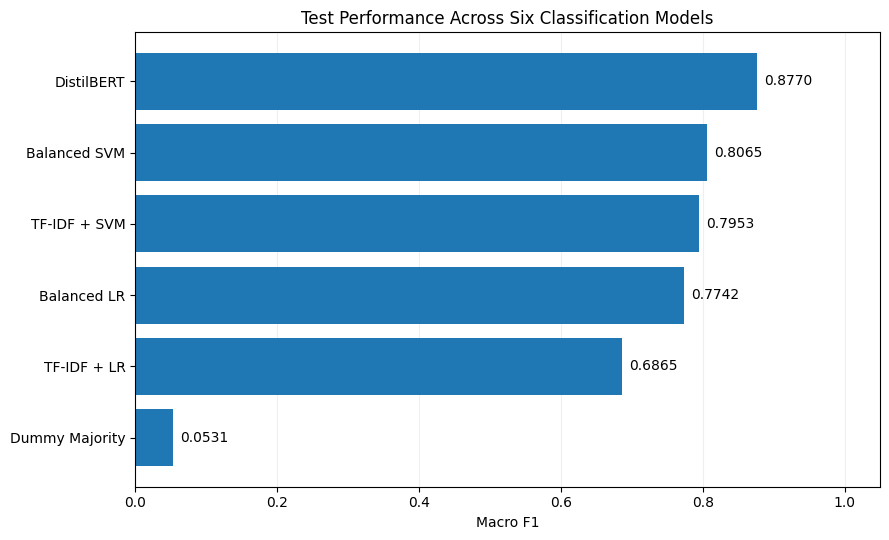

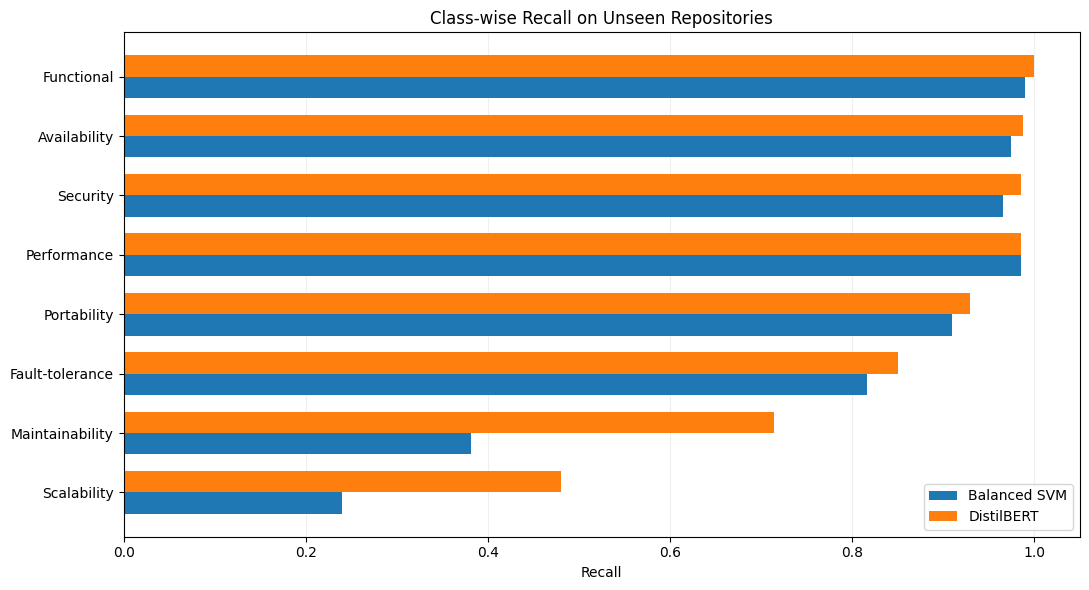

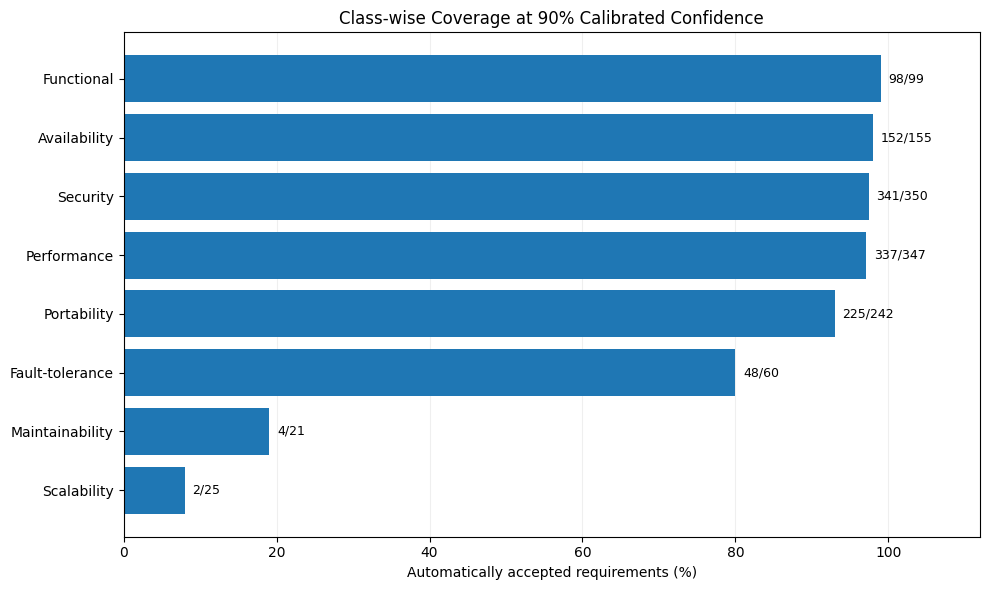


--- OFFICIAL MODEL COMPARISON ---


,model,accuracy,macro_f1,weighted_f1
0,distilbert,0.9561,0.8770,0.9548
1,balanced_linear_svm,0.9330,0.8065,0.9275
2,tfidf_linear_svm,0.9330,0.7953,0.9259
3,balanced_logistic_regression,0.9145,0.7742,0.9095
4,tfidf_logistic_regression,0.9084,0.6865,0.8914
5,dummy_majority,0.2694,0.0531,0.1144



--- BOOTSTRAP INTERVALS ---


,measurement,observed,ci_lower_95,ci_upper_95
0,balanced_svm_macro_f1,0.8065,0.7524,0.8547
1,distilbert_macro_f1,0.8770,0.8301,0.9129
2,distilbert_minus_svm_macro_f1,0.0705,0.0004,0.1338
3,distilbert_minus_svm_accuracy,0.0231,0.0092,0.0385



--- CALIBRATION ---


,method,accuracy,macro_f1,mean_confidence,ECE_10,ECE_5,Brier,NLL
0,raw_softmax,0.9561,0.877,0.9720,0.0184,0.0173,0.0735,0.1895
1,temperature_calibrated,0.9561,0.877,0.9641,0.0166,0.0166,0.0728,0.1847



--- CLASS-WISE 90% CALIBRATED COVERAGE ---


,class_label,total,accepted,class_coverage,accepted_accuracy
22,Scalability,25,2,0.0800,0.0000
19,Maintainability,21,4,0.1905,0.0000
17,Fault-tolerance,60,48,0.8000,0.9583
21,Portability,242,225,0.9298,0.9600
20,Performance,347,337,0.9712,0.9911
23,Security,350,341,0.9743,0.9941
16,Availability,155,152,0.9806,0.9868
18,Functional,99,98,0.9899,1.0000



SECTION 10A — COMPLETED
Figures generated: 3
Paper tables generated: 6
Official models modified: No
Official predictions modified: No
New model inference: No

Paper assets saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/results/paper_assets/section_10a


In [24]:

# ============================================================
# GITREQ RESEARCH
# SECTION 10A — PUBLICATION FIGURES AND RESULTS TABLES
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SECTION 10A — PUBLICATION FIGURES")
print("=" * 65)

# ------------------------------------------------------------
# 1. Define paths and verify frozen analysis
# ------------------------------------------------------------

FINAL_RESULTS_10A = (
    RESULTS_DIR / "final_test_evaluation"
)

ANALYSIS_10A = (
    RESULTS_DIR / "final_test_analysis_9b"
)

OUTPUT_10A = (
    RESULTS_DIR / "paper_assets" / "section_10a"
)

OUTPUT_10A.mkdir(
    parents=True,
    exist_ok=True
)

def file_sha256_10a(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)
    return h.hexdigest()

with open(
    ANALYSIS_10A / "analysis_manifest.json"
) as f:
    manifest_10a = json.load(f)

assert (
    manifest_10a["status"]
    == "OFFICIAL_TEST_ANALYSIS_COMPLETE"
)

official_predictions_10a = (
    FINAL_RESULTS_10A / "official_test_predictions.csv"
)

assert file_sha256_10a(
    official_predictions_10a
) == manifest_10a[
    "official_predictions_sha256"
]

source_files_10a = {
    "comparison": (
        FINAL_RESULTS_10A / "official_model_comparison.csv"
    ),
    "per_class": (
        ANALYSIS_10A / "per_class_comparison.csv"
    ),
    "intervals": (
        ANALYSIS_10A / "bootstrap_confidence_intervals.csv"
    ),
    "calibration": (
        ANALYSIS_10A / "test_calibration_comparison.csv"
    ),
    "coverage": (
        ANALYSIS_10A / "selective_classwise.csv"
    ),
    "overall": (
        ANALYSIS_10A / "selective_overall.csv"
    )
}

for name, path in source_files_10a.items():
    assert path.exists(), f"Missing {name}: {path}"

    # Ensure official Section 9B outputs are unchanged.
    expected = manifest_10a["output_sha256"].get(
        {
            "comparison": "",
            "per_class": "per_class_comparison",
            "intervals": "confidence_intervals",
            "calibration": "calibration",
            "coverage": "selective_classwise",
            "overall": "selective_overall"
        }[name]
    )

    if expected is not None:
        assert file_sha256_10a(path) == expected

comparison_10a = pd.read_csv(
    source_files_10a["comparison"]
)

per_class_10a = pd.read_csv(
    source_files_10a["per_class"]
)

intervals_10a = pd.read_csv(
    source_files_10a["intervals"]
)

calibration_10a = pd.read_csv(
    source_files_10a["calibration"]
)

coverage_10a = pd.read_csv(
    source_files_10a["coverage"]
)

overall_10a = pd.read_csv(
    source_files_10a["overall"]
)

assert len(comparison_10a) == 6
assert len(per_class_10a) == 8

print("\nOfficial research artifacts verified.")
print("No model inference performed.")

# ------------------------------------------------------------
# 2. Figure 1 — Six-model Macro F1
# ------------------------------------------------------------

model_labels_10a = {
    "dummy_majority": "Dummy Majority",
    "tfidf_logistic_regression": "TF-IDF + LR",
    "tfidf_linear_svm": "TF-IDF + SVM",
    "balanced_logistic_regression": "Balanced LR",
    "balanced_linear_svm": "Balanced SVM",
    "distilbert": "DistilBERT"
}

chart_data_10a = (
    comparison_10a.copy()
    .sort_values("macro_f1")
)

chart_data_10a["display_name"] = (
    chart_data_10a["model"]
    .map(model_labels_10a)
)

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.barh(
    chart_data_10a["display_name"],
    chart_data_10a["macro_f1"]
)

ax.bar_label(
    bars,
    fmt="%.4f",
    padding=5
)

ax.set_xlim(0, 1.05)
ax.set_xlabel("Macro F1")
ax.set_title(
    "Test Performance Across Six Classification Models"
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    OUTPUT_10A / "figure_1_model_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 3. Figure 2 — Per-class recall comparison
# ------------------------------------------------------------

class_data_10a = per_class_10a.copy()

class_data_10a = class_data_10a.sort_values(
    "distilbert_recall"
)

positions_10a = np.arange(
    len(class_data_10a)
)

width_10a = 0.36

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    positions_10a - width_10a / 2,
    class_data_10a["svm_recall"],
    height=width_10a,
    label="Balanced SVM"
)

ax.barh(
    positions_10a + width_10a / 2,
    class_data_10a["distilbert_recall"],
    height=width_10a,
    label="DistilBERT"
)

ax.set_yticks(
    positions_10a,
    class_data_10a["class_label"]
)

ax.set_xlim(0, 1.05)
ax.set_xlabel("Recall")

ax.set_title(
    "Class-wise Recall on Unseen Repositories"
)

ax.legend()
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    OUTPUT_10A / "figure_2_classwise_recall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 4. Figure 3 — Class-wise automatic coverage
# ------------------------------------------------------------

class_coverage_10a = coverage_10a.loc[
    (coverage_10a["method"] == "temperature_calibrated")
    & np.isclose(coverage_10a["threshold"], 0.90)
].copy()

assert len(class_coverage_10a) == 8

class_coverage_10a = (
    class_coverage_10a.sort_values(
        "class_coverage"
    )
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    class_coverage_10a["class_label"],
    class_coverage_10a["class_coverage"] * 100
)

for bar, (_, record) in zip(
    bars,
    class_coverage_10a.iterrows()
):
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{int(record['accepted'])}/{int(record['total'])}",
        va="center",
        fontsize=9
    )

ax.set_xlim(0, 112)

ax.set_xlabel(
    "Automatically accepted requirements (%)"
)

ax.set_title(
    "Class-wise Coverage at 90% Calibrated Confidence"
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    OUTPUT_10A / "figure_3_classwise_coverage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. Save consolidated paper tables
# ------------------------------------------------------------

comparison_10a.to_csv(
    OUTPUT_10A / "table_1_model_performance.csv",
    index=False
)

per_class_10a.to_csv(
    OUTPUT_10A / "table_2_per_class_performance.csv",
    index=False
)

intervals_10a.to_csv(
    OUTPUT_10A / "table_3_bootstrap_intervals.csv",
    index=False
)

calibration_10a.to_csv(
    OUTPUT_10A / "table_4_calibration.csv",
    index=False
)

overall_10a.to_csv(
    OUTPUT_10A / "table_5_selective_prediction.csv",
    index=False
)

coverage_10a.to_csv(
    OUTPUT_10A / "table_6_classwise_coverage.csv",
    index=False
)

# ------------------------------------------------------------
# 6. Summary for research paper preparation
# ------------------------------------------------------------

print("\n--- OFFICIAL MODEL COMPARISON ---")

display(
    comparison_10a[
        ["model", "accuracy", "macro_f1", "weighted_f1"]
    ].round(4)
)

print("\n--- BOOTSTRAP INTERVALS ---")

display(
    intervals_10a.round(4)
)

print("\n--- CALIBRATION ---")

display(
    calibration_10a.round(4)
)

print("\n--- CLASS-WISE 90% CALIBRATED COVERAGE ---")

display(
    class_coverage_10a[
        [
            "class_label",
            "total",
            "accepted",
            "class_coverage",
            "accepted_accuracy"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 7. Completion
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("SECTION 10A — COMPLETED")
print("=" * 65)

print("Figures generated: 3")
print("Paper tables generated: 6")
print("Official models modified: No")
print("Official predictions modified: No")
print("New model inference: No")

print("\nPaper assets saved to:")
print(OUTPUT_10A)

print("=" * 65)


In [25]:

# ================================================================
# GITREQ RESEARCH
# SECTION 10B — QUALITATIVE ERROR AUDIT PREPARATION
# ================================================================

import json
import hashlib
import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SECTION 10B — QUALITATIVE ERROR AUDIT")
print("=" * 65)

# ---------------------------------------------------------------
# 1. Verify frozen official predictions
# ---------------------------------------------------------------

PRED_PATH_10B = (
    RESULTS_DIR / "final_test_evaluation"
    / "official_test_predictions.csv"
)

MANIFEST_PATH_10B = (
    RESULTS_DIR / "final_test_evaluation"
    / "official_test_manifest.json"
)

PROTOCOL_PATH_10B = (
    RESULTS_DIR / "final_evaluation_protocol"
    / "final_protocol.json"
)

def sha256_10b(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)

    return h.hexdigest()

with open(MANIFEST_PATH_10B) as f:
    manifest_10b = json.load(f)

with open(PROTOCOL_PATH_10B) as f:
    protocol_10b = json.load(f)

assert manifest_10b["status"] == (
    "OFFICIAL_TEST_PREDICTIONS_FROZEN"
)

assert sha256_10b(PRED_PATH_10B) == (
    manifest_10b["test_predictions_sha256"]
)

assert sha256_10b(PROTOCOL_PATH_10B) == (
    manifest_10b["protocol_sha256"]
)

df_10b = pd.read_csv(PRED_PATH_10B)

assert len(df_10b) == 1299
assert df_10b["requirement_id"].is_unique

CLASSES_10B = protocol_10b["classes"]

SVM_COL_10B = "prediction_balanced_linear_svm"
BERT_COL_10B = "prediction_distilbert"

required_10b = [
    "requirement_id",
    "RequirementText",
    "class_label",
    "repository_id",
    "url",
    SVM_COL_10B,
    BERT_COL_10B,
    "distilbert_calibrated_confidence"
]

assert set(required_10b).issubset(df_10b.columns)

print("\nOfficial prediction fingerprint verified.")
print("Test records:", len(df_10b))
print("No model inference performed.")

# ---------------------------------------------------------------
# 2. Identify all prediction outcomes
# ---------------------------------------------------------------

df_10b["svm_correct"] = (
    df_10b[SVM_COL_10B]
    == df_10b["class_label"]
)

df_10b["bert_correct"] = (
    df_10b[BERT_COL_10B]
    == df_10b["class_label"]
)

conditions_10b = [
    df_10b["svm_correct"] & df_10b["bert_correct"],
    df_10b["svm_correct"] & ~df_10b["bert_correct"],
    ~df_10b["svm_correct"] & df_10b["bert_correct"],
    ~df_10b["svm_correct"] & ~df_10b["bert_correct"]
]

categories_10b = [
    "both_correct",
    "svm_only_correct",
    "distilbert_only_correct",
    "both_wrong"
]

df_10b["prediction_outcome"] = np.select(
    conditions_10b,
    categories_10b,
    default="unclassified"
)

assert not (
    df_10b["prediction_outcome"] == "unclassified"
).any()

outcome_counts_10b = (
    df_10b["prediction_outcome"].value_counts()
)

print("\n--- MODEL AGREEMENT ---")
display(outcome_counts_10b)

# ---------------------------------------------------------------
# 3. Create complete error population
# ---------------------------------------------------------------

errors_10b = df_10b.loc[
    df_10b["prediction_outcome"] != "both_correct"
].copy()

assert len(errors_10b) > 0

bert_errors_10b = errors_10b.loc[
    ~errors_10b["bert_correct"]
].copy()

svm_errors_10b = errors_10b.loc[
    ~errors_10b["svm_correct"]
].copy()

assert len(bert_errors_10b) <= len(errors_10b)
assert len(svm_errors_10b) <= len(errors_10b)

print("\nUnique error cases:", len(errors_10b))
print("DistilBERT errors:", len(bert_errors_10b))
print("Balanced SVM errors:", len(svm_errors_10b))

# ---------------------------------------------------------------
# 4. Breakdown by true requirement category
# ---------------------------------------------------------------

class_outcomes_10b = pd.crosstab(
    df_10b["class_label"],
    df_10b["prediction_outcome"]
)

class_outcomes_10b = (
    class_outcomes_10b.reindex(
        index=CLASSES_10B,
        columns=categories_10b,
        fill_value=0
    )
)

class_outcomes_10b["total"] = (
    class_outcomes_10b.sum(axis=1)
)

class_outcomes_10b["svm_errors"] = (
    class_outcomes_10b["distilbert_only_correct"]
    + class_outcomes_10b["both_wrong"]
)

class_outcomes_10b["distilbert_errors"] = (
    class_outcomes_10b["svm_only_correct"]
    + class_outcomes_10b["both_wrong"]
)

print("\n--- ERROR OUTCOMES BY TRUE CATEGORY ---")
display(class_outcomes_10b)

# ---------------------------------------------------------------
# 5. DistilBERT confusion pairs
# ---------------------------------------------------------------

confusion_pairs_10b = (
    bert_errors_10b
    .groupby(
        ["class_label", BERT_COL_10B]
    )
    .size()
    .reset_index(name="count")
    .sort_values(
        ["count", "class_label"],
        ascending=[False, True]
    )
)

print("\n--- MOST COMMON DISTILBERT CONFUSIONS ---")
display(confusion_pairs_10b.head(15))

# ---------------------------------------------------------------
# 6. High-confidence DistilBERT errors
# ---------------------------------------------------------------

CONFIDENCE_THRESHOLD_10B = 0.90

high_conf_errors_10b = bert_errors_10b.loc[
    bert_errors_10b[
        "distilbert_calibrated_confidence"
    ] >= CONFIDENCE_THRESHOLD_10B
].copy()

high_conf_errors_10b = (
    high_conf_errors_10b.sort_values(
        "distilbert_calibrated_confidence",
        ascending=False
    )
)

assert len(high_conf_errors_10b) <= len(bert_errors_10b)

print("\nHigh-confidence DistilBERT errors:",
      len(high_conf_errors_10b))

display(
    high_conf_errors_10b[
        [
            "requirement_id",
            "class_label",
            BERT_COL_10B,
            "distilbert_calibrated_confidence"
        ]
    ].head(15).round(4)
)

# ---------------------------------------------------------------
# 7. Create a neutral manual-review codebook
# ---------------------------------------------------------------

codebook_10b = pd.DataFrame([
    {
        "code": "OVERLAP",
        "description": (
            "Requirement describes multiple quality attributes "
            "or category meanings overlap."
        )
    },
    {
        "code": "CONTEXT",
        "description": (
            "External repository, issue, or technical context "
            "appears necessary for interpretation."
        )
    },
    {
        "code": "TERMINOLOGY",
        "description": (
            "Technical terminology may suggest an incorrect "
            "category without enough semantic context."
        )
    },
    {
        "code": "MULTITOPIC",
        "description": (
            "Requirement combines different tasks or concerns "
            "within one text."
        )
    },
    {
        "code": "NOISY_TEXT",
        "description": (
            "Formatting, markup, incomplete sentences, or "
            "other text-quality issues complicate reading."
        )
    },
    {
        "code": "POSSIBLE_LABEL_ISSUE",
        "description": (
            "Original annotation may need independent expert "
            "review. This code does not establish an error."
        )
    },
    {
        "code": "UNEXPLAINED",
        "description": (
            "No clear explanation can be identified from "
            "the available requirement text."
        )
    },
    {
        "code": "OTHER",
        "description": (
            "Another explanation documented by the reviewer."
        )
    }
])

# ---------------------------------------------------------------
# 8. Prepare complete manual annotation sheet
# ---------------------------------------------------------------

review_columns_10b = [
    "requirement_id",
    "RequirementText",
    "class_label",
    SVM_COL_10B,
    BERT_COL_10B,
    "svm_correct",
    "bert_correct",
    "prediction_outcome",
    "distilbert_calibrated_confidence",
    "repository_id",
    "url"
]

review_sheet_10b = errors_10b[
    review_columns_10b
].copy()

review_sheet_10b["review_status"] = "unreviewed"
review_sheet_10b["reviewer_theme_code"] = ""
review_sheet_10b["reviewer_explanation"] = ""
review_sheet_10b["needs_independent_label_review"] = ""

review_sheet_10b = review_sheet_10b.sort_values(
    ["class_label", "prediction_outcome", "requirement_id"]
)

# ---------------------------------------------------------------
# 9. Deterministic stratified illustrative sample
# ---------------------------------------------------------------

# Choose up to four cases per true category.
# Sample from different model-outcome groups when possible.
# This sample is for qualitative illustration, not
# for estimating error prevalence.

SAMPLE_SEED_10B = 42

rng_10b = np.random.default_rng(
    SAMPLE_SEED_10B
)

selected_indices_10b = []

outcome_priority_10b = [
    "both_wrong",
    "svm_only_correct",
    "distilbert_only_correct"
]

for label in CLASSES_10B:

    class_pool = review_sheet_10b.loc[
        review_sheet_10b["class_label"] == label
    ]

    chosen = []

    for outcome in outcome_priority_10b:

        subset = class_pool.loc[
            class_pool["prediction_outcome"] == outcome
        ]

        if len(subset) > 0:

            selected = int(
                rng_10b.choice(
                    subset.index.to_numpy()
                )
            )

            chosen.append(selected)

    remaining = class_pool.loc[
        ~class_pool.index.isin(chosen)
    ]

    places_left = max(0, 4 - len(chosen))

    additional = min(
        places_left, len(remaining)
    )

    if additional:

        chosen.extend(
            rng_10b.choice(
                remaining.index.to_numpy(),
                size=additional,
                replace=False
            ).tolist()
        )

    selected_indices_10b.extend(chosen)

illustrative_cases_10b = (
    review_sheet_10b
    .loc[selected_indices_10b]
    .sort_values(
        ["class_label", "requirement_id"]
    )
    .copy()
)

assert illustrative_cases_10b[
    "requirement_id"
].is_unique

print("\n--- STRATIFIED ILLUSTRATIVE CASES ---")
print("Selected:", len(illustrative_cases_10b))

display(
    illustrative_cases_10b[
        [
            "requirement_id",
            "class_label",
            "prediction_outcome",
            SVM_COL_10B,
            BERT_COL_10B
        ]
    ].head(20)
)

# ---------------------------------------------------------------
# 10. Save audit materials
# ---------------------------------------------------------------

OUTPUT_10B = (
    RESULTS_DIR / "paper_assets" / "section_10b"
)

OUTPUT_10B.mkdir(
    parents=True,
    exist_ok=True
)

COMPLETION_10B = OUTPUT_10B / "audit_manifest.json"

assert not COMPLETION_10B.exists(), (
    "An error audit already exists. "
    "Preserve the original audit rather than overwrite it."
)

files_10b = {
    "all_error_cases": (
        OUTPUT_10B / "all_error_cases_review_sheet.csv"
    ),
    "illustrative_cases": (
        OUTPUT_10B / "stratified_illustrative_cases.csv"
    ),
    "high_confidence_errors": (
        OUTPUT_10B / "high_confidence_errors.csv"
    ),
    "class_outcomes": (
        OUTPUT_10B / "error_outcomes_by_class.csv"
    ),
    "confusion_pairs": (
        OUTPUT_10B / "distilbert_confusion_pairs.csv"
    ),
    "codebook": (
        OUTPUT_10B / "manual_review_codebook.csv"
    )
}

review_sheet_10b.to_csv(
    files_10b["all_error_cases"],
    index=False
)

illustrative_cases_10b.to_csv(
    files_10b["illustrative_cases"],
    index=False
)

high_conf_errors_10b.to_csv(
    files_10b["high_confidence_errors"],
    index=False
)

class_outcomes_10b.to_csv(
    files_10b["class_outcomes"]
)

confusion_pairs_10b.to_csv(
    files_10b["confusion_pairs"],
    index=False
)

codebook_10b.to_csv(
    files_10b["codebook"],
    index=False
)

audit_manifest_10b = {
    "section": "10B",
    "status": "AUTOMATED_SCREENING_INPUT_PREPARED",
    "source_prediction_sha256": sha256_10b(
        PRED_PATH_10B
    ),
    "test_requirements": 1299,
    "unique_error_cases": len(review_sheet_10b),
    "distilbert_errors": len(bert_errors_10b),
    "svm_errors": len(svm_errors_10b),
    "high_confidence_distilbert_errors": (
        len(high_conf_errors_10b)
    ),
    "sample_seed": SAMPLE_SEED_10B,
    "sample_cases": len(illustrative_cases_10b),
    "manual_annotations_completed": False,
    "model_retraining": False,
    "official_predictions_modified": False,
    "outputs_sha256": {
        name: sha256_10b(path)
        for name, path in files_10b.items()
    }
}

with COMPLETION_10B.open("x") as f:
    json.dump(
        audit_manifest_10b,
        f,
        indent=4
    )

# ---------------------------------------------------------------
# 11. Final confirmation
# ---------------------------------------------------------------

print("\n" + "=" * 65)
print("SECTION 10B — ERROR AUDIT MATERIALS PREPARED")
print("=" * 65)

print("Total test requirements:", len(df_10b))
print("Unique error cases:", len(review_sheet_10b))
print("Illustrative cases:", len(illustrative_cases_10b))
print(
    "High-confidence DistilBERT errors:",
    len(high_conf_errors_10b)
)

print("Human annotation completed: No")
print("Model inference performed: No")
print("Official predictions modified: No")

print("\nAudit materials saved to:")
print(OUTPUT_10B)

print("=" * 65)


SECTION 10B — QUALITATIVE ERROR AUDIT

Official prediction fingerprint verified.
Test records: 1299
No model inference performed.

--- MODEL AGREEMENT ---


,count
prediction_outcome,
both_correct,1197
distilbert_only_correct,45
both_wrong,42
svm_only_correct,15



Unique error cases: 102
DistilBERT errors: 57
Balanced SVM errors: 87

--- ERROR OUTCOMES BY TRUE CATEGORY ---


prediction_outcome,both_correct,svm_only_correct,distilbert_only_correct,both_wrong,total,svm_errors,distilbert_errors
class_label,,,,,,,
Availability,151,0,2,2,155,4,2
Fault-tolerance,48,1,3,8,60,11,9
Functional,98,0,1,0,99,1,0
Maintainability,7,1,8,5,21,13,6
Performance,338,4,4,1,347,5,5
Portability,216,4,9,13,242,22,17
Scalability,3,3,9,10,25,19,13
Security,336,2,9,3,350,12,5



--- MOST COMMON DISTILBERT CONFUSIONS ---


...


High-confidence DistilBERT errors: 24


,requirement_id,class_label,prediction_distilbert,distilbert_calibrated_confidence
823,GR03927,Performance,Security,0.9923
906,GR04341,Portability,Security,0.9918
833,GR03947,Portability,Security,0.9909
404,GR01915,Fault-tolerance,Performance,0.9907
1149,GR05528,Maintainability,Performance,0.9876
583,GR02802,Portability,Security,0.9857
1138,GR05486,Portability,Security,0.9842
286,GR01337,Security,Performance,0.9833
1039,GR05019,Scalability,Performance,0.9817
1077,GR05212,Portability,Functional,0.9817



--- STRATIFIED ILLUSTRATIVE CASES ---
Selected: 29


,requirement_id,class_label,prediction_outcome,prediction_balanced_linear_svm,prediction_distilbert
86,GR00400,Availability,both_wrong,Functional,Fault-tolerance
184,GR00821,Availability,distilbert_only_correct,Functional,Availability
329,GR01560,Availability,both_wrong,Portability,Portability
717,GR03384,Availability,distilbert_only_correct,Scalability,Availability
43,GR00222,Fault-tolerance,both_wrong,Availability,Availability
404,GR01915,Fault-tolerance,svm_only_correct,Fault-tolerance,Performance
672,GR03207,Fault-tolerance,distilbert_only_correct,Availability,Fault-tolerance
749,GR03511,Fault-tolerance,both_wrong,Portability,Portability
1216,GR05867,Functional,distilbert_only_correct,Security,Functional
104,GR00455,Maintainability,distilbert_only_correct,Portability,Maintainability



SECTION 10B — ERROR AUDIT MATERIALS PREPARED
Total test requirements: 1299
Unique error cases: 102
Illustrative cases: 29
High-confidence DistilBERT errors: 24
Human annotation completed: No
Model inference performed: No
Official predictions modified: No

Audit materials saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/results/paper_assets/section_10b


In [26]:

# ================================================================
# GITREQ RESEARCH
# SECTION 10C — FULLY AUTOMATED ERROR SCREENING
# ================================================================
# No manual input
# No paid APIs
# No model retraining
# No changes to official predictions
#
# IMPORTANT:
# This is automated descriptive analysis, NOT human annotation.
# ================================================================

import re
import json
import hashlib
import pandas as pd
import numpy as np

from pathlib import Path
from collections import Counter
from IPython.display import display

print("=" * 65)
print("SECTION 10C — AUTOMATED ERROR SCREENING")
print("=" * 65)

# ---------------------------------------------------------------
# 1. Paths
# ---------------------------------------------------------------

SOURCE_DIR_10C = (
    RESULTS_DIR / "paper_assets" / "section_10b"
)

OUTPUT_DIR_10C = (
    RESULTS_DIR / "paper_assets"
    / "section_10c_automated"
)

ALL_ERRORS_PATH_10C = (
    SOURCE_DIR_10C / "all_error_cases_review_sheet.csv"
)

SAMPLE_PATH_10C = (
    SOURCE_DIR_10C / "stratified_illustrative_cases.csv"
)

AUDIT_MANIFEST_PATH_10C = (
    SOURCE_DIR_10C / "audit_manifest.json"
)

OFFICIAL_PRED_PATH_10C = (
    RESULTS_DIR / "final_test_evaluation"
    / "official_test_predictions.csv"
)

OUTPUT_DIR_10C.mkdir(
    parents=True,
    exist_ok=True
)

COMPLETE_PATH_10C = (
    OUTPUT_DIR_10C / "automated_audit_manifest.json"
)

# ---------------------------------------------------------------
# 2. File verification
# ---------------------------------------------------------------

def sha256_10c(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)

    return h.hexdigest()


with open(AUDIT_MANIFEST_PATH_10C) as f:
    audit_manifest_10c = json.load(f)

assert sha256_10c(ALL_ERRORS_PATH_10C) == (
    audit_manifest_10c["outputs_sha256"]["all_error_cases"]
)

assert sha256_10c(SAMPLE_PATH_10C) == (
    audit_manifest_10c["outputs_sha256"]["illustrative_cases"]
)

assert sha256_10c(OFFICIAL_PRED_PATH_10C) == (
    audit_manifest_10c["source_prediction_sha256"]
)

# Safe to rerun: validate the existing completed audit.
if COMPLETE_PATH_10C.exists():

    with open(COMPLETE_PATH_10C) as f:
        existing_10c = json.load(f)

    assert existing_10c["source_prediction_sha256"] == (
        sha256_10c(OFFICIAL_PRED_PATH_10C)
    )

    for name, expected_hash in existing_10c[
        "output_sha256"
    ].items():

        path = OUTPUT_DIR_10C / name

        assert path.exists()
        assert sha256_10c(path) == expected_hash

    print("\nAutomated audit already completed and verified.")
    print("Existing outputs preserved.")
    print("Folder:", OUTPUT_DIR_10C)

else:

    # -----------------------------------------------------------
    # 3. Read source data
    # -----------------------------------------------------------

    errors_10c = pd.read_csv(
        ALL_ERRORS_PATH_10C
    )

    sample_10c = pd.read_csv(
        SAMPLE_PATH_10C
    )

    assert len(errors_10c) > 0
    assert len(sample_10c) > 0

    assert errors_10c["requirement_id"].is_unique
    assert sample_10c["requirement_id"].is_unique

    assert set(
        sample_10c["requirement_id"]
    ).issubset(
        set(errors_10c["requirement_id"])
    )

    assert errors_10c["RequirementText"].notna().all()

    print("\nSource records verified.")
    print("Complete error population:", len(errors_10c))
    print("Illustrative sample:", len(sample_10c))

    # -----------------------------------------------------------
    # 4. Define transparent lexical evidence rules
    # -----------------------------------------------------------

    # These patterns detect language associated with software
    # quality categories. They are not trained classifiers.
    #
    # A matched term does not prove the actual category.

    CUE_RULES_10C = {

        "Availability": [
            r"\bavailability\b",
            r"\bunavailable\b",
            r"\bdowntime\b",
            r"\buptime\b",
            r"\boutage\b",
            r"\bservice interruption\b"
        ],

        "Fault-tolerance": [
            r"\bfault tolerance\b",
            r"\bfault-toleran\w*\b",
            r"\bgraceful shutdown\b",
            r"\brecover(?:y|ing)?\b",
            r"\bfallback\b",
            r"\bbackup\b",
            r"\bredundan\w*\b",
            r"\bretr(?:y|ies)\b"
        ],

        "Functional": [
            r"\buser(?:s)? can\b",
            r"\ballow users\b",
            r"\bdisplay\b",
            r"\brender\b",
            r"\buser interface\b",
            r"\bnew feature\b",
            r"\bimplement a feature\b"
        ],

        "Maintainability": [
            r"\bmaintainab\w*\b",
            r"\brefactor\w*\b",
            r"\bdocumentation\b",
            r"\bdecoupl\w*\b",
            r"\bcode quality\b",
            r"\bmodular\w*\b",
            r"\btechnical debt\b"
        ],

        "Performance": [
            r"\bperformance\b",
            r"\blatency\b",
            r"\bthroughput\b",
            r"\boptimi[sz]\w*\b",
            r"\bcach(?:e|ing)\b",
            r"\bbottleneck\b",
            r"\bparallel\w*\b",
            r"\bcpu\b",
            r"\bresponse time\b"
        ],

        "Portability": [
            r"\bportab\w*\b",
            r"\bcompatib\w*\b",
            r"\bcross.platform\b",
            r"\bmigrat\w*\b",
            r"\boperating system\b",
            r"\bdocker\b",
            r"\blinux\b",
            r"\bwindows\b",
            r"\bmacos\b"
        ],

        "Scalability": [
            r"\bscalab\w*\b",
            r"\bscal(?:e|es|ing)\b",
            r"\bconcurren\w*\b",
            r"\bhorizontal scaling\b",
            r"\bdistributed\b",
            r"\bload balancing\b",
            r"\bincreasing workload\b",
            r"\bmultiple instances\b"
        ],

        "Security": [
            r"\bsecur\w*\b",
            r"\bauthenticat\w*\b",
            r"\bauthori[sz]\w*\b",
            r"\bvulnerabilit\w*\b",
            r"\bencrypt\w*\b",
            r"\bpassword\b",
            r"\bcredential\w*\b",
            r"\binjection\b",
            r"\baccess control\b",
            r"\bcertificate\b",
            r"\btls\b",
            r"\bfingerprint verification\b"
        ]
    }

    COMPILED_CUES_10C = {
        category: [
            re.compile(pattern, flags=re.IGNORECASE)
            for pattern in patterns
        ]
        for category, patterns in CUE_RULES_10C.items()
    }

    # -----------------------------------------------------------
    # 5. Automatic text screening
    # -----------------------------------------------------------

    def screen_text_10c(text):

        text = str(text)

        words = re.findall(
            r"\b[\w'-]+\b",
            text
        )

        word_count = len(words)

        matches = {}

        for category, patterns in COMPILED_CUES_10C.items():

            found = set()

            for pattern in patterns:

                for match in pattern.finditer(text):

                    found.add(
                        match.group(0).strip().lower()
                    )

            if found:
                matches[category] = sorted(found)

        matched_categories = list(matches.keys())

        # Observable text-quality and context signals.
        contains_url = bool(
            re.search(r"https?://", text, re.IGNORECASE)
        )

        context_reference = bool(
            re.search(
                r"\b(?:above|below|as discussed|"
                r"see attached|previous issue|this issue)\b",
                text,
                re.IGNORECASE
            )
        )

        formatting_signal = bool(
            re.search(
                r"(?:```|<[^>]+>|[{}]{2,}|"
                r"\bTODO\b)",
                text,
                re.IGNORECASE
            )
        )

        flags = []

        if len(matched_categories) >= 2:
            flags.append("MULTIPLE_CUE_FAMILIES")

        if len(matched_categories) == 0:
            flags.append("NO_MATCHED_LEXICAL_CUES")

        if word_count < 15:
            flags.append("SHORT_TEXT")

        if word_count > 250:
            flags.append("LONG_TEXT")

        if context_reference:
            flags.append("CONTEXT_REFERENCE")

        if formatting_signal:
            flags.append("FORMATTING_SIGNAL")

        if contains_url:
            flags.append("EMBEDDED_URL")

        # Evidence-based explanation:
        # Reports literal matched language only.
        # Does not infer a verified cause or correct label.

        if matches:

            evidence_parts = []

            for category, terms in matches.items():

                evidence_parts.append(
                    f"{category}: {', '.join(terms[:5])}"
                )

            evidence = "; ".join(evidence_parts)

            explanation = (
                "Lexical evidence detected: "
                + evidence
                + ". These terms indicate possible topics "
                "but do not establish the correct label."
            )

        else:

            evidence = ""

            explanation = (
                "No predefined quality-category cues "
                "were detected. This does not mean "
                "the text lacks quality requirements."
            )

        if len(matched_categories) >= 2:

            explanation += (
                " Multiple cue families occur in the "
                "same text; possible overlap requires "
                "semantic interpretation."
            )

        if context_reference:

            explanation += (
                " The text contains a reference that may "
                "depend on external context."
            )

        if word_count < 15:

            explanation += (
                " The description is short and may "
                "provide limited context."
            )

        return {
            "word_count": word_count,
            "matched_cue_family_count": len(
                matched_categories
            ),
            "matched_cue_families": " | ".join(
                matched_categories
            ),
            "matched_terms": evidence,
            "screening_flags": " | ".join(flags),
            "flag_count": len(flags),
            "automated_explanation": explanation
        }

    # -----------------------------------------------------------
    # 6. Screen without exposing gold labels or predictions
    # -----------------------------------------------------------

    blind_texts_10c = errors_10c[
        ["requirement_id", "RequirementText"]
    ].copy()

    screening_records_10c = []

    for _, row in blind_texts_10c.iterrows():

        result = screen_text_10c(
            row["RequirementText"]
        )

        screening_records_10c.append({
            "requirement_id": row["requirement_id"],
            "RequirementText": row["RequirementText"],
            **result
        })

    screened_10c = pd.DataFrame(
        screening_records_10c
    )

    assert len(screened_10c) == len(errors_10c)
    assert screened_10c["requirement_id"].is_unique

    # -----------------------------------------------------------
    # 7. Join frozen results for descriptive error analysis
    # -----------------------------------------------------------

    # This occurs AFTER text screening.
    # Gold labels and model predictions cannot influence
    # the lexical screening rules or their outputs.

    metadata_columns_10c = [
        "requirement_id",
        "class_label",
        "prediction_balanced_linear_svm",
        "prediction_distilbert",
        "prediction_outcome",
        "distilbert_calibrated_confidence"
    ]

    analysis_10c = screened_10c.merge(
        errors_10c[metadata_columns_10c],
        on="requirement_id",
        how="left",
        validate="one_to_one"
    )

    assert len(analysis_10c) == len(errors_10c)

    analysis_10c["illustrative_sample"] = (
        analysis_10c["requirement_id"].isin(
            sample_10c["requirement_id"]
        )
    )

    illustrative_10c = analysis_10c.loc[
        analysis_10c["illustrative_sample"]
    ].copy()

    assert len(illustrative_10c) == len(sample_10c)

    # -----------------------------------------------------------
    # 8. Count detected screening flags
    # -----------------------------------------------------------

    all_flags_10c = []

    for value in analysis_10c["screening_flags"]:

        if value:

            all_flags_10c.extend(
                value.split(" | ")
            )

    flag_counts_10c = Counter(all_flags_10c)

    flag_summary_10c = pd.DataFrame(
        [
            {
                "flag": flag,
                "error_cases": count,
                "percent_of_screened_errors": (
                    100 * count / len(analysis_10c)
                )
            }
            for flag, count in flag_counts_10c.items()
        ]
    )

    if len(flag_summary_10c):

        flag_summary_10c = (
            flag_summary_10c.sort_values(
                "error_cases",
                ascending=False
            )
        )

    # -----------------------------------------------------------
    # 9. Descriptive summary by recorded category
    # -----------------------------------------------------------

    class_summary_10c = (
        analysis_10c.groupby("class_label")
        .agg(
            error_cases=("requirement_id", "count"),
            mean_word_count=("word_count", "mean"),
            mean_matched_cue_families=(
                "matched_cue_family_count", "mean"
            ),
            cases_with_multiple_cue_families=(
                "matched_cue_family_count",
                lambda x: int((x >= 2).sum())
            )
        )
        .reset_index()
    )

    # -----------------------------------------------------------
    # 10. Save reports
    # -----------------------------------------------------------

    output_files_10c = {
        "all_error_cases_automated_screening.csv": analysis_10c,
        "illustrative_screening.csv": illustrative_10c,
        "screening_flag_summary.csv": flag_summary_10c,
        "error_category_screening_summary.csv": class_summary_10c
    }

    for filename, dataframe in output_files_10c.items():

        path = OUTPUT_DIR_10C / filename

        if path.exists():
            raise RuntimeError(
                f"Unexpected existing output: {path}. "
                "Preserve it and inspect before proceeding."
            )

        dataframe.to_csv(
            path,
            index=False
        )

    config_10c = {
        "section": "10C",
        "status": "AUTOMATED_SCREENING_COMPLETE",
        "analysis_type": "rule_based_lexical_screening",
        "screened_error_cases": len(analysis_10c),
        "illustrative_cases": len(illustrative_10c),
        "manual_human_annotation_performed": False,
        "new_model_training": False,
        "new_model_inference": False,
        "official_predictions_modified": False,
        "previous_interactive_reviews_modified": False,
        "source_prediction_sha256": (
            sha256_10c(OFFICIAL_PRED_PATH_10C)
        ),
        "interpretation_warning": (
            "Text cues and screening flags are descriptive "
            "heuristics, not validated semantic explanations, "
            "corrected annotations, or human judgments. "
            "Results concern model-error cases only."
        ),
        "output_sha256": {
            filename: sha256_10c(
                OUTPUT_DIR_10C / filename
            )
            for filename in output_files_10c
        }
    }

    with COMPLETE_PATH_10C.open("x") as f:

        json.dump(
            config_10c,
            f,
            indent=4
        )

    # -----------------------------------------------------------
    # 11. Display automatic results
    # -----------------------------------------------------------

    print("\n--- AUTOMATED SCREENING FLAGS ---")

    display(
        flag_summary_10c.round(2)
    )

    print("\n--- SCREENING BY ORIGINAL CATEGORY ---")

    display(
        class_summary_10c.round(2)
    )

    print("\n--- ILLUSTRATIVE CASES ---")

    display(
        illustrative_10c[
            [
                "requirement_id",
                "class_label",
                "matched_cue_families",
                "screening_flags"
            ]
        ].reset_index(drop=True)
    )

    print("\n" + "=" * 65)
    print("SECTION 10C — COMPLETED AUTOMATICALLY")
    print("=" * 65)

    print("Error cases screened:", len(analysis_10c))
    print("Illustrative cases:", len(illustrative_10c))
    print("Manual inputs required: 0")
    print("Manual annotations claimed: 0")

    print("\nOfficial predictions modified: No")
    print("Original interactive reviews modified: No")

    print("\nReports saved to:")
    print(OUTPUT_DIR_10C)

    print("=" * 65)


SECTION 10C — AUTOMATED ERROR SCREENING

Source records verified.
Complete error population: 102
Illustrative sample: 29

--- AUTOMATED SCREENING FLAGS ---


,flag,error_cases,percent_of_screened_errors
1,NO_MATCHED_LEXICAL_CUES,31,30.39
0,MULTIPLE_CUE_FAMILIES,25,24.51
2,CONTEXT_REFERENCE,9,8.82
3,SHORT_TEXT,5,4.90
4,EMBEDDED_URL,2,1.96
5,FORMATTING_SIGNAL,2,1.96



--- SCREENING BY ORIGINAL CATEGORY ---


,class_label,error_cases,mean_word_count,mean_matched_cue_families,cases_with_multiple_cue_families
0,Availability,4,42.75,2.25,2
1,Fault-tolerance,12,43.08,1.00,3
2,Functional,1,33.00,0.00,0
3,Maintainability,14,41.93,0.71,2
4,Performance,9,59.44,1.67,4
5,Portability,26,48.46,0.81,5
6,Scalability,22,38.45,0.95,5
7,Security,14,60.86,1.14,4



--- ILLUSTRATIVE CASES ---


,requirement_id,class_label,matched_cue_families,screening_flags
0,GR00400,Availability,Availability | Fault-tolerance,MULTIPLE_CUE_FAMILIES
1,GR01560,Availability,Availability,
2,GR00821,Availability,Availability,
3,GR03384,Availability,Availability | Fault-tolerance | Maintainabili...,MULTIPLE_CUE_FAMILIES
4,GR00222,Fault-tolerance,Fault-tolerance,
5,GR03511,Fault-tolerance,Fault-tolerance | Performance,MULTIPLE_CUE_FAMILIES
6,GR03207,Fault-tolerance,Fault-tolerance,
7,GR01915,Fault-tolerance,Performance,
8,GR05867,Functional,,NO_MATCHED_LEXICAL_CUES | CONTEXT_REFERENCE
9,GR00783,Maintainability,Maintainability,



SECTION 10C — COMPLETED AUTOMATICALLY
Error cases screened: 102
Illustrative cases: 29
Manual inputs required: 0
Manual annotations claimed: 0

Official predictions modified: No
Original interactive reviews modified: No

Reports saved to:
/content/drive/MyDrive/GitReq_Reproduction_Run01/results/paper_assets/section_10c_automated


Macro F1: 0.0705 [0.0004, 0.1338]
Accuracy: 0.0231 [0.0092, 0.0385]


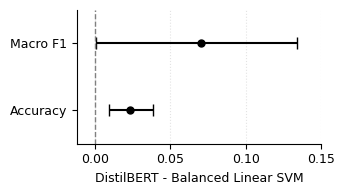

Saved PNG: /content/drive/MyDrive/GitReq_Reproduction_Run01/results/final_test_analysis_9b/bootstrap_ci.png
Saved PDF: /content/drive/MyDrive/GitReq_Reproduction_Run01/results/final_test_analysis_9b/bootstrap_ci.pdf


In [27]:

# ============================================================
# FIGURE 3 — BOOTSTRAP CONFIDENCE INTERVALS
# GitReq Research — Reproducible Paper Figure
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Load saved experiment results
result_dir = RESULTS_DIR / "final_test_analysis_9b"

csv_path = result_dir / "bootstrap_confidence_intervals.csv"

if not csv_path.exists():
    raise FileNotFoundError(f"Missing results: {csv_path}")

df = pd.read_csv(csv_path).set_index("measurement")

# 2. Select the two model-comparison metrics
keys = [
    "distilbert_minus_svm_macro_f1",
    "distilbert_minus_svm_accuracy"
]

labels = ["Macro F1", "Accuracy"]
positions = [1, 0]

fig, ax = plt.subplots(figsize=(3.55, 2.05))

# 3. Plot observed differences and 95% intervals
for label, key, y in zip(labels, keys, positions):

    row = df.loc[key]

    estimate = float(row["observed"])
    lower = float(row["ci_lower_95"])
    upper = float(row["ci_upper_95"])

    assert lower <= estimate <= upper

    ax.errorbar(
        estimate,
        y,
        xerr=[
            [estimate - lower],
            [upper - estimate]
        ],
        fmt="o",
        color="black",
        ecolor="black",
        markersize=5,
        elinewidth=1.5,
        capsize=4
    )

    print(
        f"{label}: {estimate:.4f} "
        f"[{lower:.4f}, {upper:.4f}]"
    )

# Zero = no performance difference
ax.axvline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_yticks(positions)
ax.set_yticklabels(labels)

ax.set_xlim(-0.012, 0.15)
ax.set_ylim(-0.5, 1.5)

ax.set_xticks([0, 0.05, 0.10, 0.15])

ax.set_xlabel(
    "DistilBERT - Balanced Linear SVM",
    fontsize=9
)

ax.tick_params(axis="both", labelsize=9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    linestyle=":",
    alpha=0.35
)

plt.tight_layout()

# 4. Save directly to your Google Drive
png_path = result_dir / "bootstrap_ci.png"
pdf_path = result_dir / "bootstrap_ci.pdf"

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Saved PNG:", png_path)
print("Saved PDF:", pdf_path)
